In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

FIG_SIZE = (10, 8)
SIZE = 11
SIZE_SMALL = 9
FONT_SIZE = int(SIZE)
FONT_SIZE_SMALL = int(SIZE_SMALL)
FONT_WEIGHT = "normal"
MARKER_SIZE = 5
LINE_WIDTH = 1.2
GRID = True
ERRORBAR = ("ci", 95)

PLOT_DPI = 600
PLOT_FORMAT = "pdf"
SHOW_FIGURE_TITLES = True
OPTIMALITY_DISPLAY = "ratio"  # "ratio" or "percent"
if OPTIMALITY_DISPLAY not in {"ratio", "percent"}:
    raise ValueError('OPTIMALITY_DISPLAY must be "ratio" or "percent"')
OPTIMALITY_LABEL = ("SCI / optimum [×]" if OPTIMALITY_DISPLAY == "ratio"
                    else "SCI gap from optimum [%]")
SHARE_Y = "row"  # "row": same scale per row; True: same scale for the entire figure

rc = {
    "figure.figsize": FIG_SIZE,
    "figure.titlesize": 13,
    "axes.labelsize": FONT_SIZE,
    "axes.labelweight": FONT_WEIGHT,
    "legend.fontsize": FONT_SIZE_SMALL,
    "legend.title_fontsize": FONT_SIZE_SMALL,
    "xtick.labelsize": FONT_SIZE,
    "ytick.labelsize": FONT_SIZE,
    "lines.markersize": MARKER_SIZE,
    "lines.linewidth": LINE_WIDTH,
    "axes.titlesize": FONT_SIZE_SMALL,
    "axes.grid": GRID,
    "axes.labelpad": 5,
    "axes.titlepad": 8,
    "legend.labelspacing": 0.4,
}

sns.set_theme(style="whitegrid", palette="colorblind", context="paper", rc=rc)

# Placement heuristic analysis

Compare measured SCI, network contribution, runtime and node use across application and infrastructure dimensions. Known-optimum comparisons are available only for controlled scenarios. PDF figures are saved under `results/plots/<EXPERIMENT_NAME>/`.

Set `OPTIMALITY_DISPLAY = "ratio"` for SCI/optimum (1× means optimal), or `"percent"` for percentage excess (0% means optimal). The absolute-gap plots remain in gCO2eq/FU. Relative plots use distinct filenames for the two representations.


In [80]:
from pathlib import Path

import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from IPython.display import display

WORKING_DIR = Path.cwd()
PROJECT_DIR = (
    WORKING_DIR
    if (WORKING_DIR / "sci_aware_msa_placement").is_dir()
    else WORKING_DIR.parent.parent
)
EXPERIMENT_NAME = "network-sci-controlled-v2"
RESULTS_DIR = PROJECT_DIR / "results"
PARQUET_PATH = RESULTS_DIR / "parquets" / EXPERIMENT_NAME / "raw-sci-aware.parquet"
PLOTS_DIR = RESULTS_DIR / "plots" / EXPERIMENT_NAME
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


def save_plot(name, figure=None, title=None):
    if figure is None:
        figure = plt.gcf()
    if SHOW_FIGURE_TITLES:
        figure.suptitle(title or name.replace("-", " ").capitalize(), y=0.995)
        figure.tight_layout(rect=(0, 0, 1, 0.96))
    else:
        figure.tight_layout()
    path = PLOTS_DIR / f"{name}.{PLOT_FORMAT}"
    figure.savefig(path, dpi=PLOT_DPI, bbox_inches="tight")
    plt.show()
    plt.close(figure)
    print(f"Saved: {path}")

def set_y_range(ax, values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    maximum = values.max() if len(values) else 0
    if maximum > 0:
        ax.set_ylim(0, maximum * 1.1)
    else:
        ax.set_ylim(-1e-6, 1e-6)
        ax.set_yticks([0])


def facet_plot(frame, metric, ylabel, name, x, hue=None, row=None, col=None):
    if frame.empty:
        return
    if SHARE_Y is not True and SHARE_Y != "row":
        raise ValueError('SHARE_Y must be "row" or True')
    hue_values = sorted(frame[hue].dropna().unique(), key=str) if hue else []
    colors = dict(zip(hue_values, sns.color_palette("husl", len(hue_values)), strict=True))
    g = sns.catplot(
        data=frame, x=x, y=metric, hue=hue, row=row, col=col,
        kind="box", height=3.6, aspect=1.25, sharey=SHARE_Y,
        legend=False, margin_titles=True,
        hue_order=hue_values if hue else None, palette=colors if hue else None,
    )
    g.set_axis_labels({"heuristic_plot": "Heuristic", "heuristic_label": "Heuristic",
                       "app_topology": "Application topology",
                       "network_topology": "Network topology",
                       "application_size": "Services", "top_k": "K"}.get(
                           x, x.replace("_", " ").title()), ylabel)
    col_title = {"application_size": "{col_name} services",
                 "infrastructure_size": "{col_name} nodes"}.get(col, "{col_name}")
    g.set_titles(row_template="{row_name}", col_template=col_title)
    panels = {}
    for (ri, ci, _), subset in g.facet_data():
        panels.setdefault((ri, ci), []).append(subset[metric])
    scale_groups = {}
    for (ri, ci), series in panels.items():
        key = ri if SHARE_Y == "row" else 0
        scale_groups.setdefault(key, []).extend(series)
    for key, series in scale_groups.items():
        values = pd.concat(series)
        if not values.empty:
            representative = g.axes[key, 0] if SHARE_Y == "row" else g.axes.flat[0]
            if metric == "optimality_comparison" and OPTIMALITY_DISPLAY == "ratio" and (values.dropna() == 1).all():
                representative.set_ylim(1 - 1e-6, 1 + 1e-6)
                representative.set_yticks([1])
            else:
                set_y_range(representative, values)
    for (ri, ci), series in panels.items():
        values = pd.concat(series).dropna()
        ax = g.axes[ri, ci]
        if metric == "optimality_comparison" and OPTIMALITY_DISPLAY == "ratio":
            ax.axhline(1, color="black", linestyle="--", linewidth=0.8)
            ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(
                lambda value, position: f"{value:g}×"))
            if not values.empty and (values == 1).all():
                ax.text(0.5, 0.9, "All values = 1×", transform=ax.transAxes,
                        ha="center", fontsize=10)
        if values.empty:
            ax.text(0.5, 0.5, "No trials", transform=ax.transAxes,
                    ha="center", fontsize=10)
            ax.tick_params(axis="y", labelleft=False)
        elif (values == 0).all():
            ax.text(0.5, 0.9, "All values = 0", transform=ax.transAxes,
                    ha="center", fontsize=10)
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=90, # rotation=55 if "heuristic" in x else 0, 
                       labelsize=8)
    if hue:
        g.figure.legend(
            handles=[Patch(facecolor=colors[value], label=value) for value in hue_values],
            title={"scope_label": "Scope", "heuristic_plot": "Heuristic"}.get(
                hue, hue.replace("_", " ").title()),
            loc="center left", bbox_to_anchor=(1.02, 0.5),
        )
    g.figure.tight_layout()
    dimensions = {
        "heuristic_plot": "heuristic", "heuristic_label": "weight combination",
        "heuristic_name": "heuristic family", "app_topology": "application topology",
        "application_size": "application size", "network_topology": "network topology",
        "infrastructure_topology": "network topology", "infrastructure_size": "network size",
        "scope_label": "scope", "top_k": "K", "value_type": "measured vs optimal",
        "contribution": "SCI contribution",
    }
    axes = list(dict.fromkeys(dimensions.get(dim, dim) for dim in (x, row, col, hue) if dim))
    title = f"{ylabel} by {', '.join(axes)}"
    if name.startswith("scope-comparison-"):
        title += f" — {frame['heuristic_plot'].iloc[0]}"
    save_plot(name, g.figure, title=title)


## Loading and preparation

Successful trials include the heuristic SCI; controlled trials also include the known optimum from the fit placement. `optimal_sci` already matches each trial's scope: components only, or components plus network. Failed trials remain available for the failure summary but are excluded from SCI plots.


In [81]:
if not PARQUET_PATH.exists():
    raise FileNotFoundError(f"Results file not found: {PARQUET_PATH}")
results = pd.read_parquet(PARQUET_PATH)
required_columns = {
    "success",
    "heuristic",
    "heuristic_name",
    "scope",
    "component_operational_sci",
    "component_embodied_sci",
    "network_operational_sci",
    "network_embodied_sci",
    "optimal_component_operational_sci",
    "optimal_component_embodied_sci",
    "optimal_network_operational_sci",
    "optimal_network_embodied_sci",
    "optimal_components_only_sci",
    "optimal_components_and_network_sci",
    "optimal_sci",
    "time",
    "nodes_used",
}
missing_columns = required_columns - set(results.columns)
assert not missing_columns, (
    f"Missing columns: {sorted(missing_columns)}. "
    "Use a Parquet generated by the experiment runner."
)

failed = results.loc[~results["success"]].copy()
failed["scenario_mode"] = failed.get("scenario_mode", "controlled")
data = results.loc[results["success"]].copy()
assert not data.empty, "No successful experiments found"
data["scenario_mode"] = data.get("scenario_mode", "controlled")
controlled_rows = data["scenario_mode"].eq("controlled")
assert data.loc[controlled_rows, "optimal_sci"].notna().all(), "Controlled trials lack optimal_sci"
for column in ["optimal_sci", "optimal_components_only_sci", "optimal_components_and_network_sci"]:
    data[column] = pd.to_numeric(data[column], errors="raise")

data["component_sci"] = (
    data["component_operational_sci"] + data["component_embodied_sci"]
)
data["network_sci"] = (
    data["network_operational_sci"] + data["network_embodied_sci"]
)
data["total_sci"] = data["component_sci"] + data["network_sci"]
data["objective_sci"] = np.where(
    data["scope"] == "components_only",
    data["component_sci"],
    data["total_sci"],
)
scope_reference = np.where(
    data["scope"] == "components_only",
    data["optimal_components_only_sci"],
    data["optimal_components_and_network_sci"],
)
assert np.allclose(data["optimal_sci"], scope_reference, equal_nan=True), (
    "optimal_sci does not match the reference total for the configured scope"
)

data["optimality_gap_pct"] = np.where(
    data["optimal_sci"] > 0,
    100 * (data["objective_sci"] / data["optimal_sci"] - 1),
    np.where(data["objective_sci"] == 0, 0.0, np.nan),
)
same_as_optimum = np.isclose(
    data["objective_sci"], data["optimal_sci"], rtol=1e-10, atol=1e-12
)
data.loc[same_as_optimum, "optimality_gap_pct"] = 0.0
data["optimality_ratio"] = np.where(
    data["optimal_sci"] > 0,
    data["objective_sci"] / data["optimal_sci"],
    np.where(data["objective_sci"] == 0, 1.0, np.nan),
)
data.loc[same_as_optimum, "optimality_ratio"] = 1.0
data["optimality_comparison"] = data[
    "optimality_ratio" if OPTIMALITY_DISPLAY == "ratio" else "optimality_gap_pct"
]

controlled = data.loc[data["heuristic_name"] == "controlled"]
if not controlled.empty:
    assert np.allclose(
        controlled["objective_sci"], controlled["optimal_sci"],
        rtol=1e-10, atol=1e-12,
    ), "The controlled heuristic must match its stored optimal_sci reference"

data["objective_sci_g"] = data["objective_sci"] * 1000
data["scope_label"] = data["scope"].map({
    "components_only": "Components only",
    "components_and_network": "Components + network",
})
topology_label = data["infrastructure_topology"].map({
    "erdos_renyi": "ER",
    "barabasi_albert": "BA",
    "internet_as_graph": "IAAG",
})
data["network_scenario"] = topology_label
data["network_topology"] = topology_label
data["app_topology"] = data["application_topology"].map({
    "erdos_renyi": "ER", "barabasi_albert": "BA", "online_boutique": "Online Boutique",
})
data["absolute_gap_g"] = (data["objective_sci"] - data["optimal_sci"]) * 1000
data.loc[same_as_optimum, "absolute_gap_g"] = 0.0
data["optimal_sci_g"] = data["optimal_sci"] * 1000
data["network_share"] = np.where(
    data["total_sci"] > 0,
    data["network_sci"] / data["total_sci"],
    0.0,
)
data["heuristic_label"] = data["heuristic"].str.replace(",", ", ", regex=False)
data["heuristic_plot"] = np.where(
    data["heuristic_name"].isin(["capacityonly", "greenonly"]),
    data["heuristic_label"], data["heuristic_name"],
)
failed["heuristic_plot"] = np.where(
    failed["heuristic_name"].isin(["capacityonly", "greenonly"]),
    failed["heuristic"], failed["heuristic_name"],
)

print(f"Source: {PARQUET_PATH}")
print(f"Trials: {len(results):,}")
print(f"Successful: {len(data):,}")
print(f"Failed: {len(failed):,}")
print(f"Successful controlled-reference rows: {len(controlled):,}")


Source: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/parquets/network-sci-controlled-v2/raw-sci-aware.parquet
Trials: 17,279
Successful: 17,279
Failed: 0
Successful controlled-reference rows: 2,160


## Dataset filters

Set any variable below to a single value or a list of values. Leave it as `None` to retain every available value for that parameter. All tables and plots in the following sections use the filtered dataset.

Examples: `FILTER_APPLICATION_TOPOLOGIES = "online_boutique"` selects one topology, while `FILTER_SCOPES = ["components_only", "components_and_network"]` selects multiple values.


In [82]:
FILTER_SCENARIO_MODES = None
FILTER_SEEDS = None
FILTER_APPLICATION_TOPOLOGIES = None
FILTER_APPLICATION_SIZES = None
FILTER_INFRASTRUCTURE_TOPOLOGIES = None
FILTER_INFRASTRUCTURE_DENSITIES = None
FILTER_INFRASTRUCTURE_SIZES = None
FILTER_HEURISTICS = None
FILTER_HEURISTIC_NAMES = None
FILTER_TOP_K = None
FILTER_GREEN_WEIGHTS = None
FILTER_CAPACITY_WEIGHTS = None
FILTER_CENTRALITY_WEIGHTS = None
FILTER_SCOPES = None
FILTER_ROUTE_PROFILES = None
FILTER_INCLUDE_NETWORK_EMBODIED = None

filters = {
    "scenario_mode": FILTER_SCENARIO_MODES,
    "seed": FILTER_SEEDS,
    "application_topology": FILTER_APPLICATION_TOPOLOGIES,
    "application_size": FILTER_APPLICATION_SIZES,
    "infrastructure_topology": FILTER_INFRASTRUCTURE_TOPOLOGIES,
    "infrastructure_density": FILTER_INFRASTRUCTURE_DENSITIES,
    "infrastructure_size": FILTER_INFRASTRUCTURE_SIZES,
    "heuristic": FILTER_HEURISTICS,
    "heuristic_name": FILTER_HEURISTIC_NAMES,
    "top_k": FILTER_TOP_K,
    "green_weight": FILTER_GREEN_WEIGHTS,
    "capacity_weight": FILTER_CAPACITY_WEIGHTS,
    "centrality_weight": FILTER_CENTRALITY_WEIGHTS,
    "scope": FILTER_SCOPES,
    "route_profile": FILTER_ROUTE_PROFILES,
    "include_network_embodied": FILTER_INCLUDE_NETWORK_EMBODIED,
}


def selected_values(value):
    if value is None:
        return None
    if isinstance(value, (list, tuple, set, np.ndarray, pd.Series)):
        return list(value)
    return [value]


unfiltered_data = data.copy()
for column, selection in filters.items():
    values = selected_values(selection)
    if values is not None:
        data = data.loc[data[column].isin(values)]
        failed = failed.loc[failed[column].isin(values)]

assert not data.empty, "The selected filters produced an empty dataset"
print(f"Rows after filtering: {len(data):,} / {len(unfiltered_data):,}")


Rows after filtering: 17,279 / 17,279


## Experimental coverage

Check the dimensions present in the selected dataset. The `controlled` rows should appear for both scopes and match `optimal_sci` exactly, up to floating-point tolerance.


In [83]:
coverage_columns = [
    "scenario_mode",
    "seed",
    "application_topology",
    "application_size",
    "infrastructure_topology",
    "infrastructure_density",
    "infrastructure_size",
    "heuristic_name",
    "scope",
    "route_profile",
]
coverage = pd.DataFrame(
    {
        "distinct_values": data[coverage_columns].nunique(dropna=False),
        "values": [
            sorted(data[column].dropna().unique().tolist(), key=str)
            for column in coverage_columns
        ],
    }
)
display(coverage)

if not failed.empty:
    display(failed[["heuristic_name", "error", "timeout"]].value_counts(dropna=False).rename("trials"))


,distinct_values,values
scenario_mode,1,[controlled]
seed,5,"[151195, 21297, 30997, 42, 50296]"
application_topology,3,"[barabasi_albert, erdos_renyi, online_boutique]"
application_size,3,"[10, 20, 40]"
infrastructure_topology,3,"[barabasi_albert, erdos_renyi, internet_as_graph]"
infrastructure_density,3,"[dense, medium, sparse]"
infrastructure_size,6,"[128, 16, 256, 32, 512, 64]"
heuristic_name,6,"[capacityonly, controlled, greenonly, networka..."
scope,2,"[components_and_network, components_only]"
route_profile,2,"[renater_montpellier_offpeak, renater_montpell..."


## Reading the plots

Y scales are shared per row by default (`SHARE_Y = "row"`); use `SHARE_Y = True` to share them across the entire figure. Each shared range extends from zero to its group maximum plus 10%. Shared groups containing only zeros show a narrow range around zero. Zero-only panels are explicitly annotated. Compare tick labels before comparing heights across panels. ER, BA and IAAG denote topology; density remains available as a filter. Top-k variants remain separate. Network-aware weights are pooled in overview plots and separated in the dedicated weight plots. Other dimensions not named in a panel are pooled; use the filters to isolate them.


## Objective SCI [gCO2eq/FU]

Application panels separate application topology and service count. Infrastructure panels separate network topology and node count. The third view compares network topologies, keeping scopes separate and showing the heuristic variants in colour.


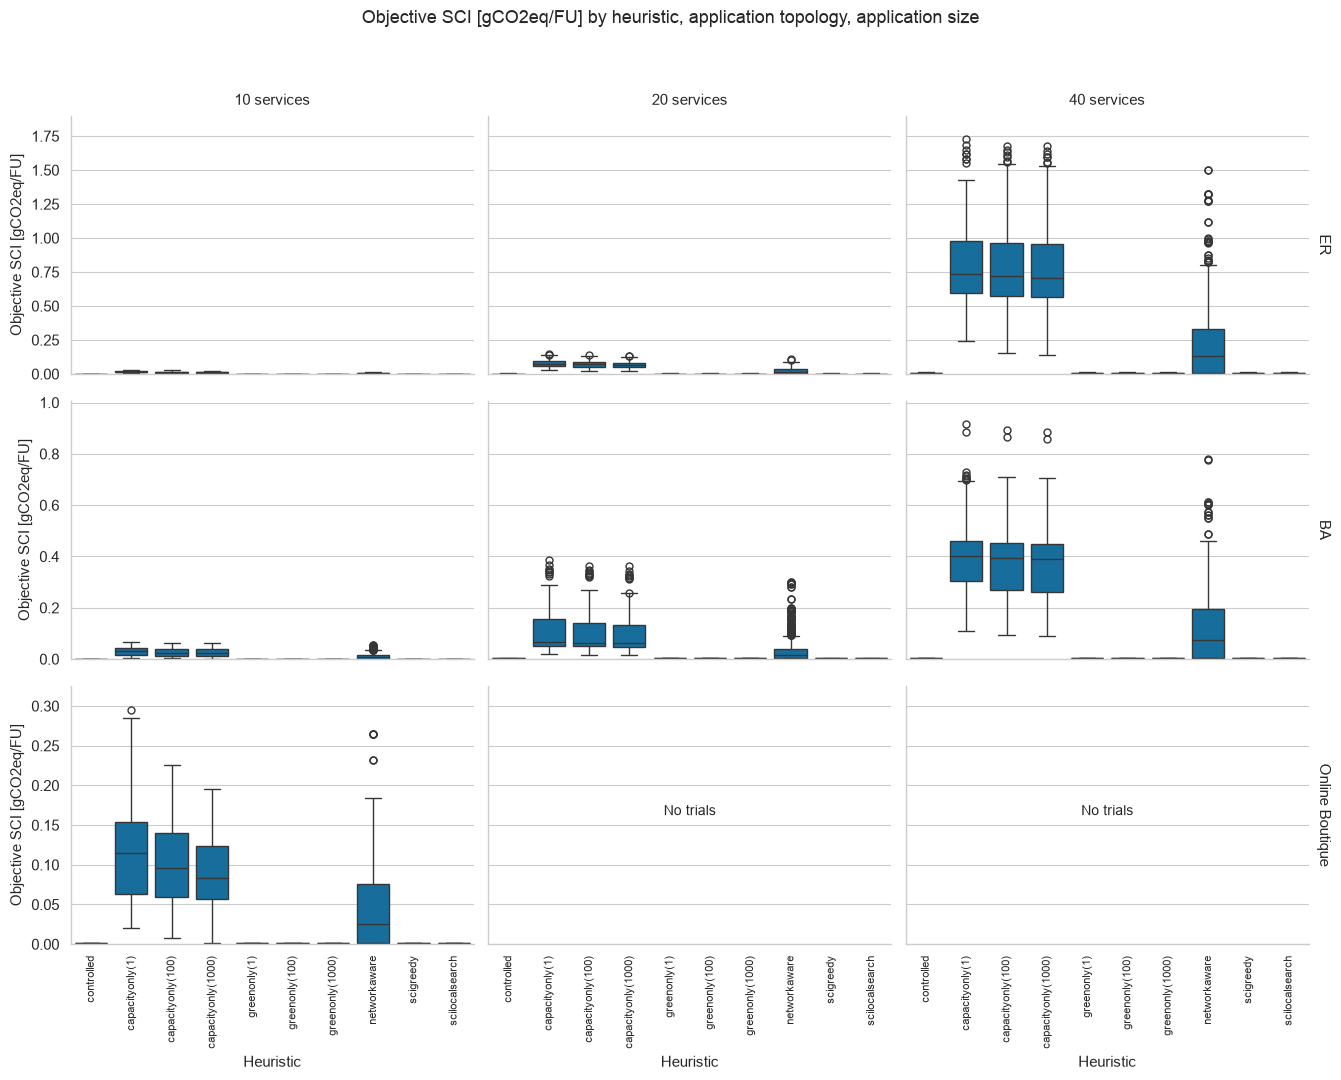

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/objective-sci-by-application.pdf


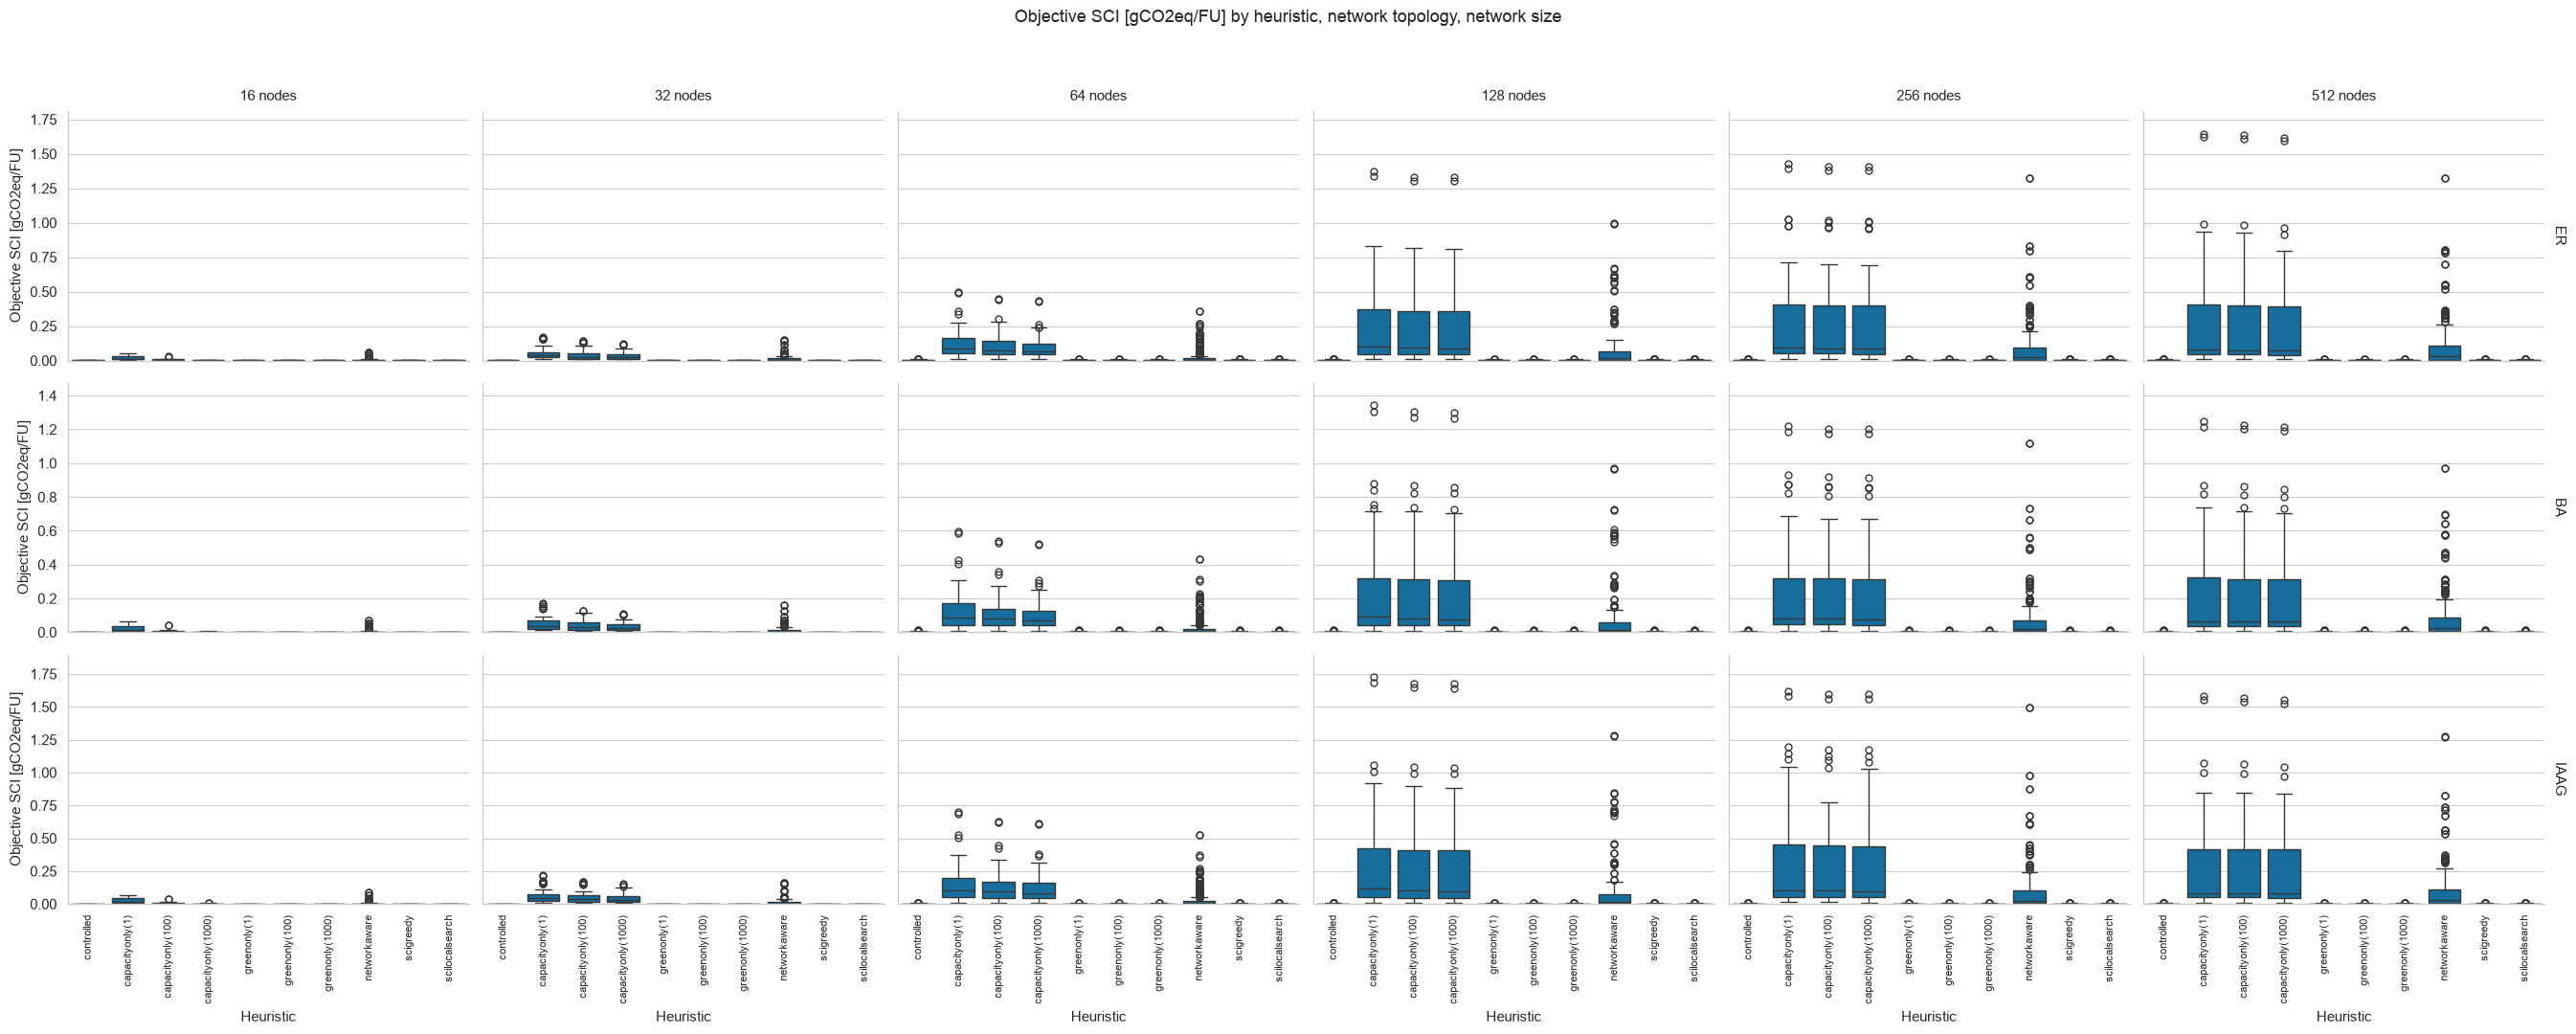

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/objective-sci-by-infrastructure.pdf


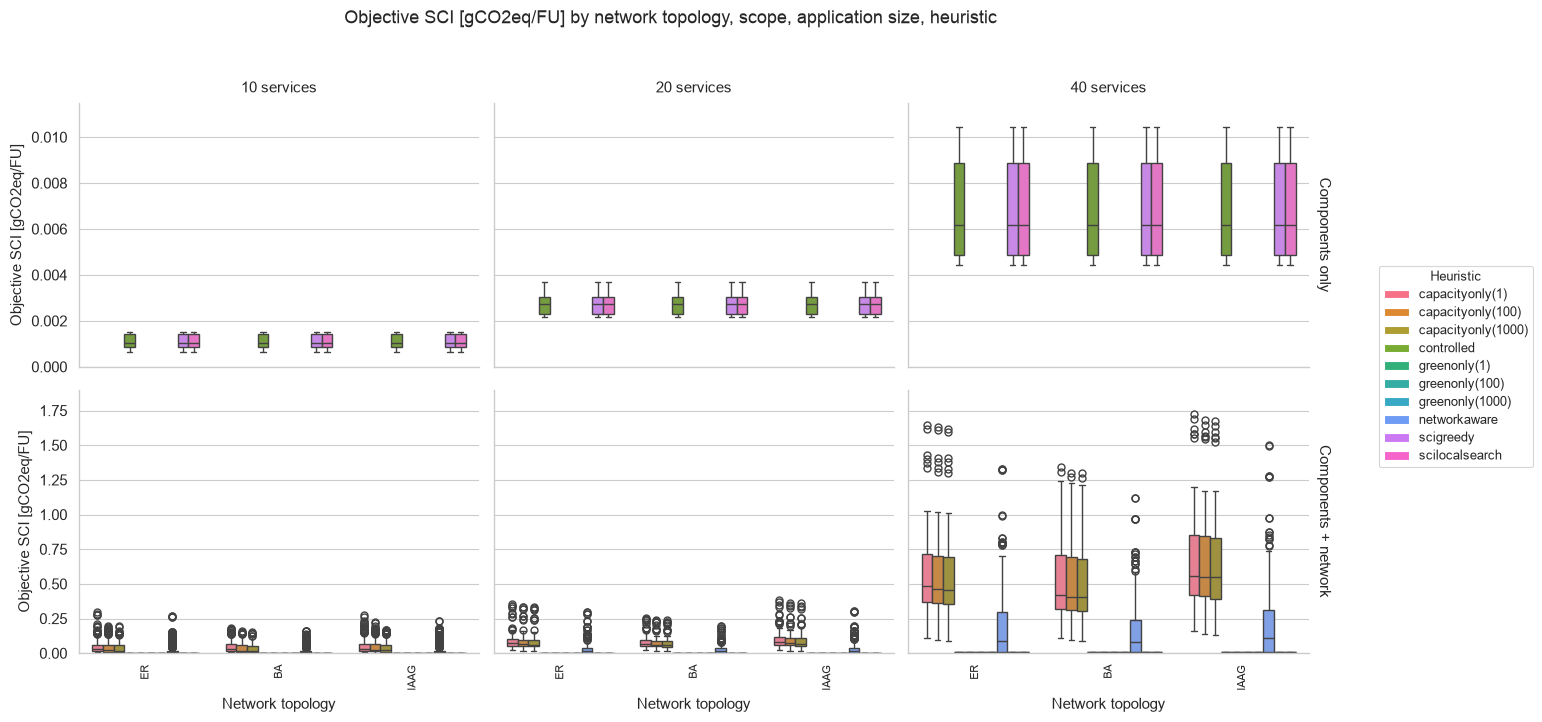

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/objective-sci-by-topology-and-scope.pdf


In [84]:
plot_data = data.copy()
facet_plot(plot_data, 'objective_sci_g', 'Objective SCI [gCO2eq/FU]', 'objective-sci-by-application',
           x="heuristic_plot", row="app_topology", col="application_size")
facet_plot(plot_data, 'objective_sci_g', 'Objective SCI [gCO2eq/FU]', 'objective-sci-by-infrastructure',
           x="heuristic_plot", row="network_topology", col="infrastructure_size")
facet_plot(plot_data, 'objective_sci_g', 'Objective SCI [gCO2eq/FU]', 'objective-sci-by-topology-and-scope',
           x="network_topology", hue="heuristic_plot", row="scope_label",
           col="application_size")


## Network fraction of total SCI

Application panels separate application topology and service count. Infrastructure panels separate network topology and node count. The third view compares network topologies, keeping scopes separate and showing the heuristic variants in colour.


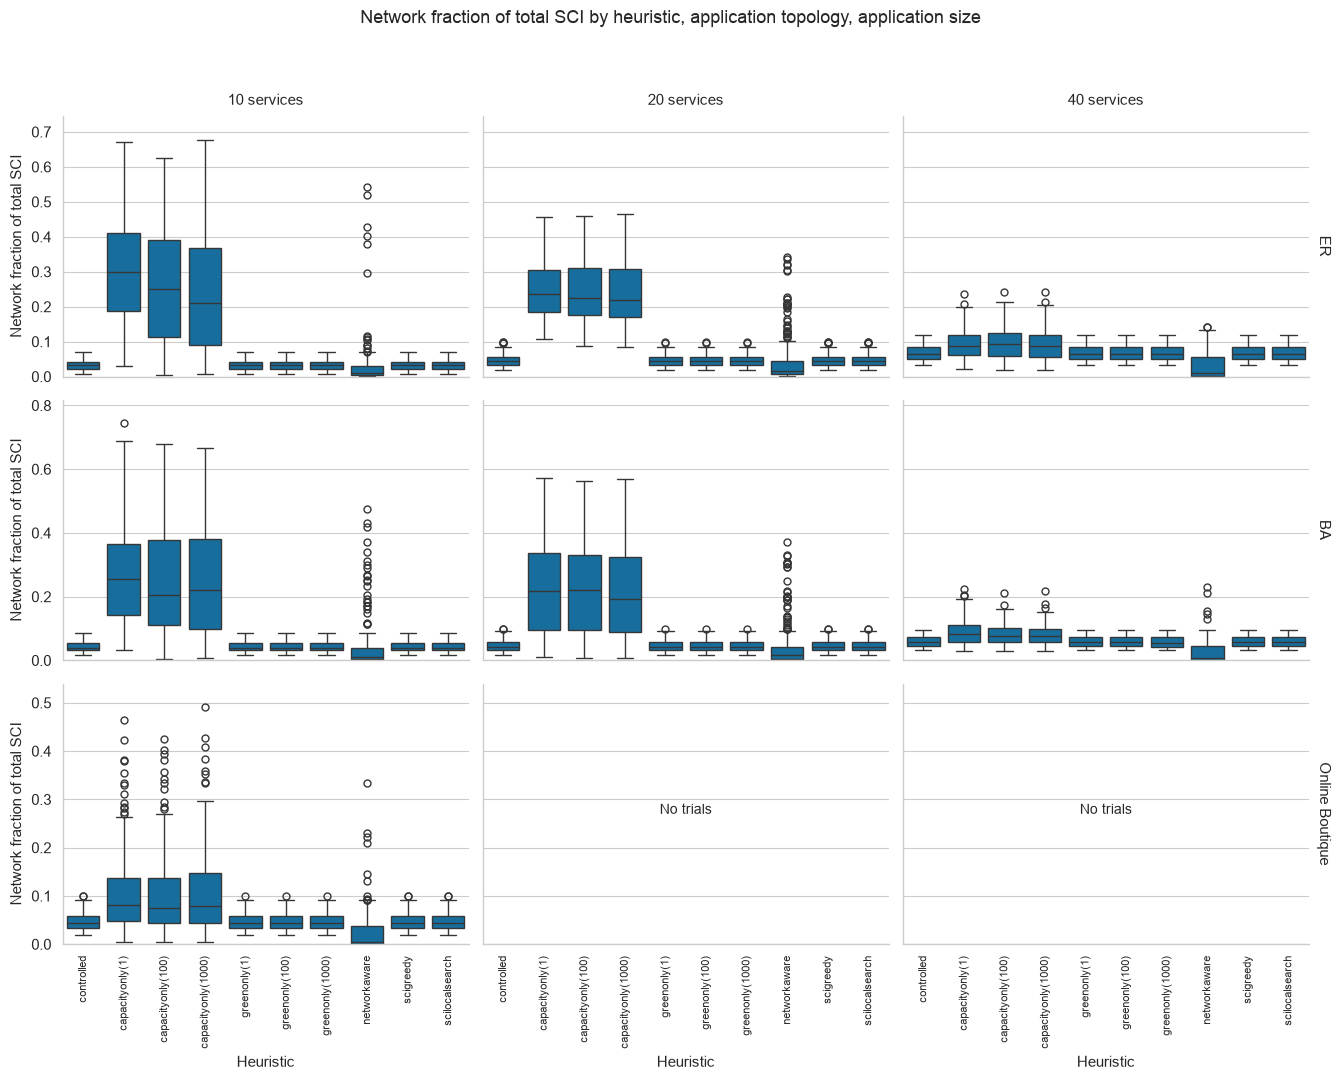

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/network-share-by-application.pdf


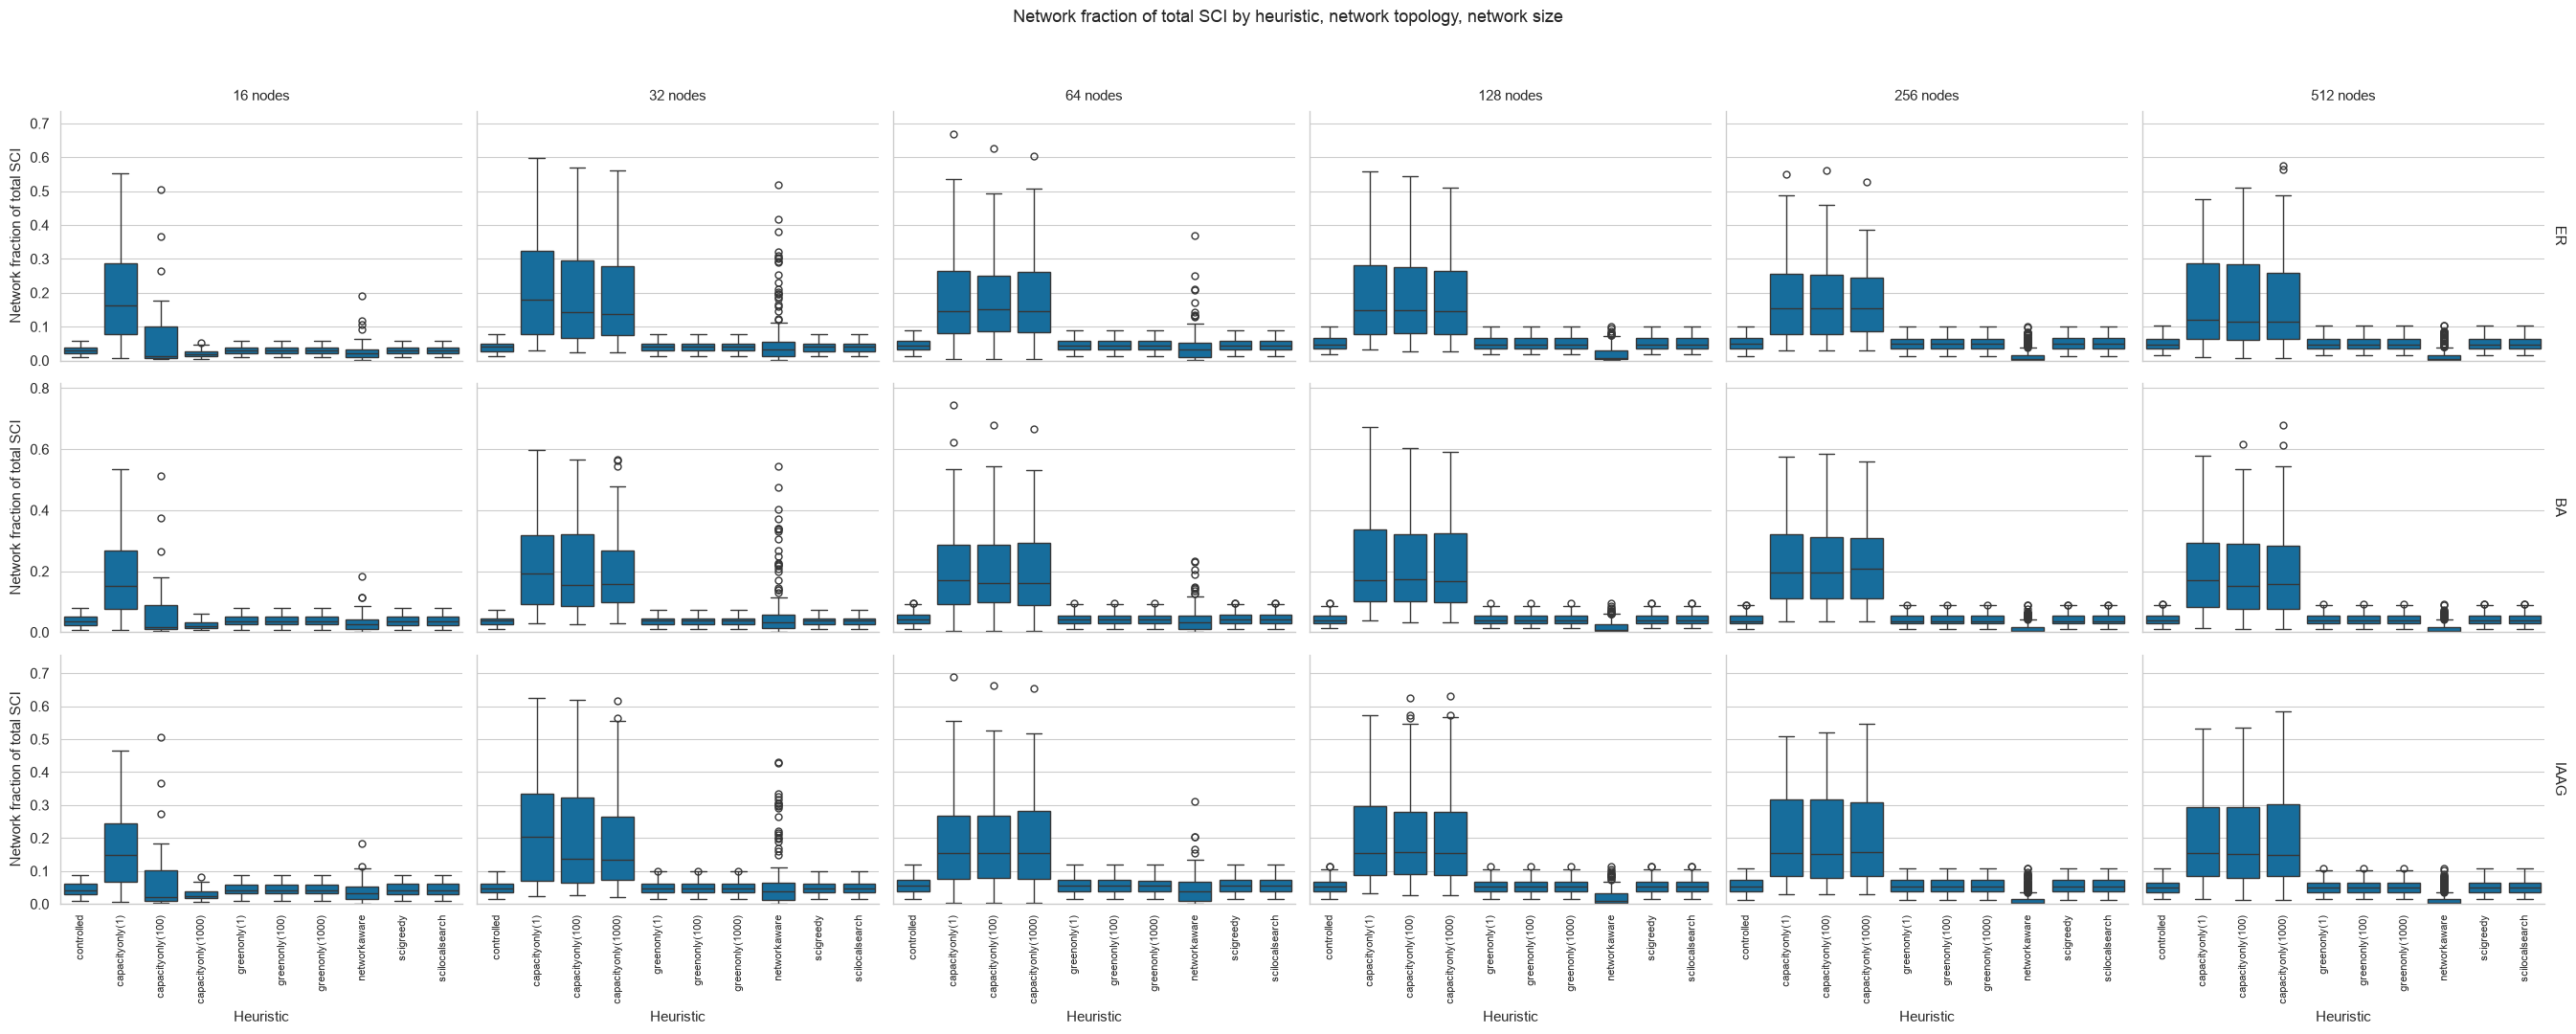

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/network-share-by-infrastructure.pdf


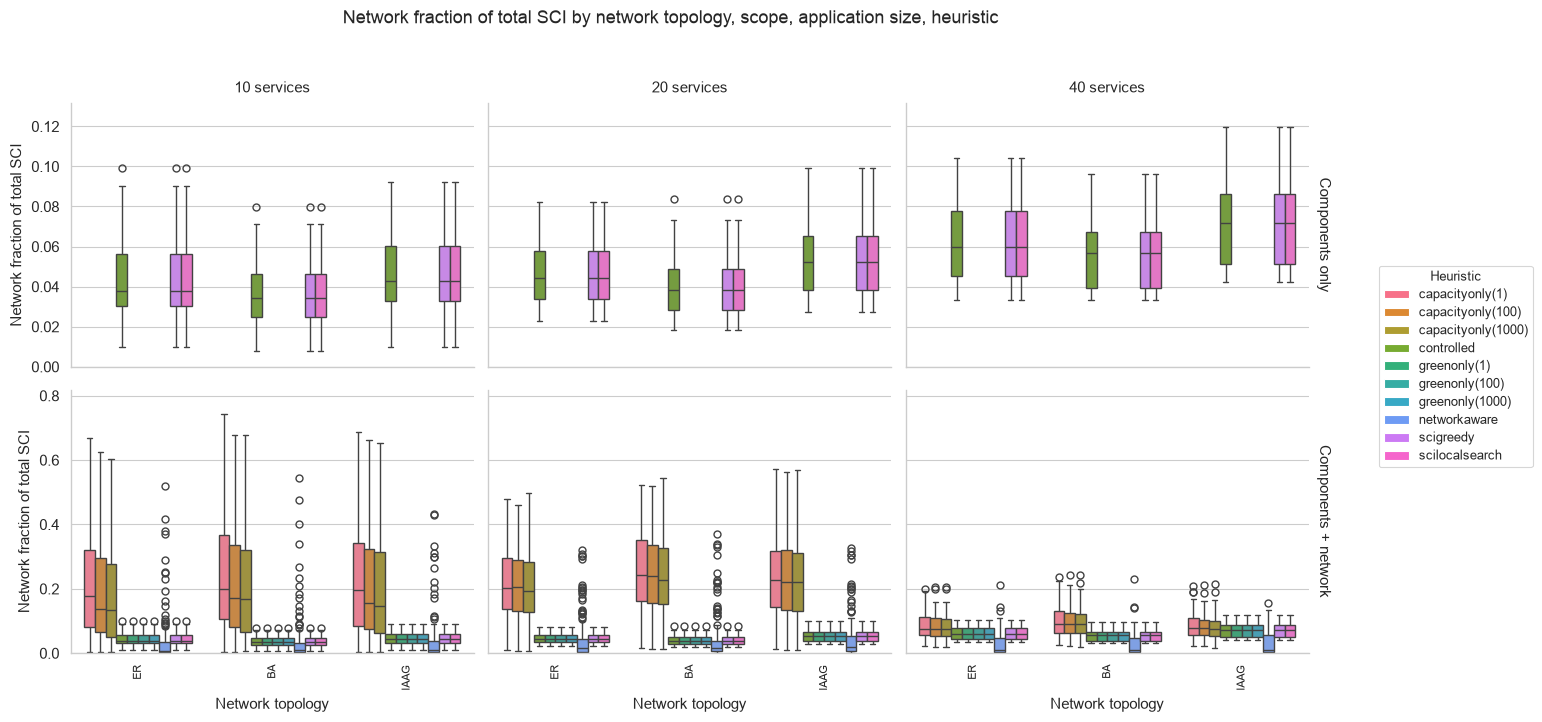

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/network-share-by-topology-and-scope.pdf


In [85]:
plot_data = data.copy()
facet_plot(plot_data, 'network_share', 'Network fraction of total SCI', 'network-share-by-application',
           x="heuristic_plot", row="app_topology", col="application_size")
facet_plot(plot_data, 'network_share', 'Network fraction of total SCI', 'network-share-by-infrastructure',
           x="heuristic_plot", row="network_topology", col="infrastructure_size")
facet_plot(plot_data, 'network_share', 'Network fraction of total SCI', 'network-share-by-topology-and-scope',
           x="network_topology", hue="heuristic_plot", row="scope_label",
           col="application_size")


## Placement time [s]

Application panels separate application topology and service count. Infrastructure panels separate network topology and node count. The third view compares network topologies, keeping scopes separate and showing the heuristic variants in colour.


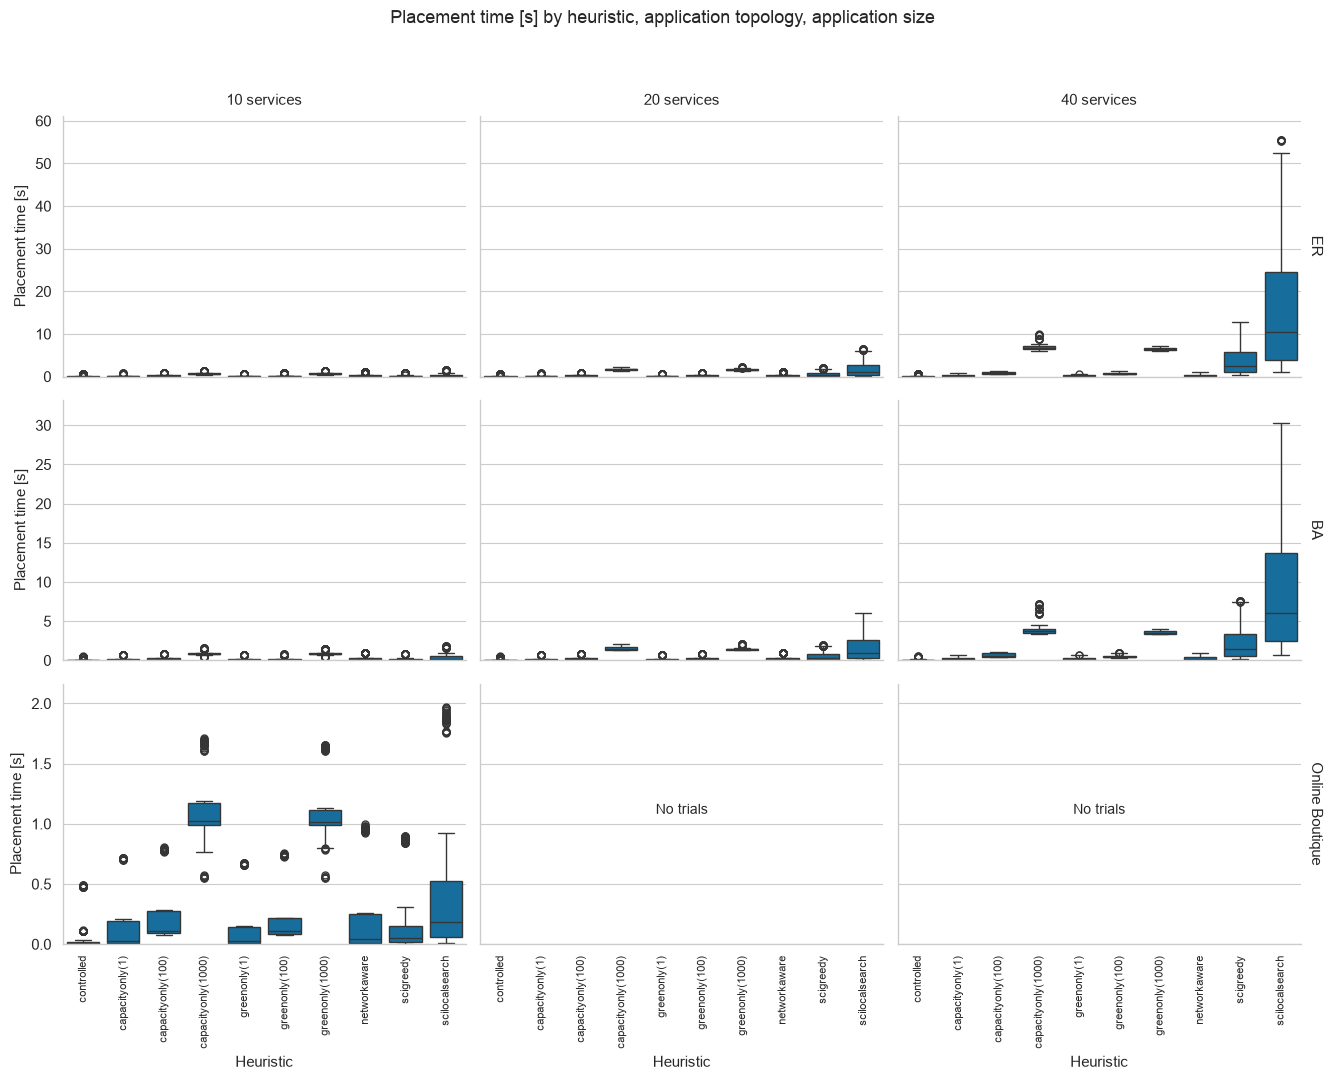

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/placement-time-by-application.pdf


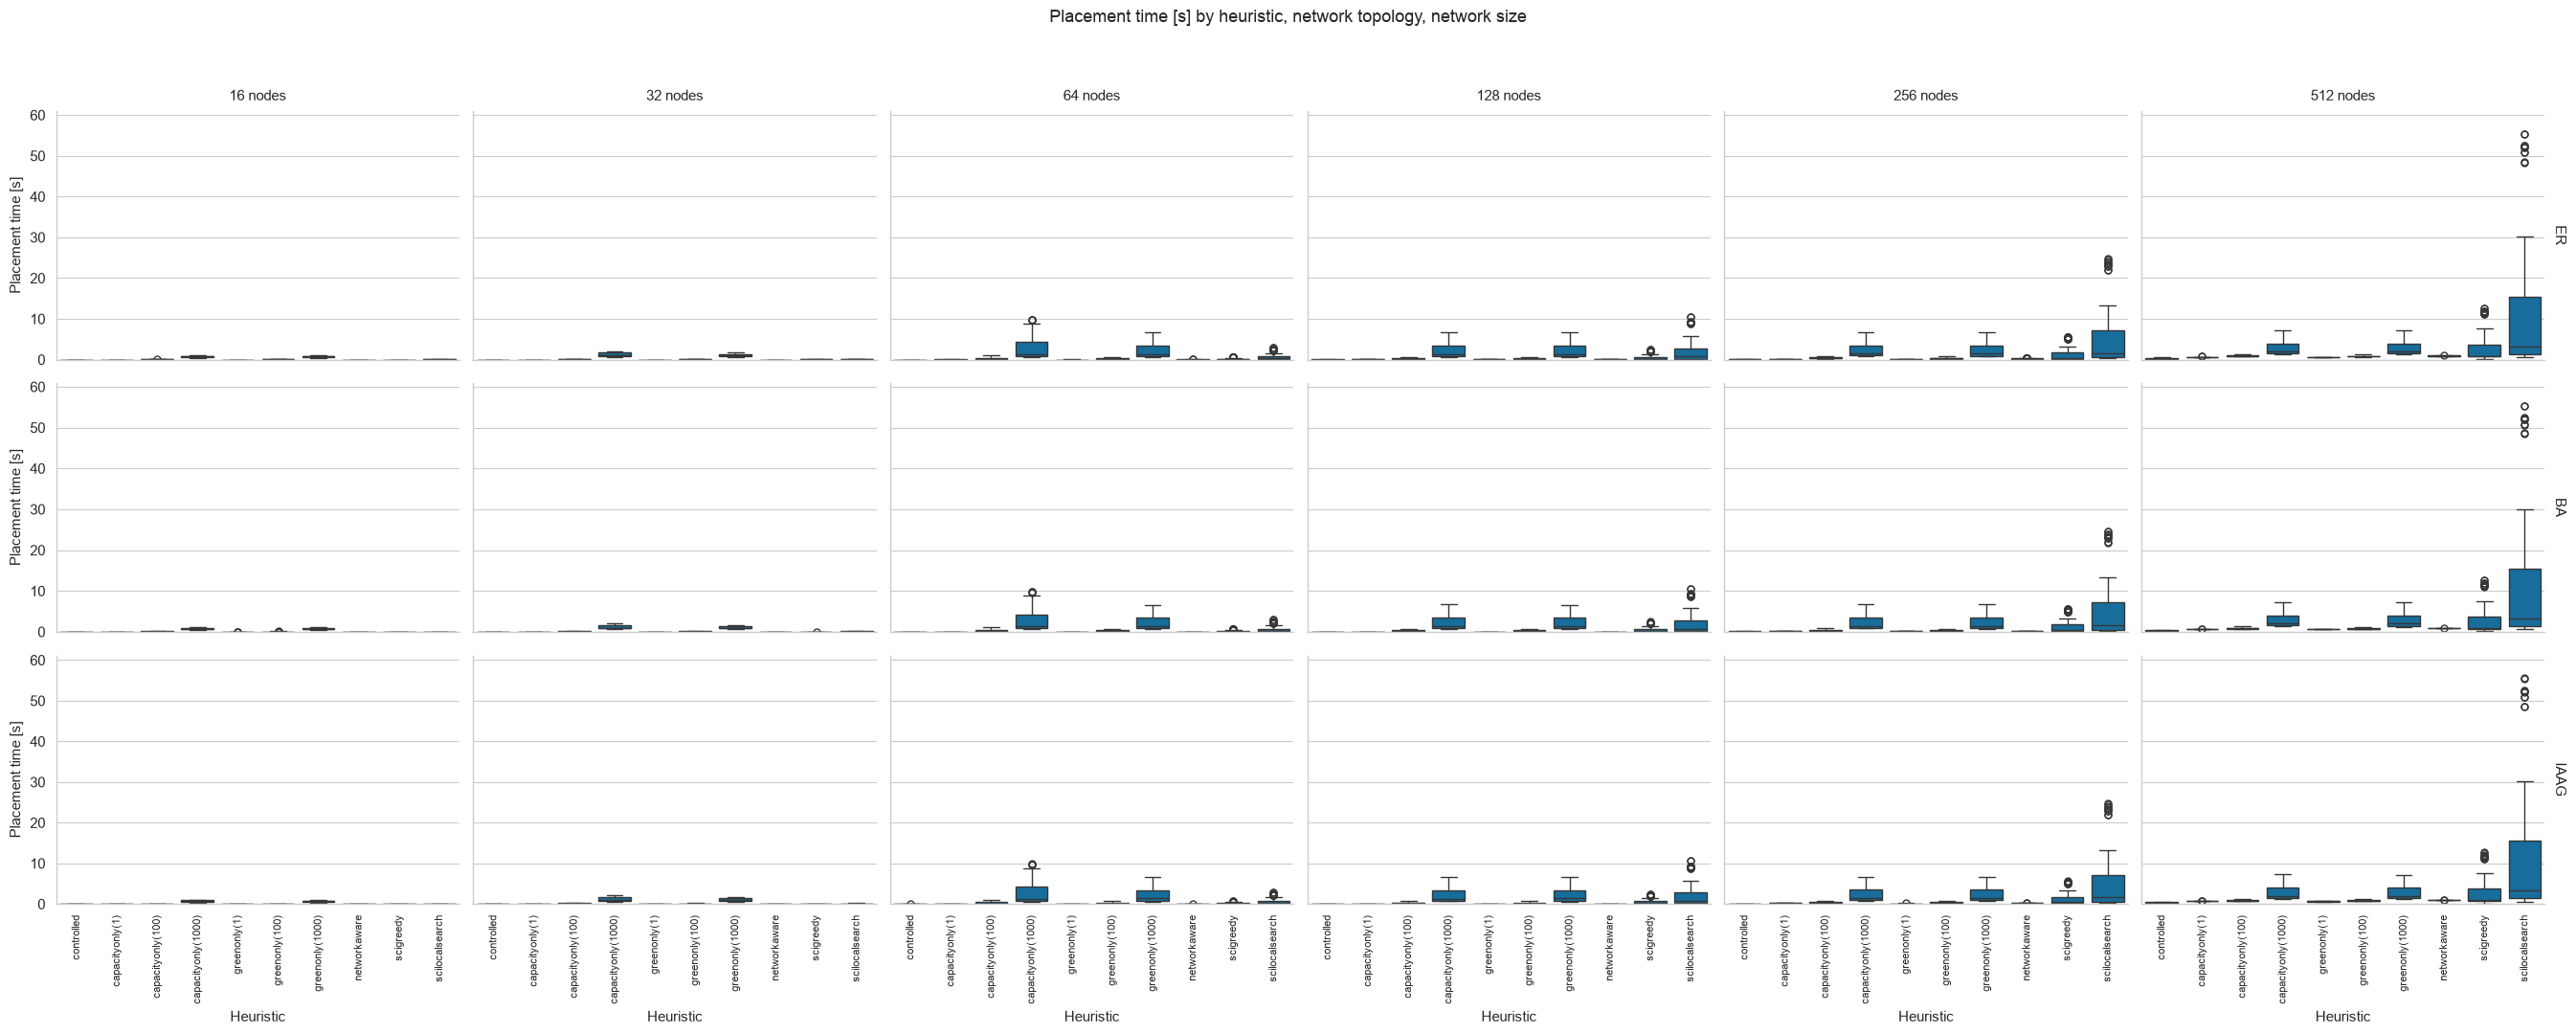

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/placement-time-by-infrastructure.pdf


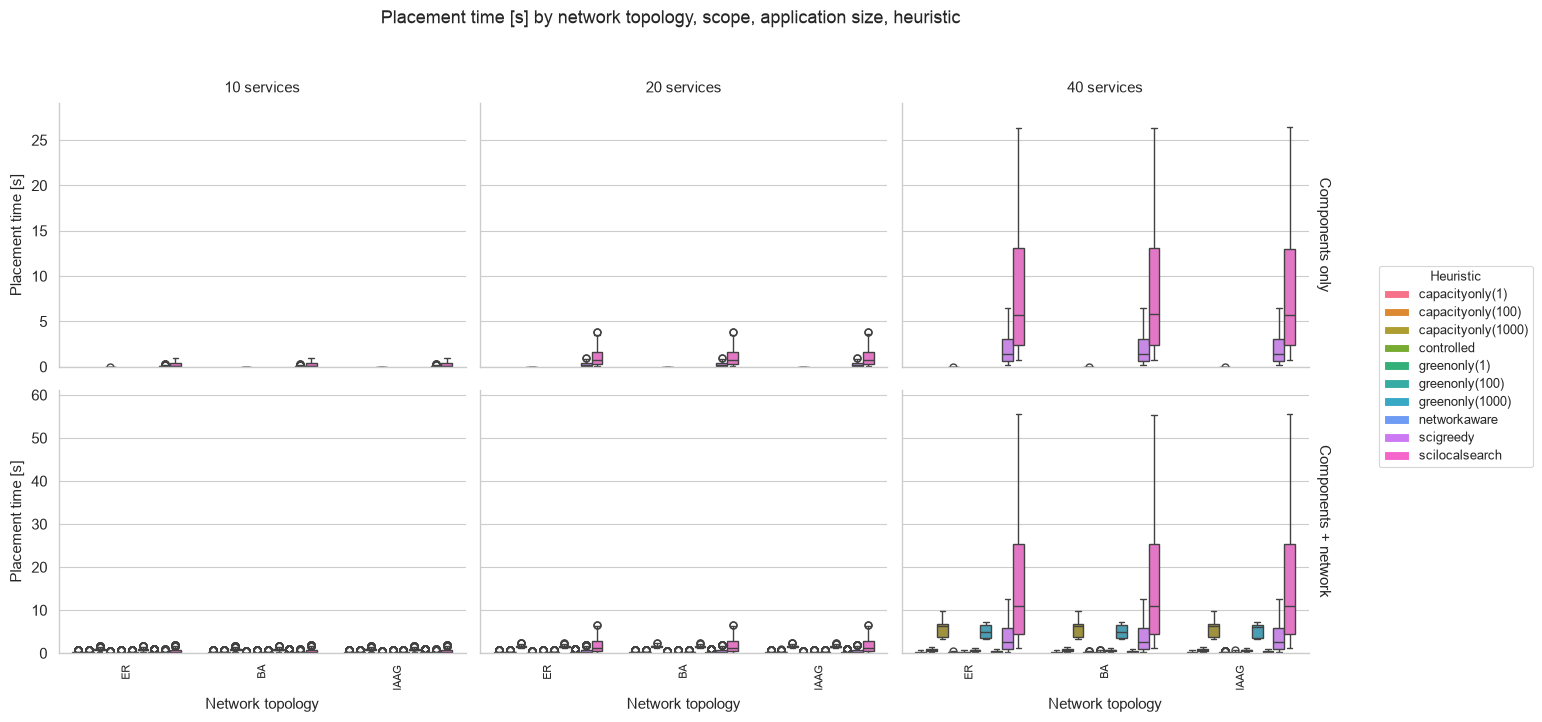

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/placement-time-by-topology-and-scope.pdf


In [86]:
plot_data = data.copy()
facet_plot(plot_data, 'time', 'Placement time [s]', 'placement-time-by-application',
           x="heuristic_plot", row="app_topology", col="application_size")
facet_plot(plot_data, 'time', 'Placement time [s]', 'placement-time-by-infrastructure',
           x="heuristic_plot", row="network_topology", col="infrastructure_size")
facet_plot(plot_data, 'time', 'Placement time [s]', 'placement-time-by-topology-and-scope',
           x="network_topology", hue="heuristic_plot", row="scope_label",
           col="application_size")


## Nodes used

Application panels separate application topology and service count. Infrastructure panels separate network topology and node count. The third view compares network topologies, keeping scopes separate and showing the heuristic variants in colour.


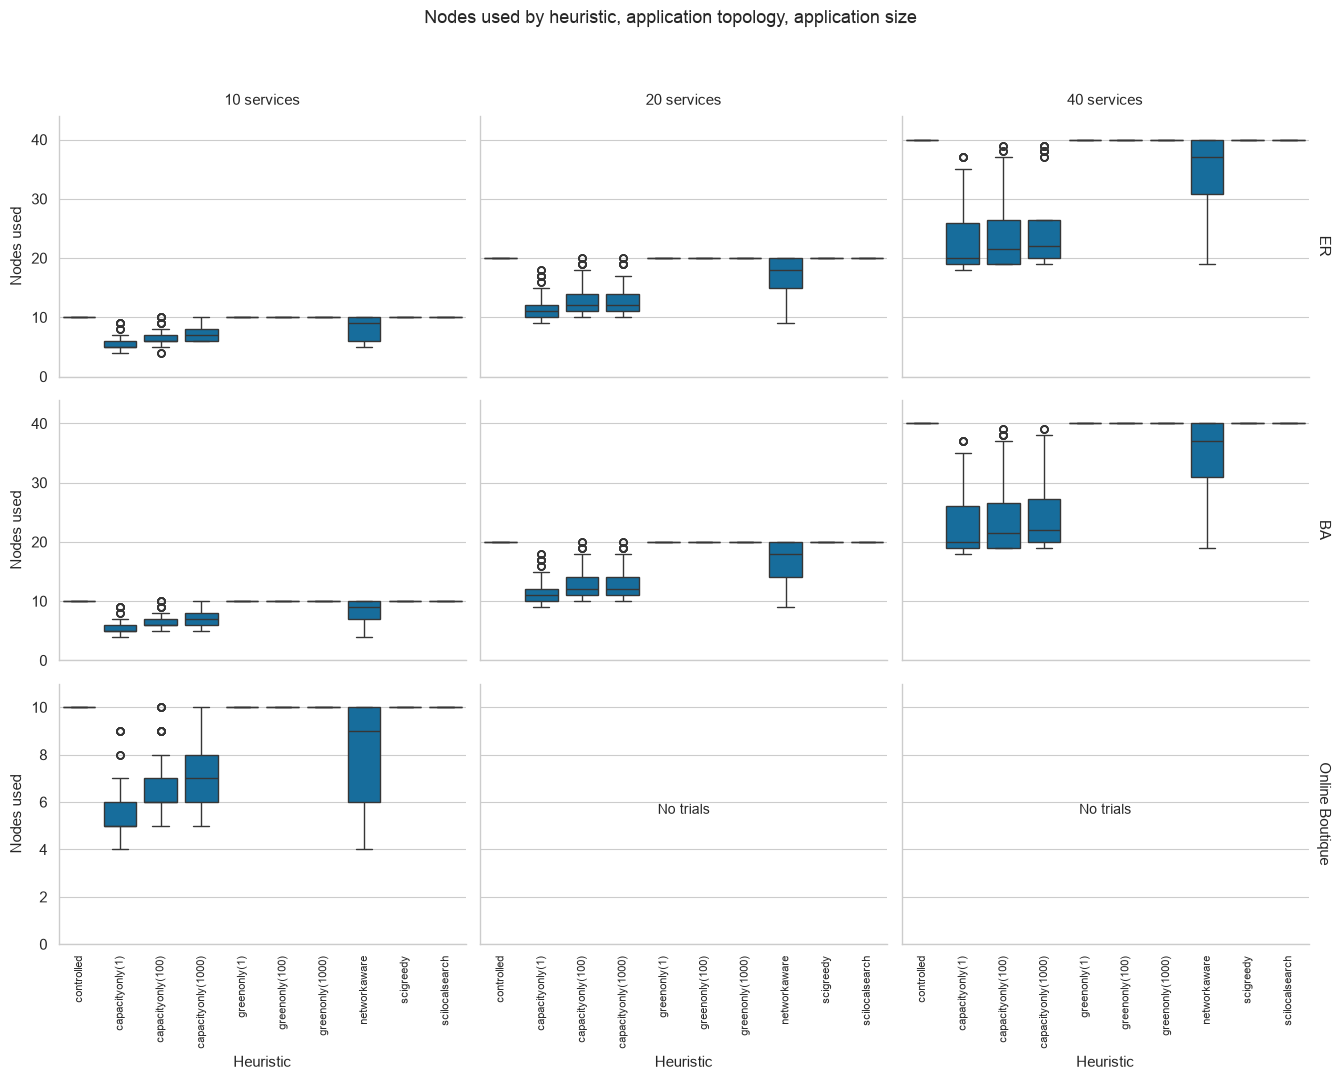

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/nodes-used-by-application.pdf


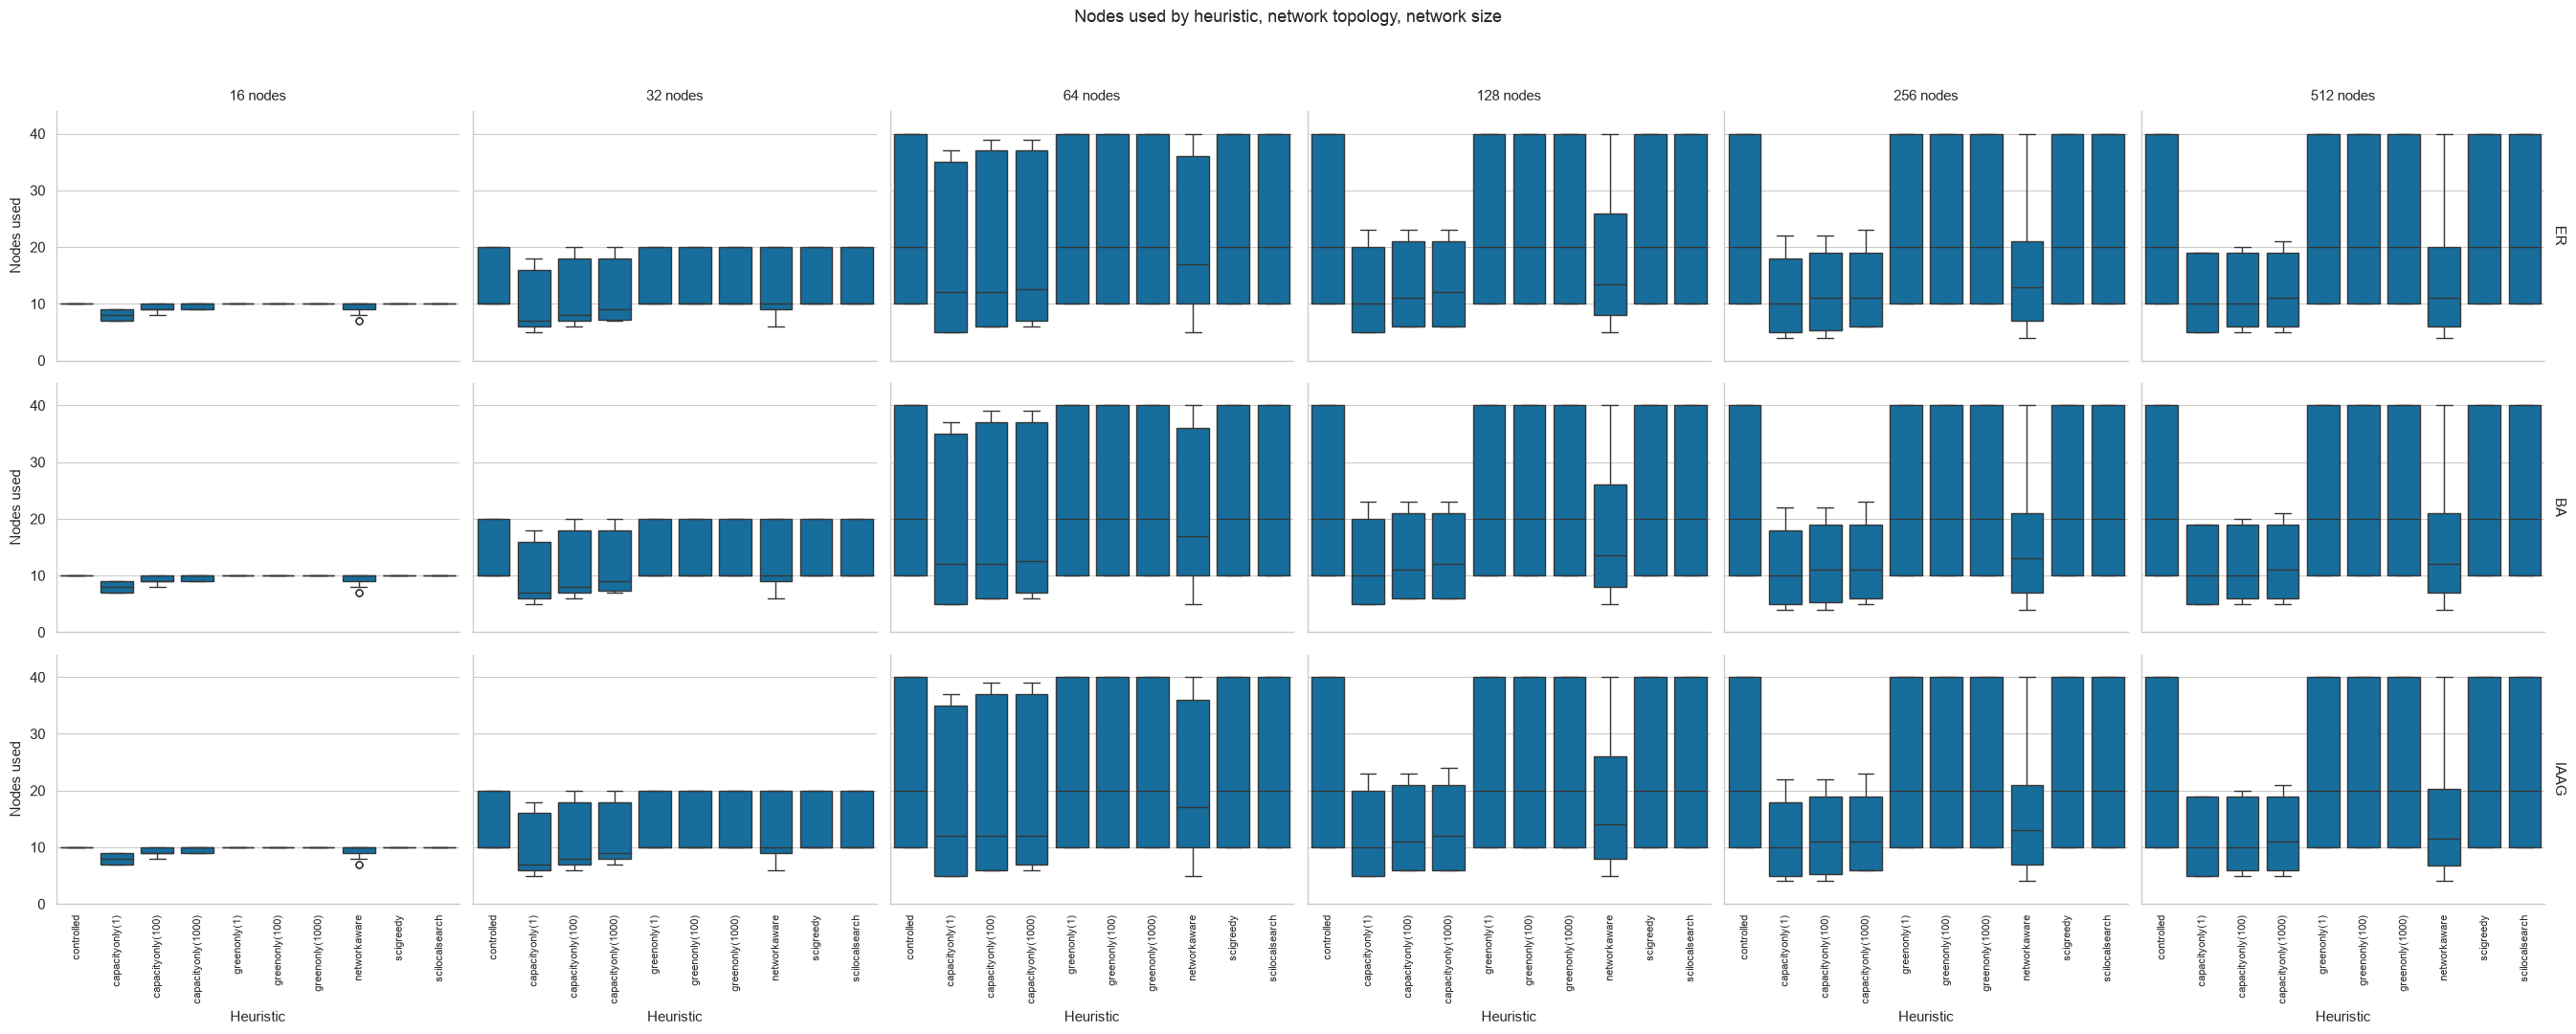

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/nodes-used-by-infrastructure.pdf


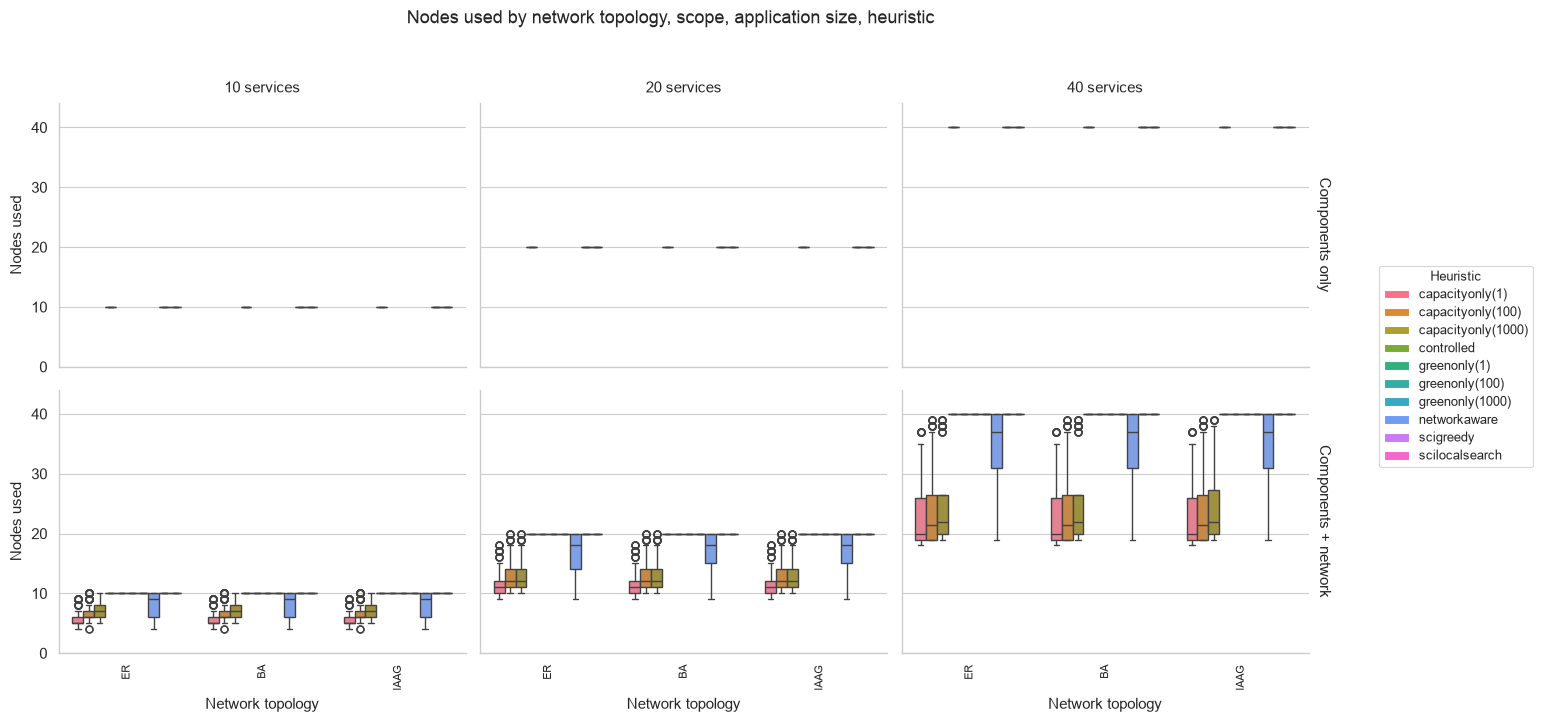

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/nodes-used-by-topology-and-scope.pdf


In [87]:
plot_data = data.copy()
facet_plot(plot_data, 'nodes_used', 'Nodes used', 'nodes-used-by-application',
           x="heuristic_plot", row="app_topology", col="application_size")
facet_plot(plot_data, 'nodes_used', 'Nodes used', 'nodes-used-by-infrastructure',
           x="heuristic_plot", row="network_topology", col="infrastructure_size")
facet_plot(plot_data, 'nodes_used', 'Nodes used', 'nodes-used-by-topology-and-scope',
           x="network_topology", hue="heuristic_plot", row="scope_label",
           col="application_size")


## Relative distance from the optimum

Application panels separate application topology and service count. Infrastructure panels separate network topology and node count. The third view compares network topologies, keeping scopes separate and showing the heuristic variants in colour.


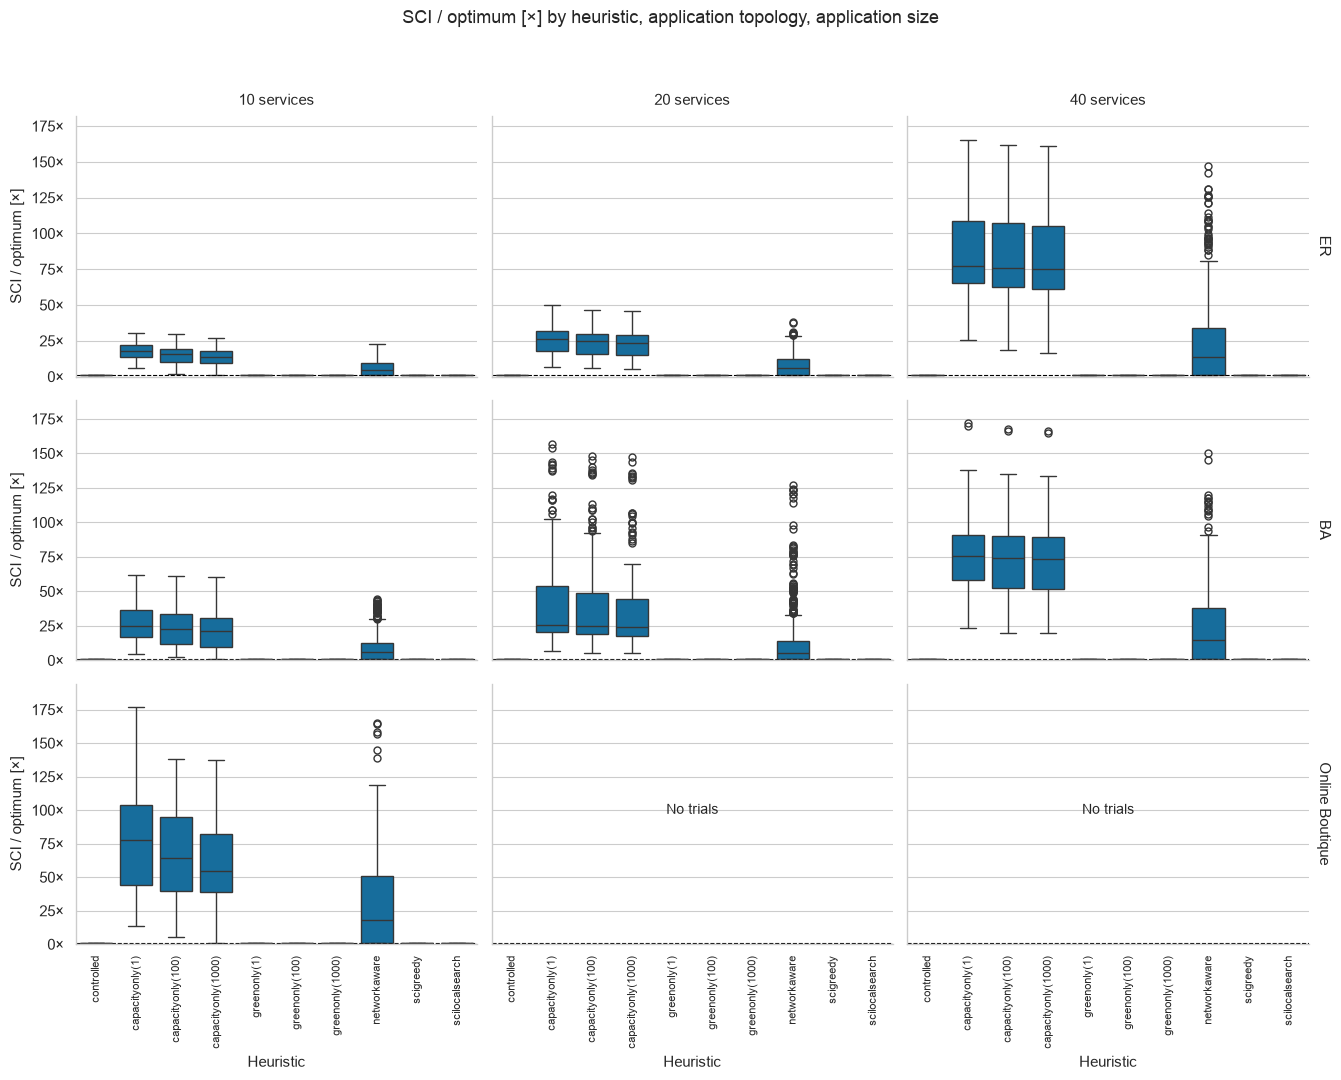

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/optimality-gap-ratio-by-application.pdf


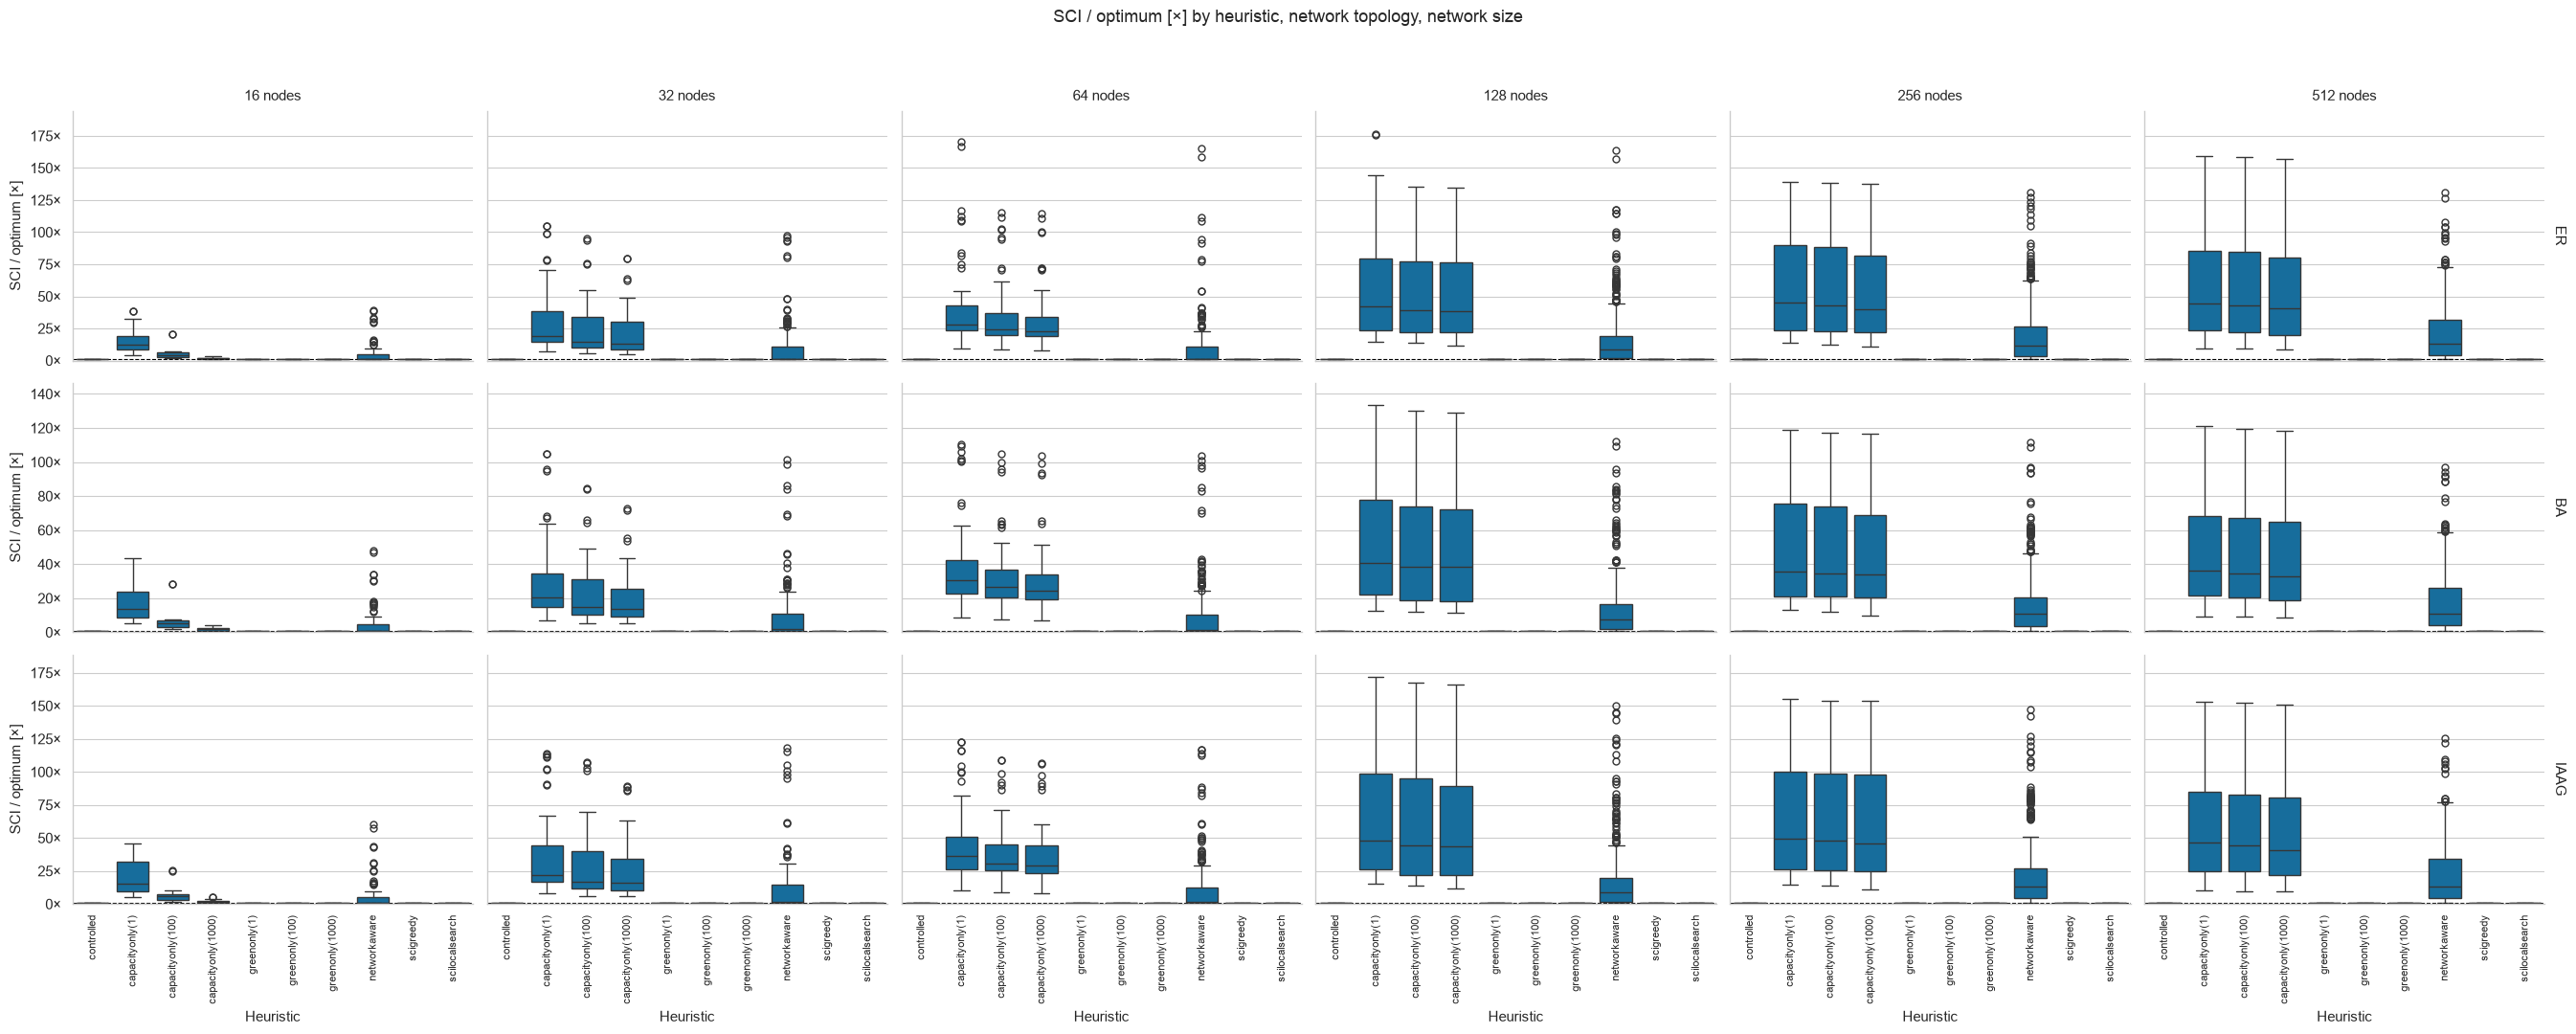

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/optimality-gap-ratio-by-infrastructure.pdf


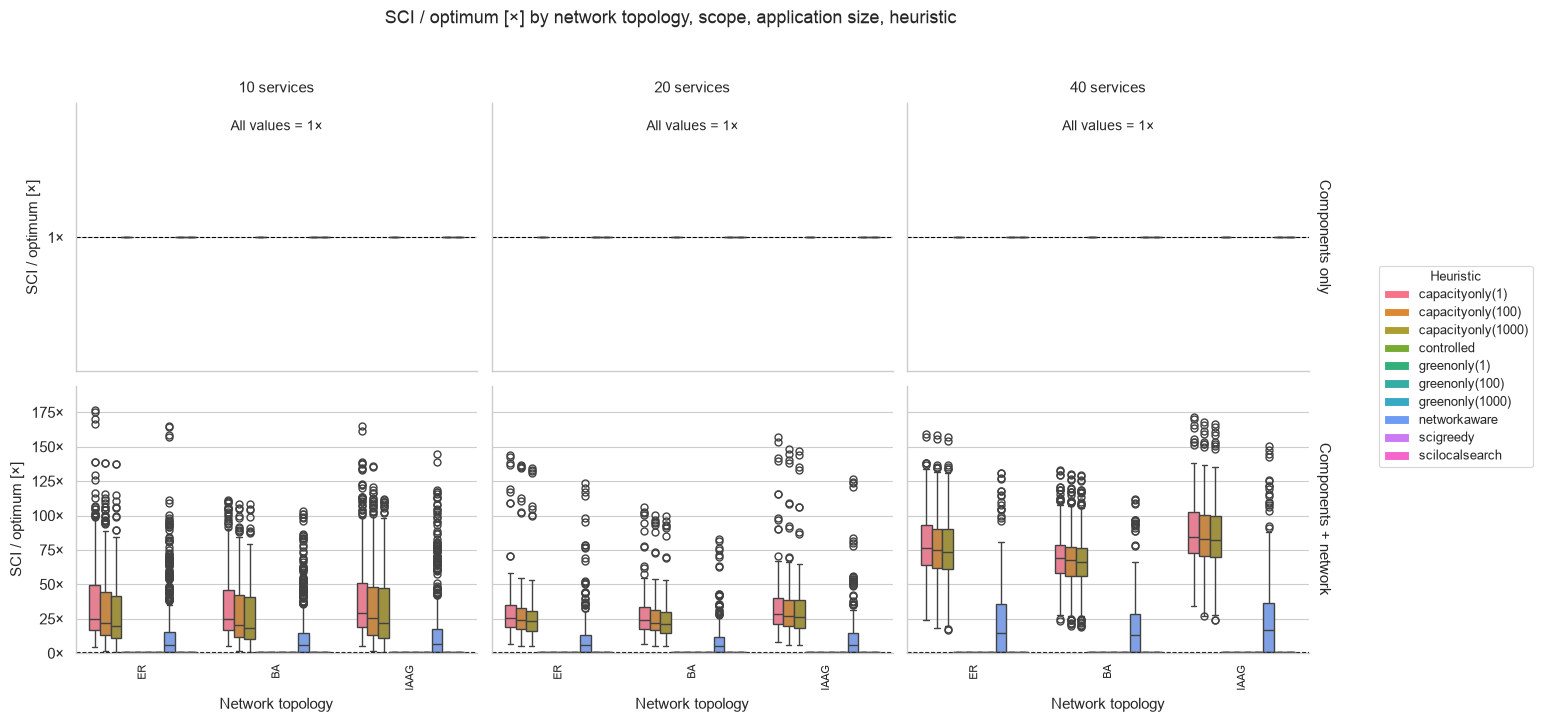

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/optimality-gap-ratio-by-topology-and-scope.pdf


In [88]:
plot_data = data.loc[data["optimal_sci"].notna()].copy()
facet_plot(plot_data, 'optimality_comparison', OPTIMALITY_LABEL, f"optimality-gap-{OPTIMALITY_DISPLAY}-by-application",
           x="heuristic_plot", row="app_topology", col="application_size")
facet_plot(plot_data, 'optimality_comparison', OPTIMALITY_LABEL, f"optimality-gap-{OPTIMALITY_DISPLAY}-by-infrastructure",
           x="heuristic_plot", row="network_topology", col="infrastructure_size")
facet_plot(plot_data, 'optimality_comparison', OPTIMALITY_LABEL, f"optimality-gap-{OPTIMALITY_DISPLAY}-by-topology-and-scope",
           x="network_topology", hue="heuristic_plot", row="scope_label",
           col="application_size")


## SCI gap from optimum [gCO2eq/FU]

Application panels separate application topology and service count. Infrastructure panels separate network topology and node count. The third view compares network topologies, keeping scopes separate and showing the heuristic variants in colour.


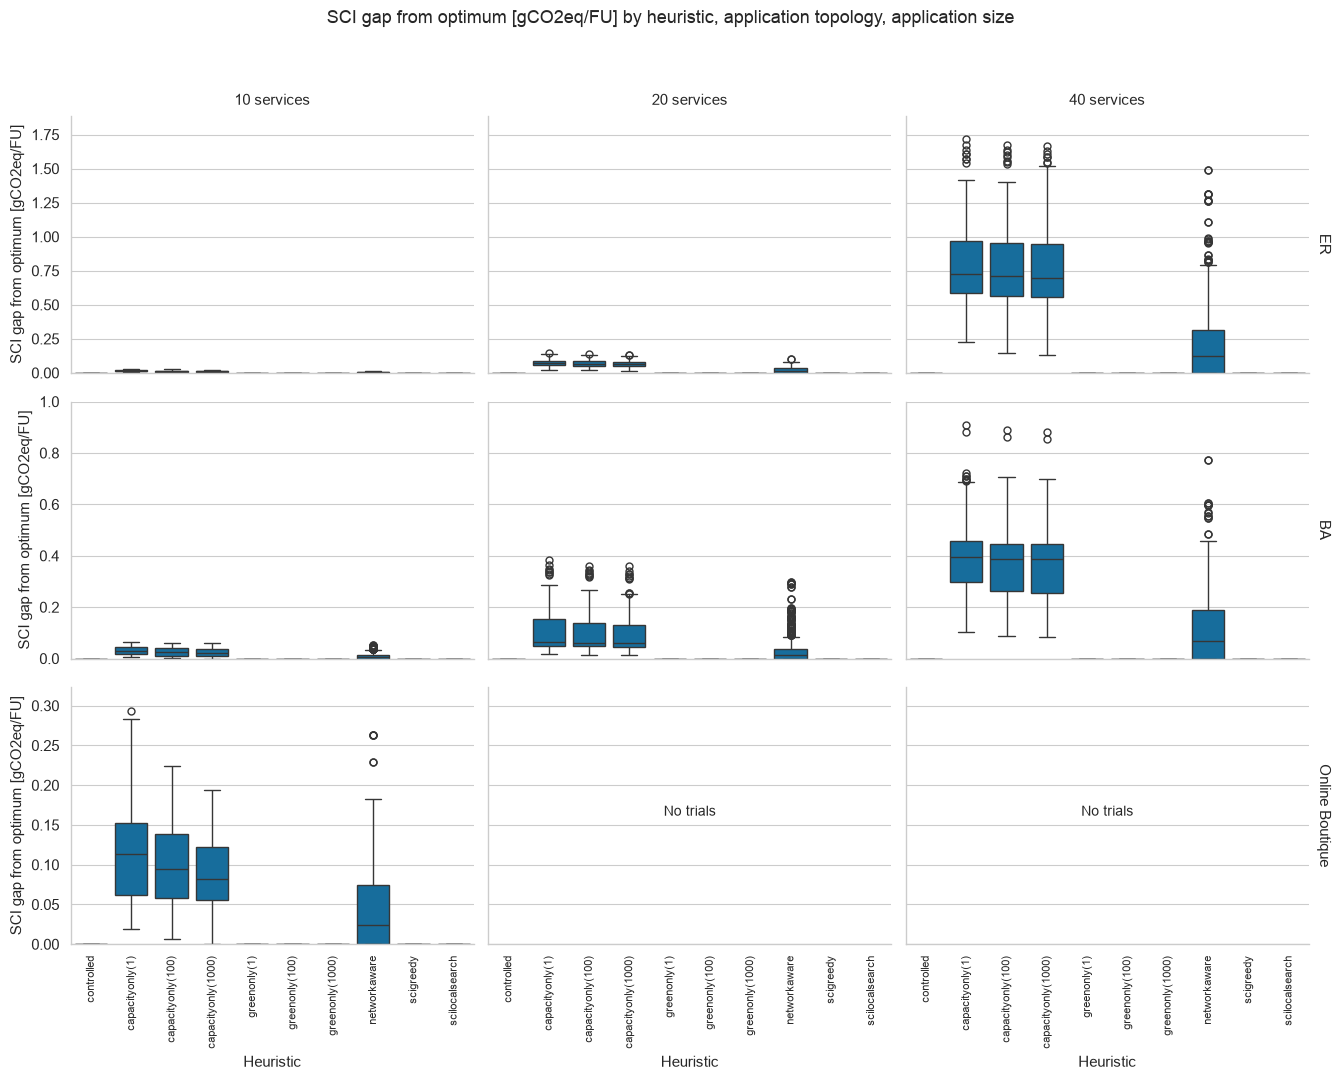

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/optimality-gap-absolute-by-application.pdf


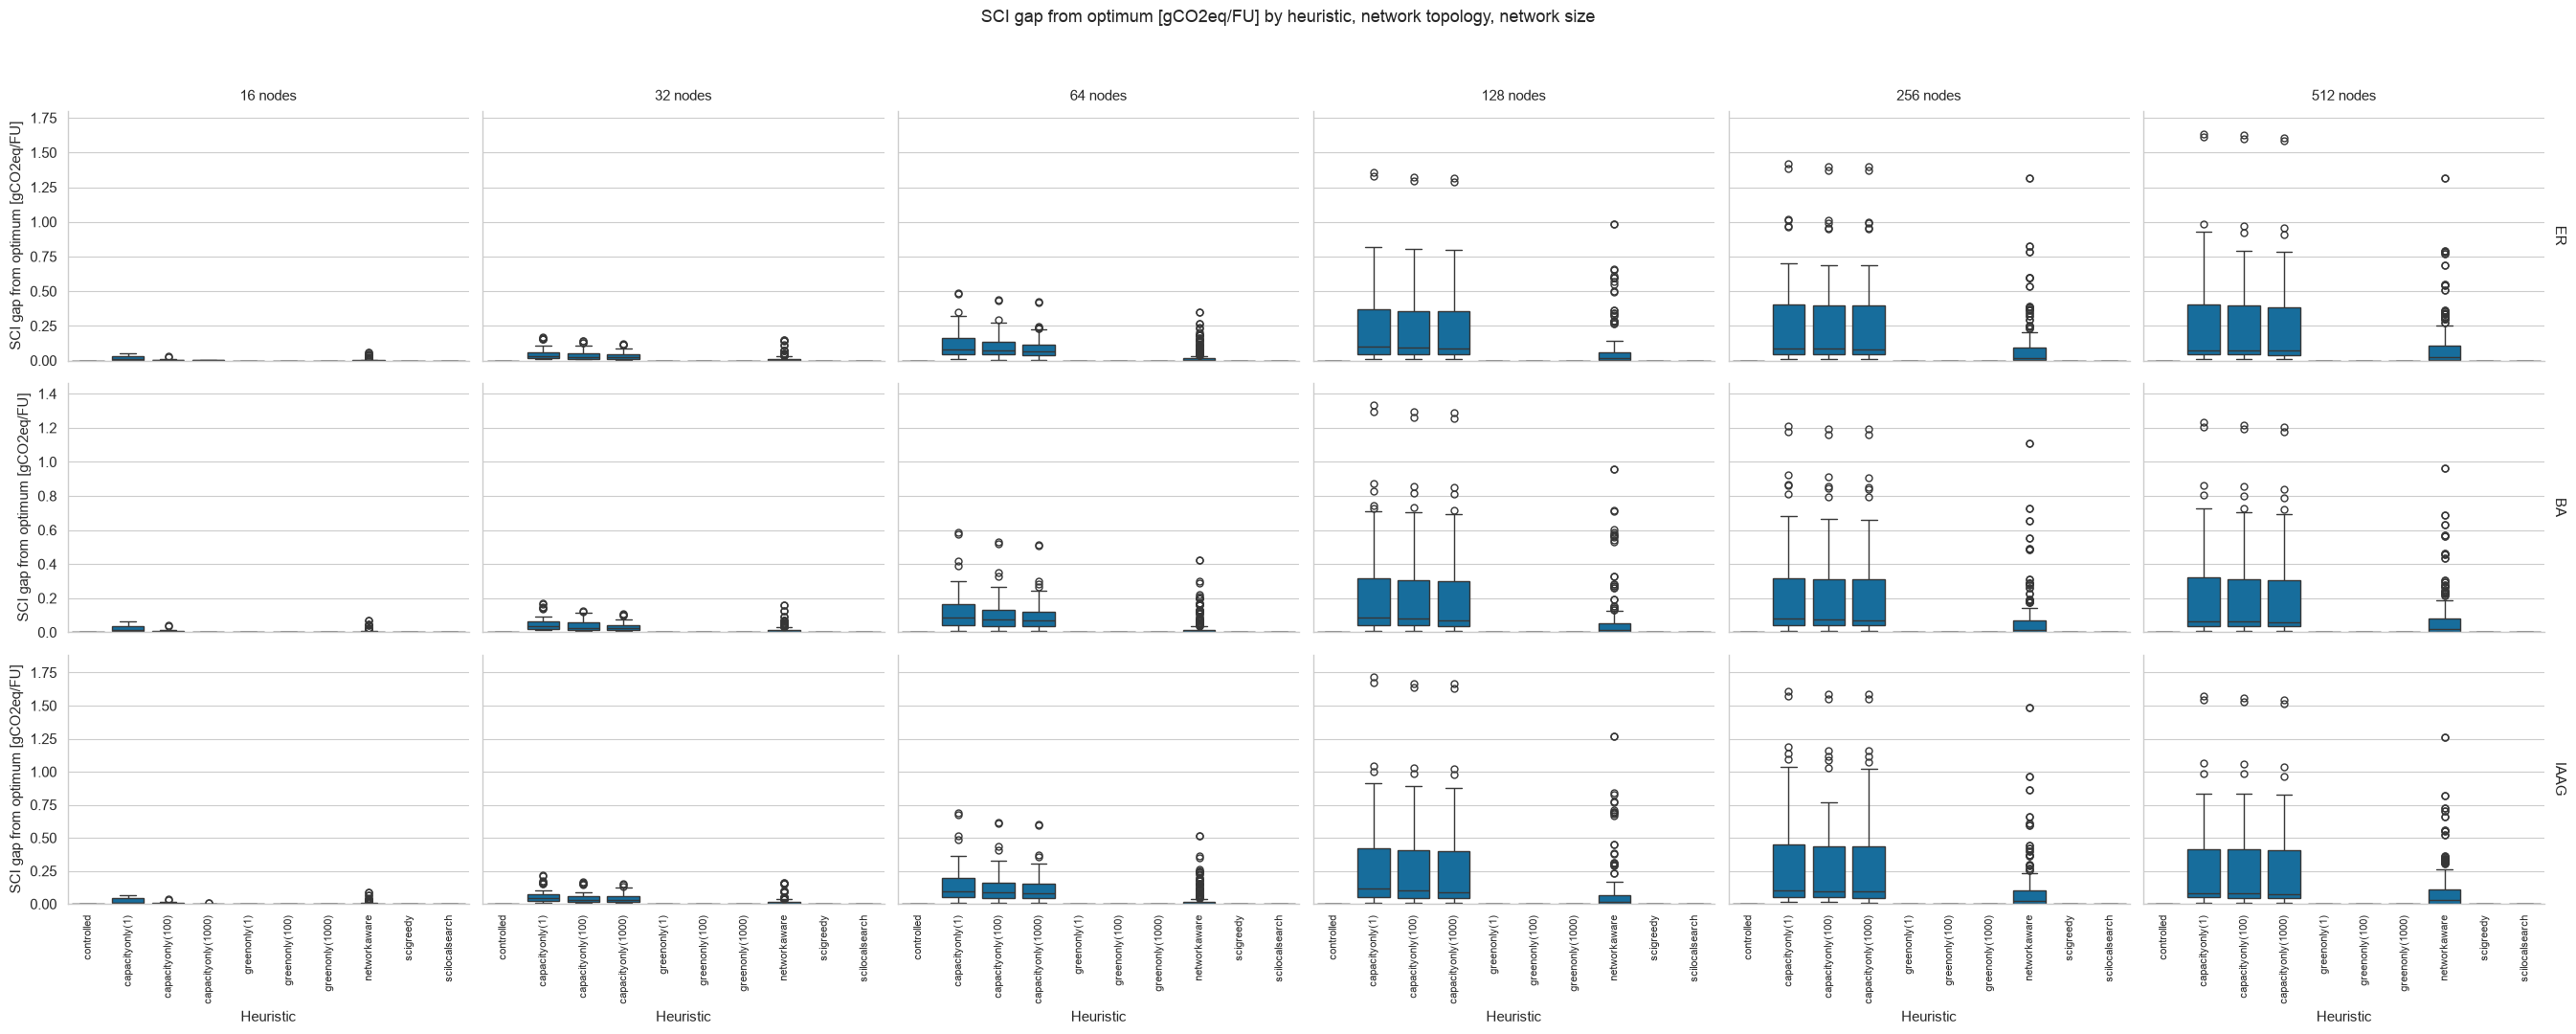

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/optimality-gap-absolute-by-infrastructure.pdf


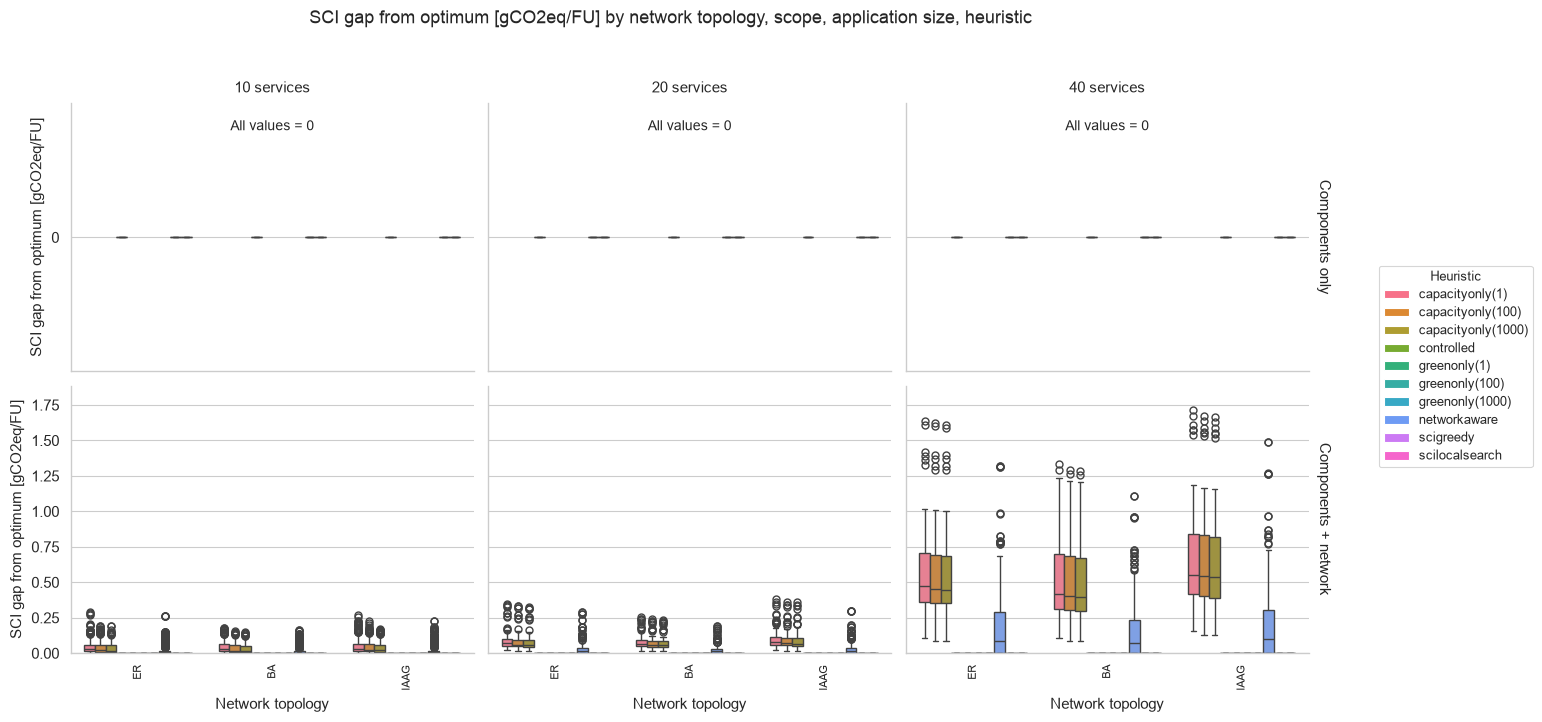

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/optimality-gap-absolute-by-topology-and-scope.pdf


In [89]:
plot_data = data.loc[data["optimal_sci"].notna()].copy()
facet_plot(plot_data, 'absolute_gap_g', 'SCI gap from optimum [gCO2eq/FU]', 'optimality-gap-absolute-by-application',
           x="heuristic_plot", row="app_topology", col="application_size")
facet_plot(plot_data, 'absolute_gap_g', 'SCI gap from optimum [gCO2eq/FU]', 'optimality-gap-absolute-by-infrastructure',
           x="heuristic_plot", row="network_topology", col="infrastructure_size")
facet_plot(plot_data, 'absolute_gap_g', 'SCI gap from optimum [gCO2eq/FU]', 'optimality-gap-absolute-by-topology-and-scope',
           x="network_topology", hue="heuristic_plot", row="scope_label",
           col="application_size")


## Direct scope comparisons

Compare component-only and component-plus-network objectives for each heuristic. These scopes affect the placement strategy only for SCI-greedy and local search; the other strategies run once under the combined scope. Each plot isolates one heuristic to avoid mixing strategies.


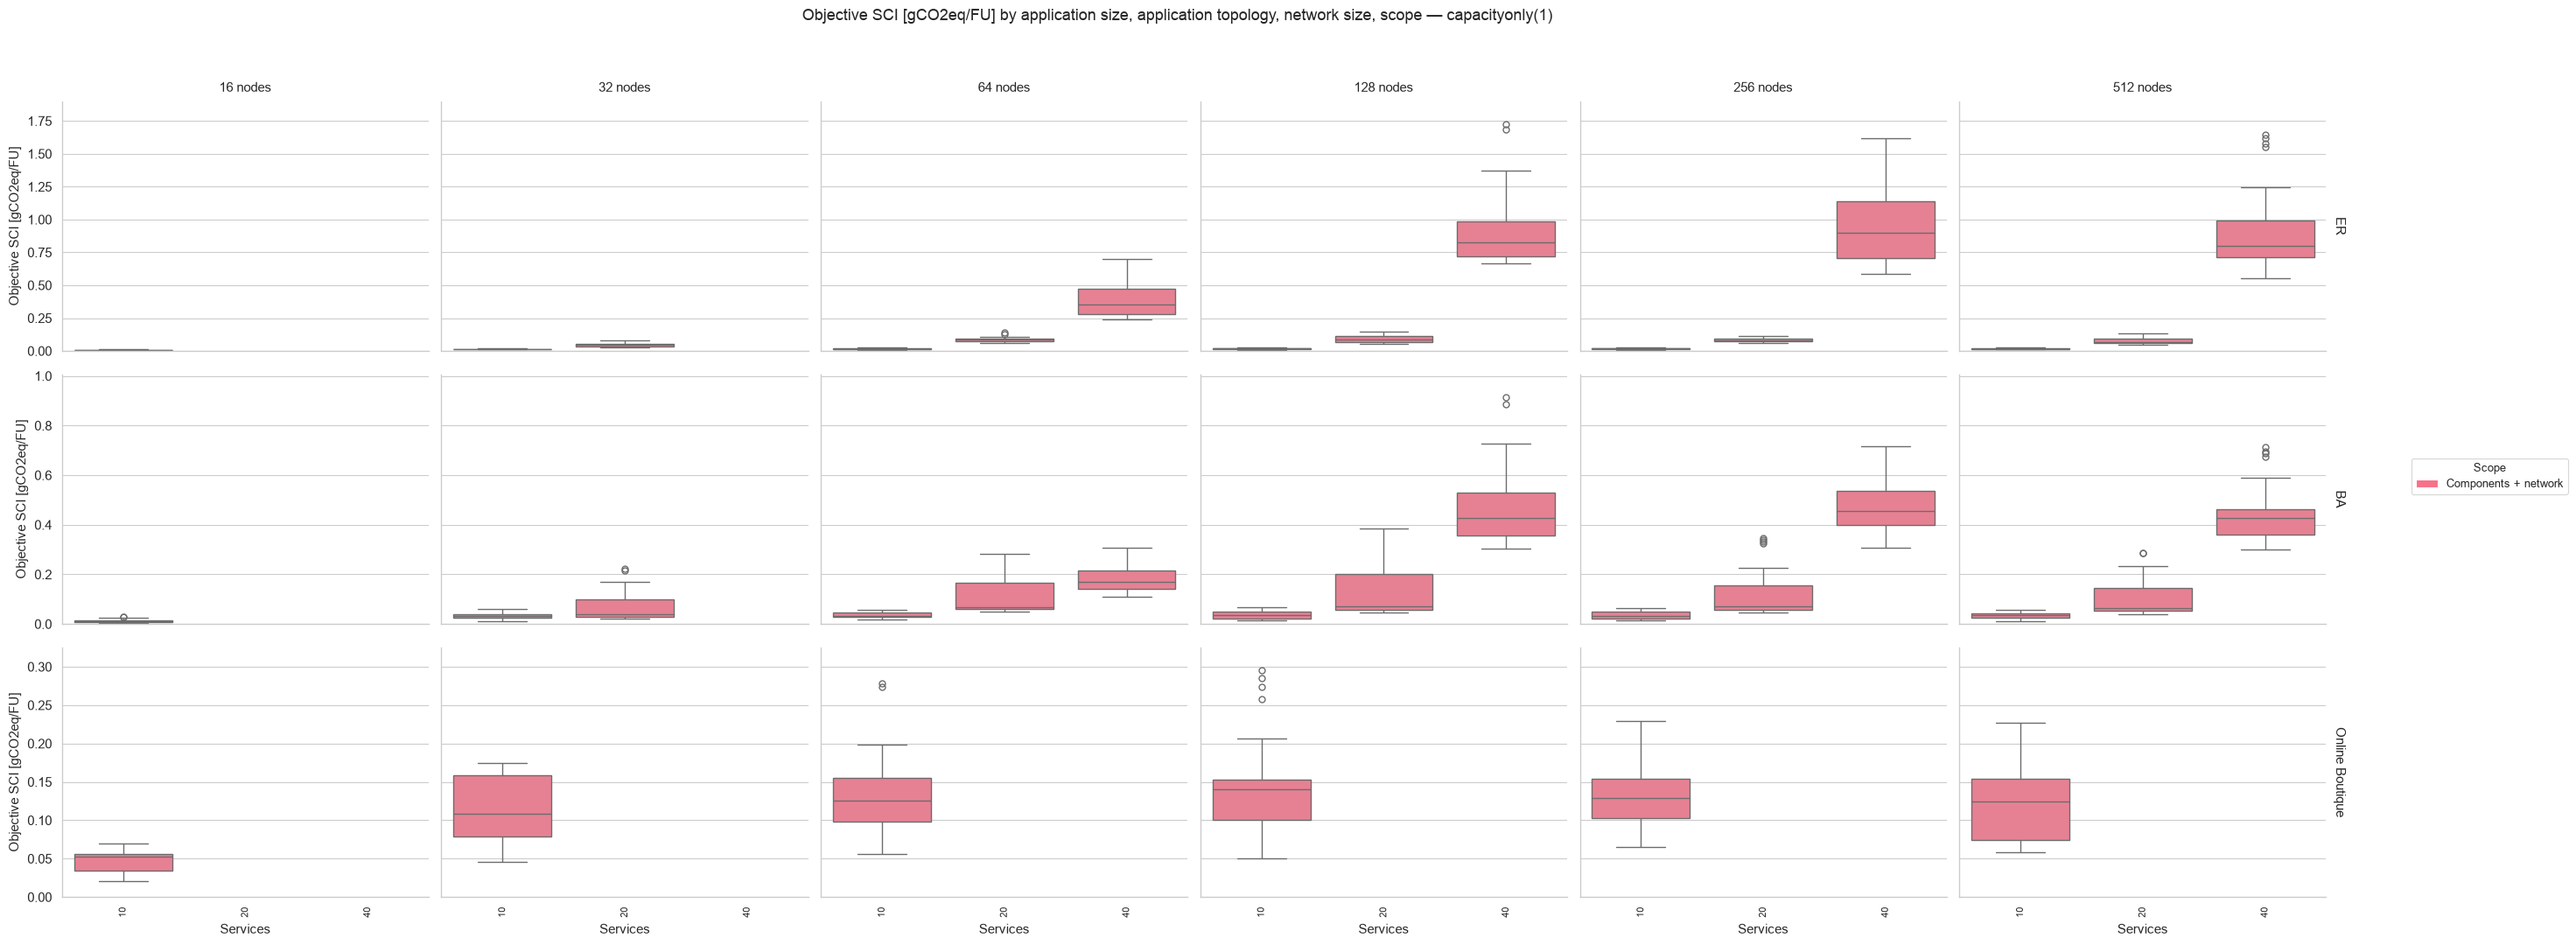

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-capacityonly-1.pdf


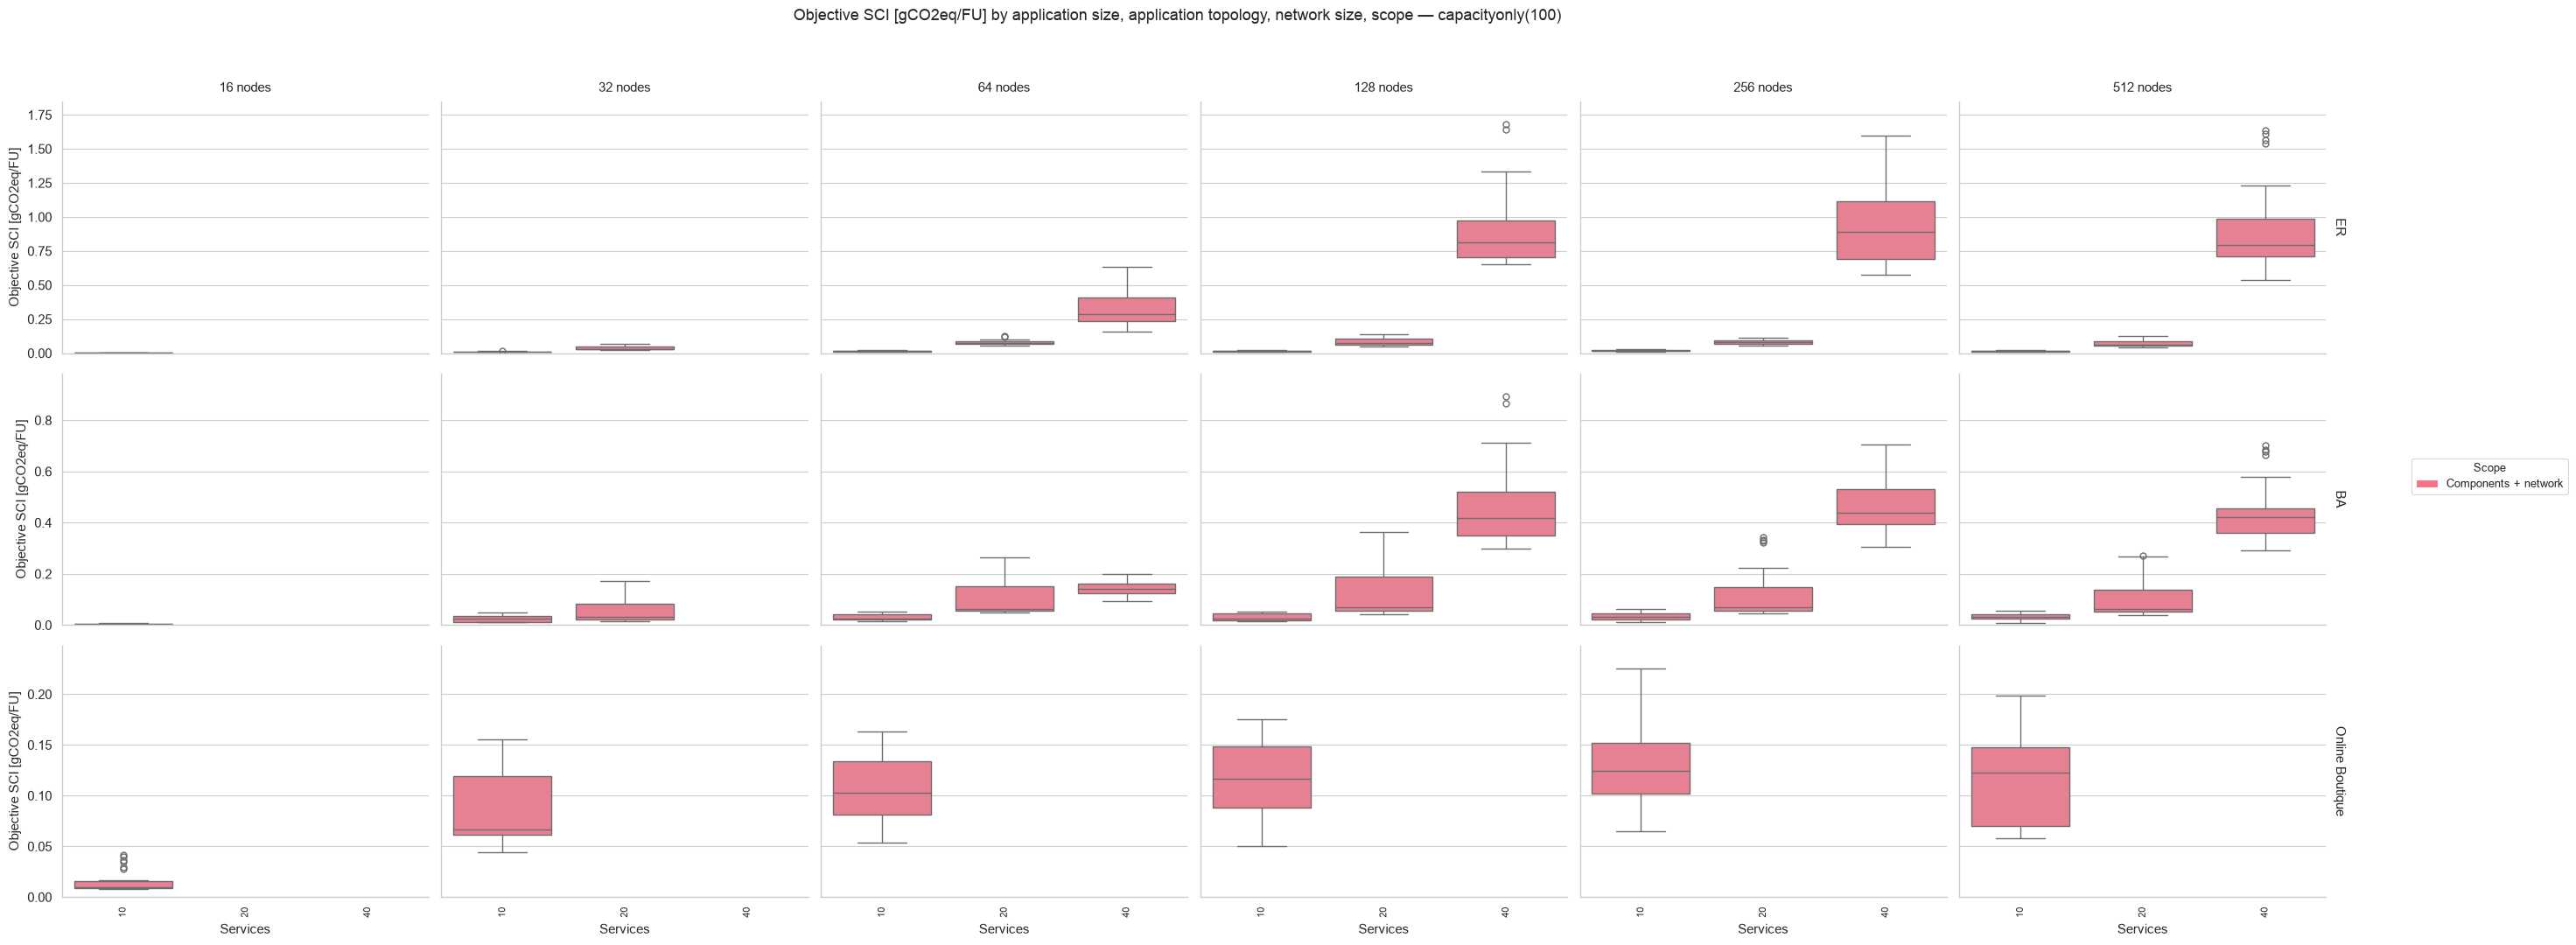

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-capacityonly-100.pdf


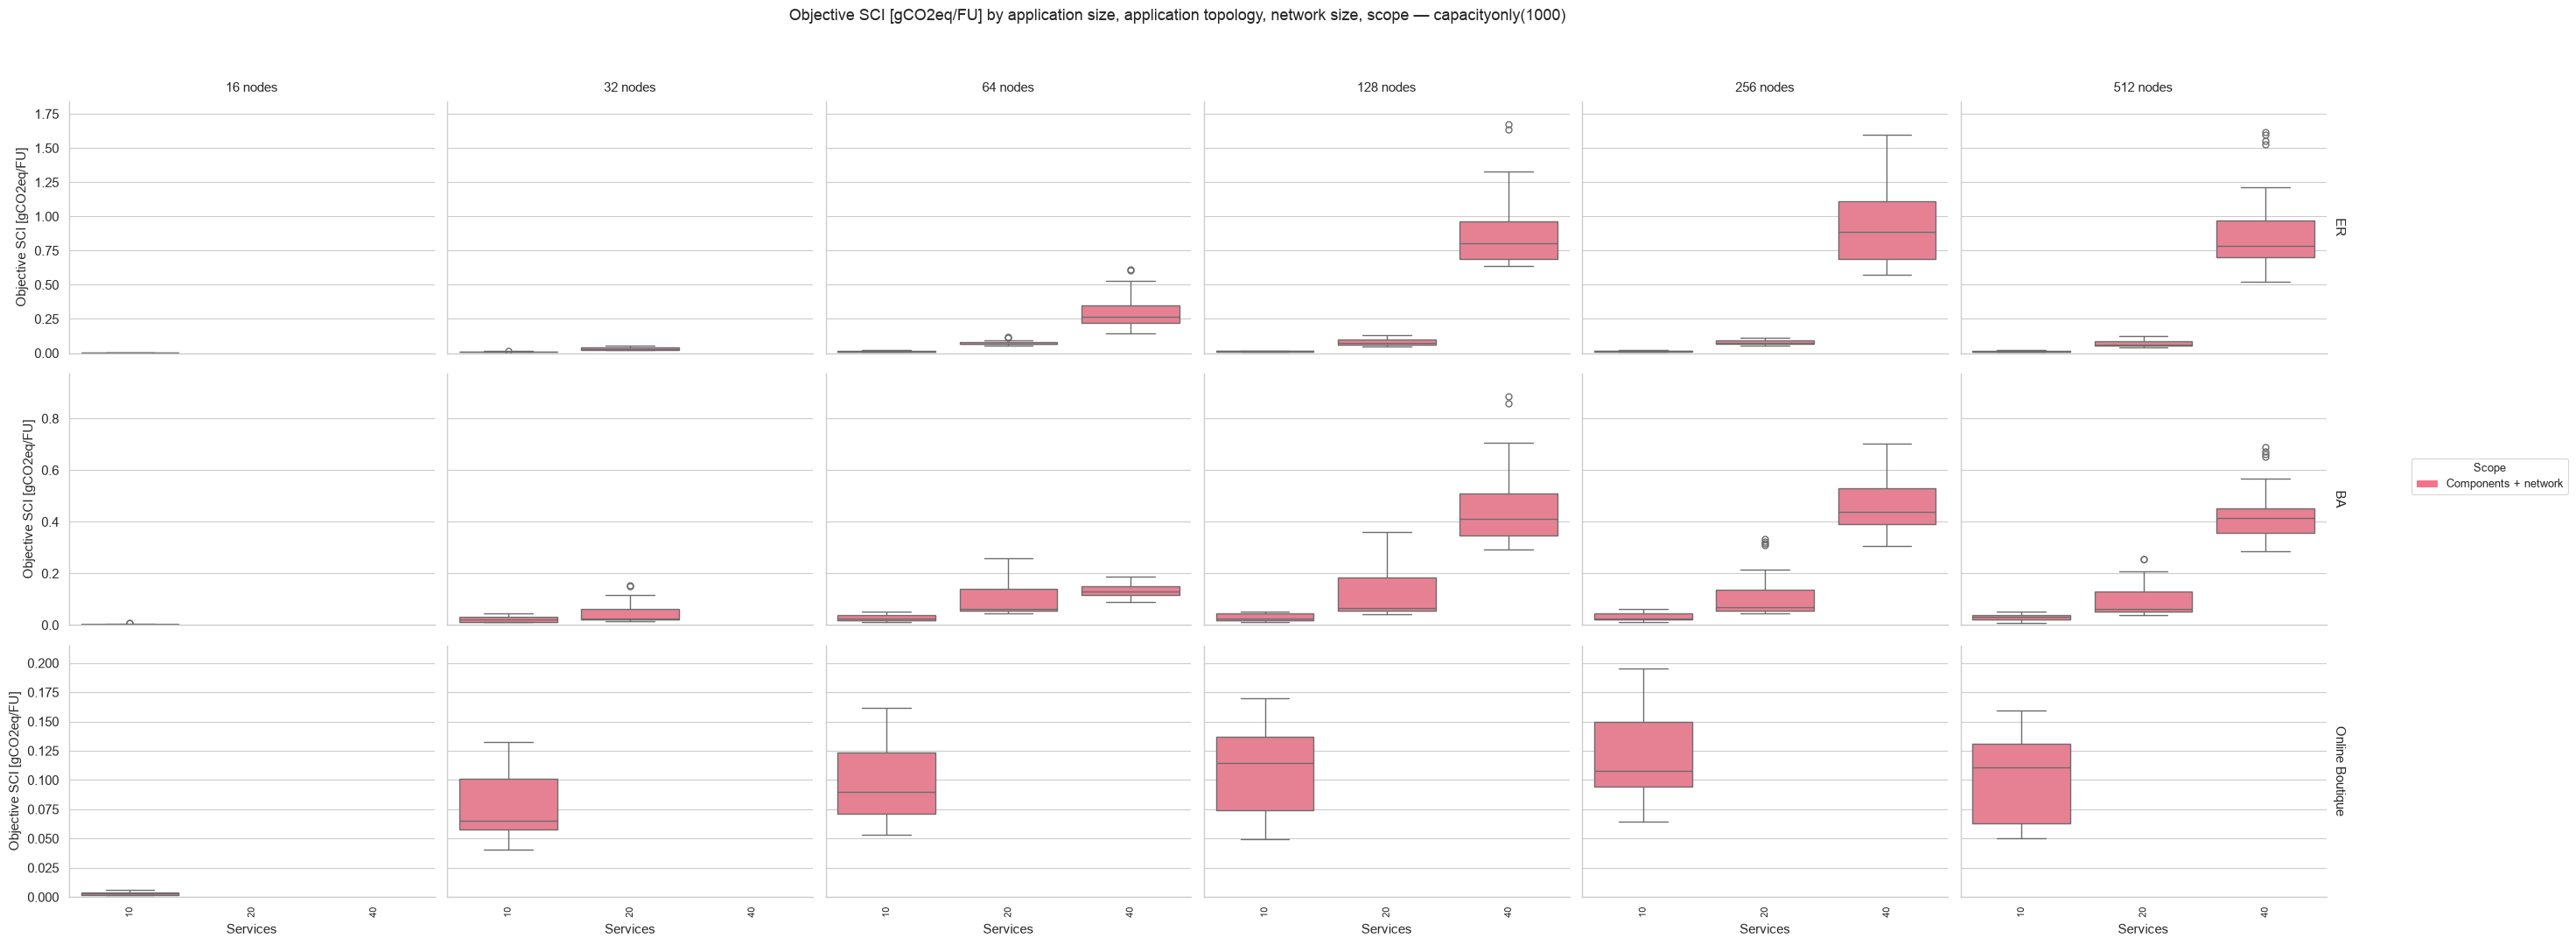

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-capacityonly-1000.pdf


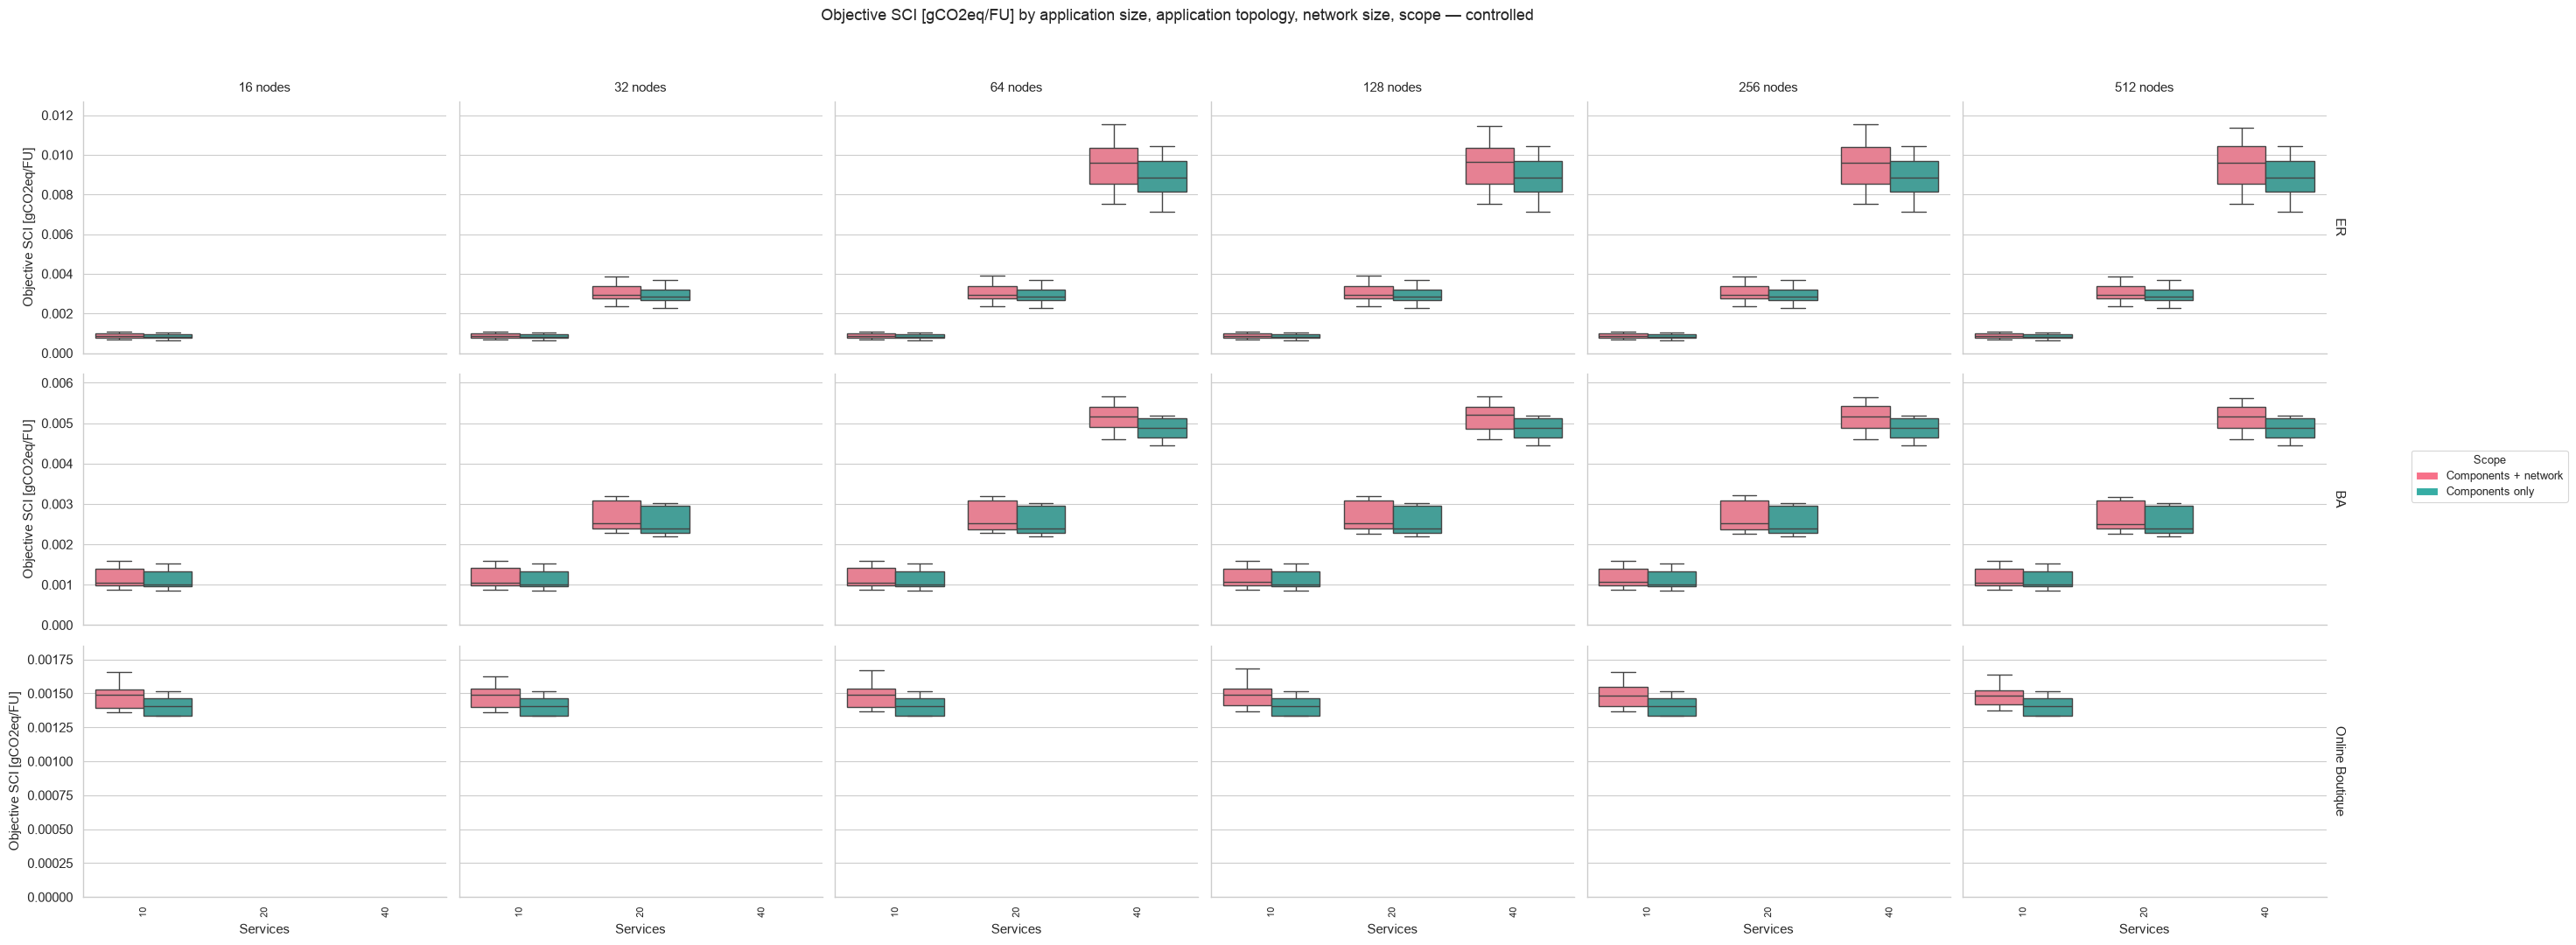

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-controlled.pdf


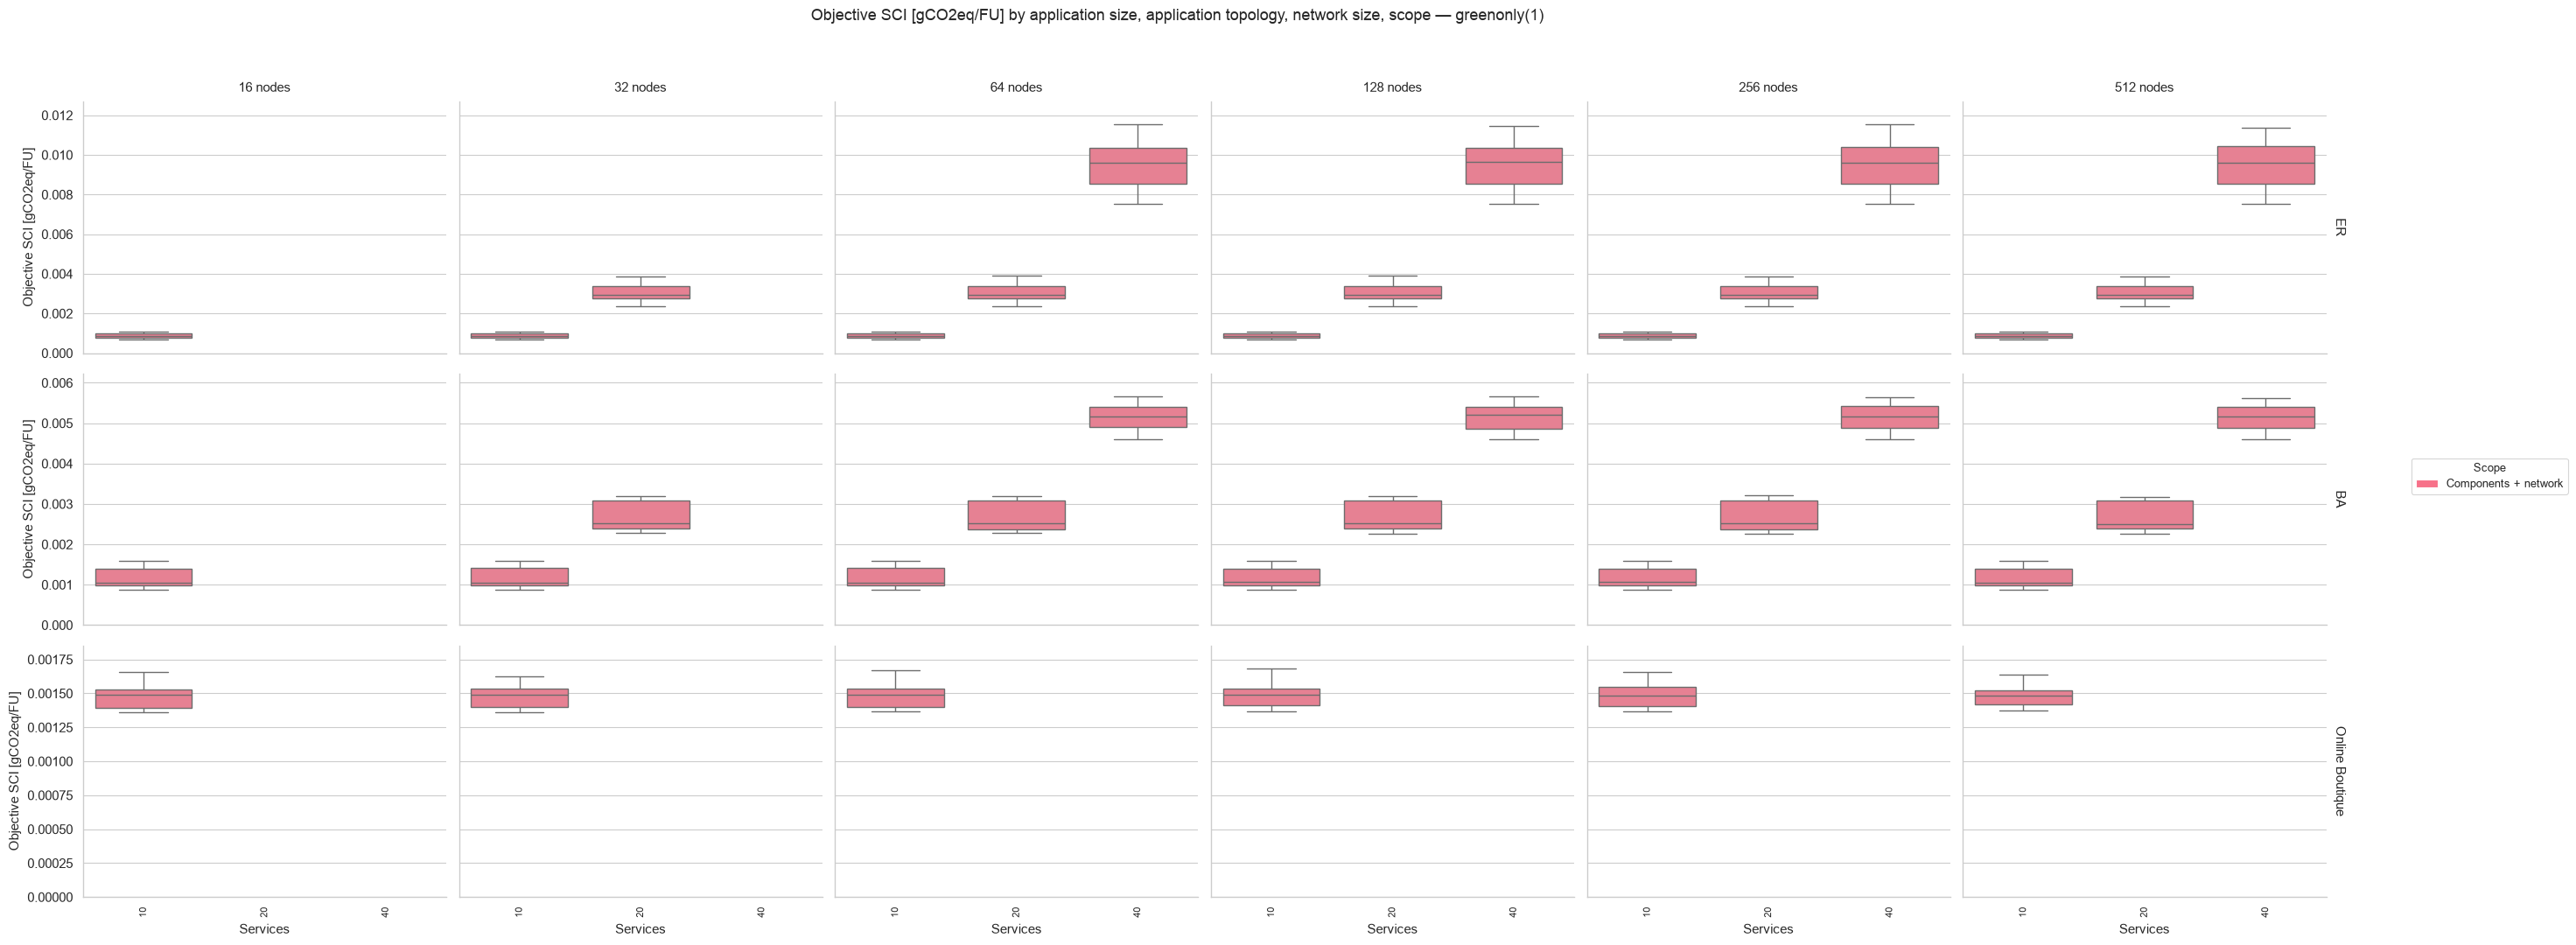

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-greenonly-1.pdf


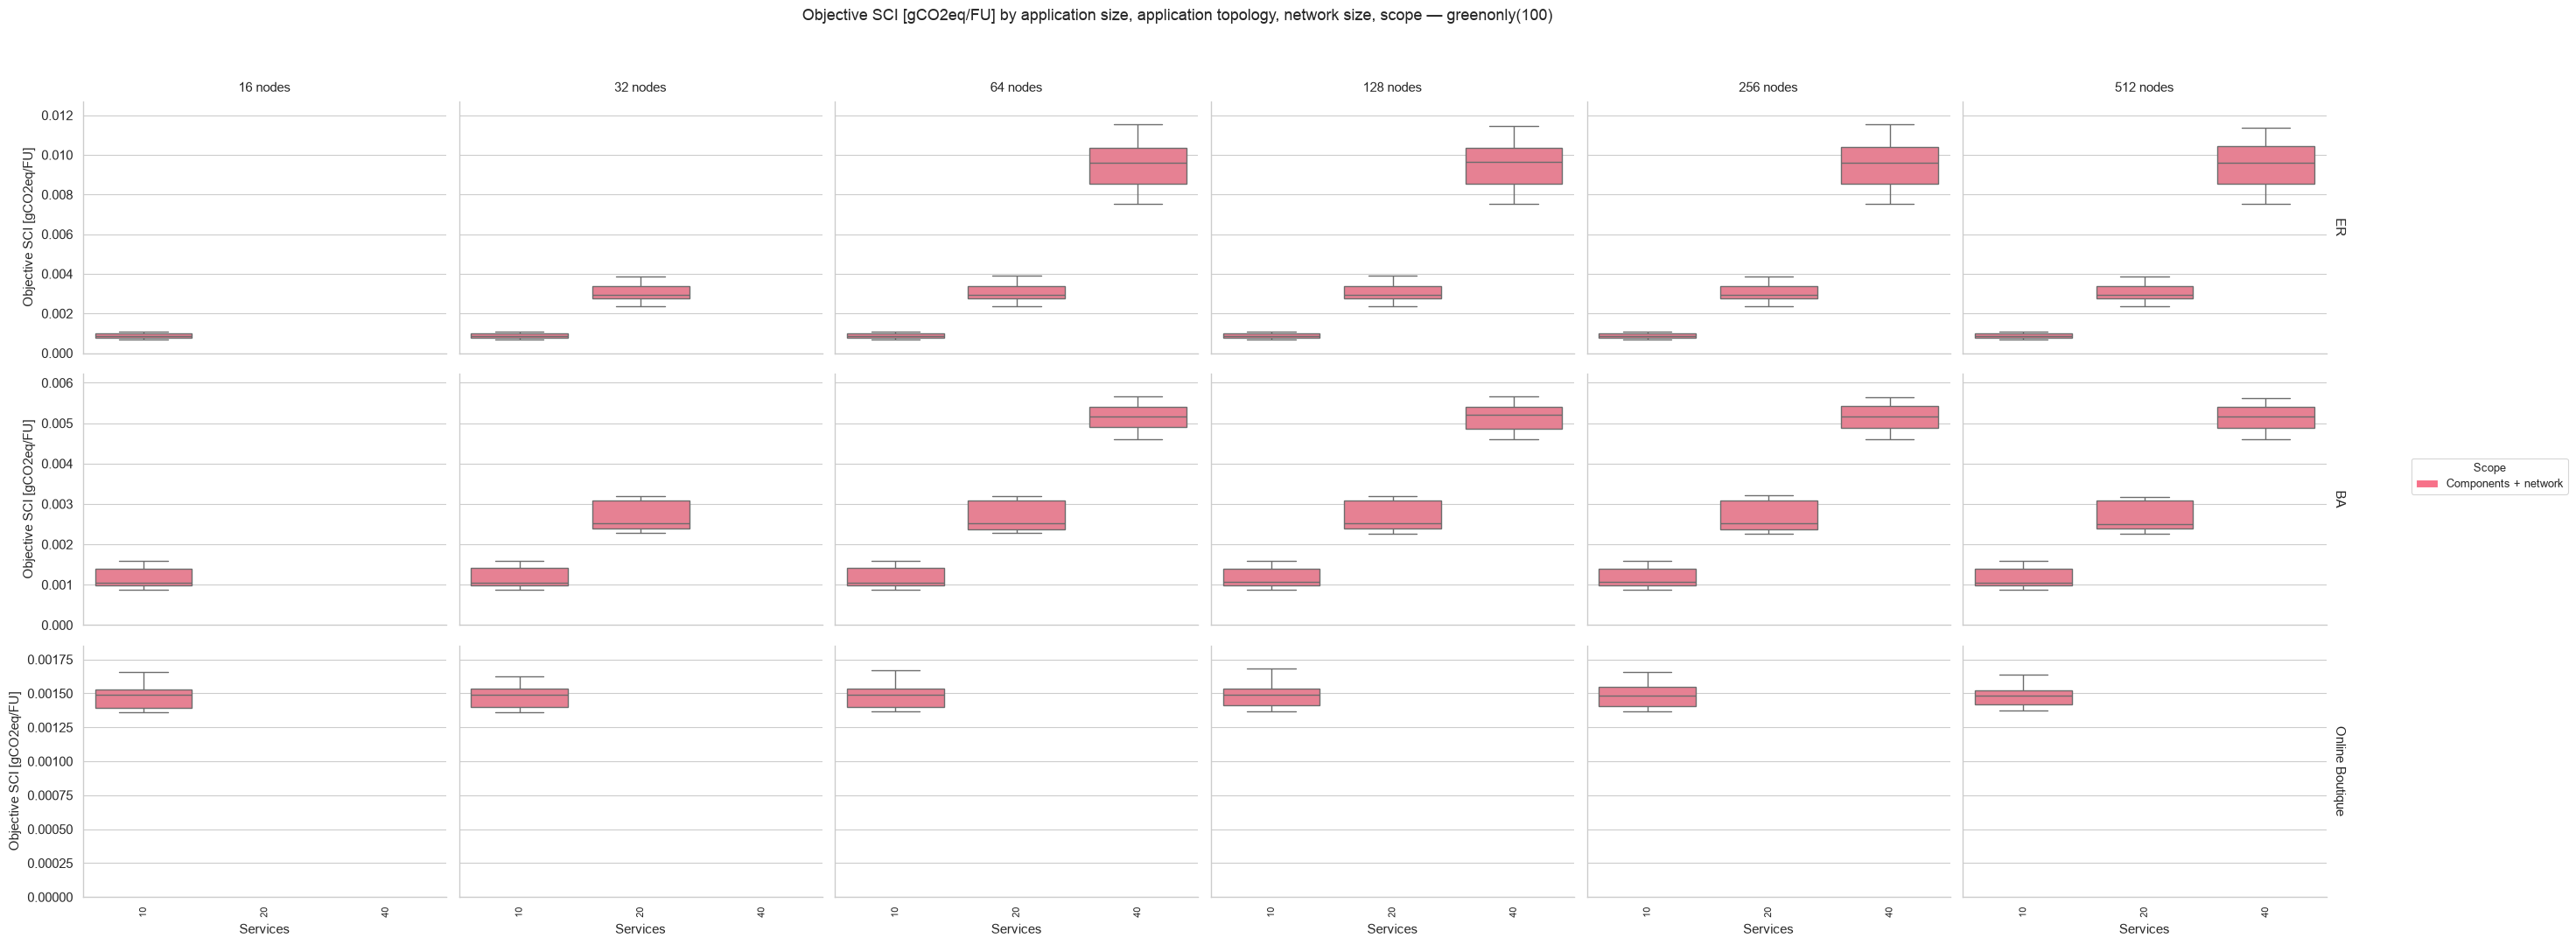

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-greenonly-100.pdf


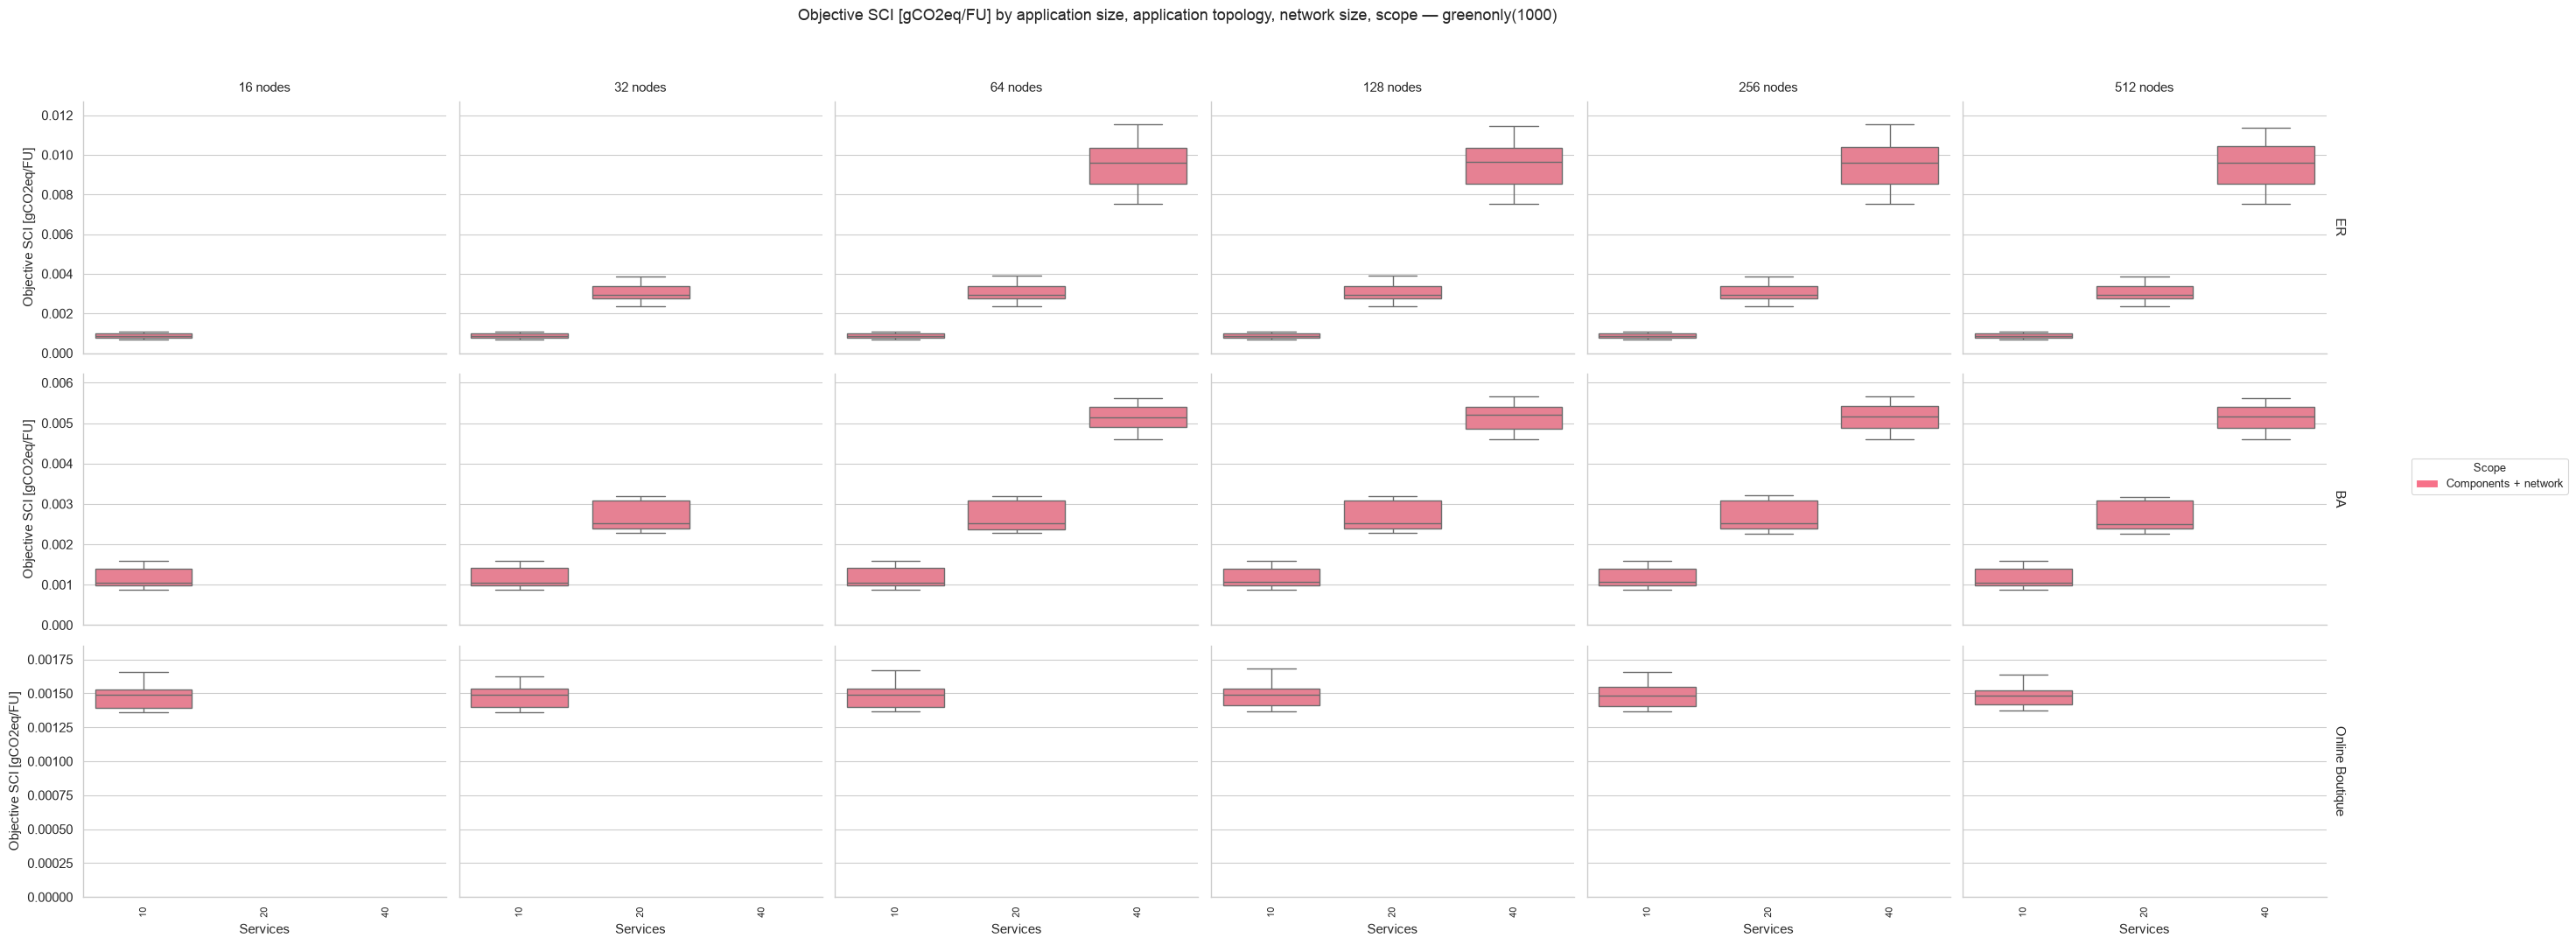

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-greenonly-1000.pdf


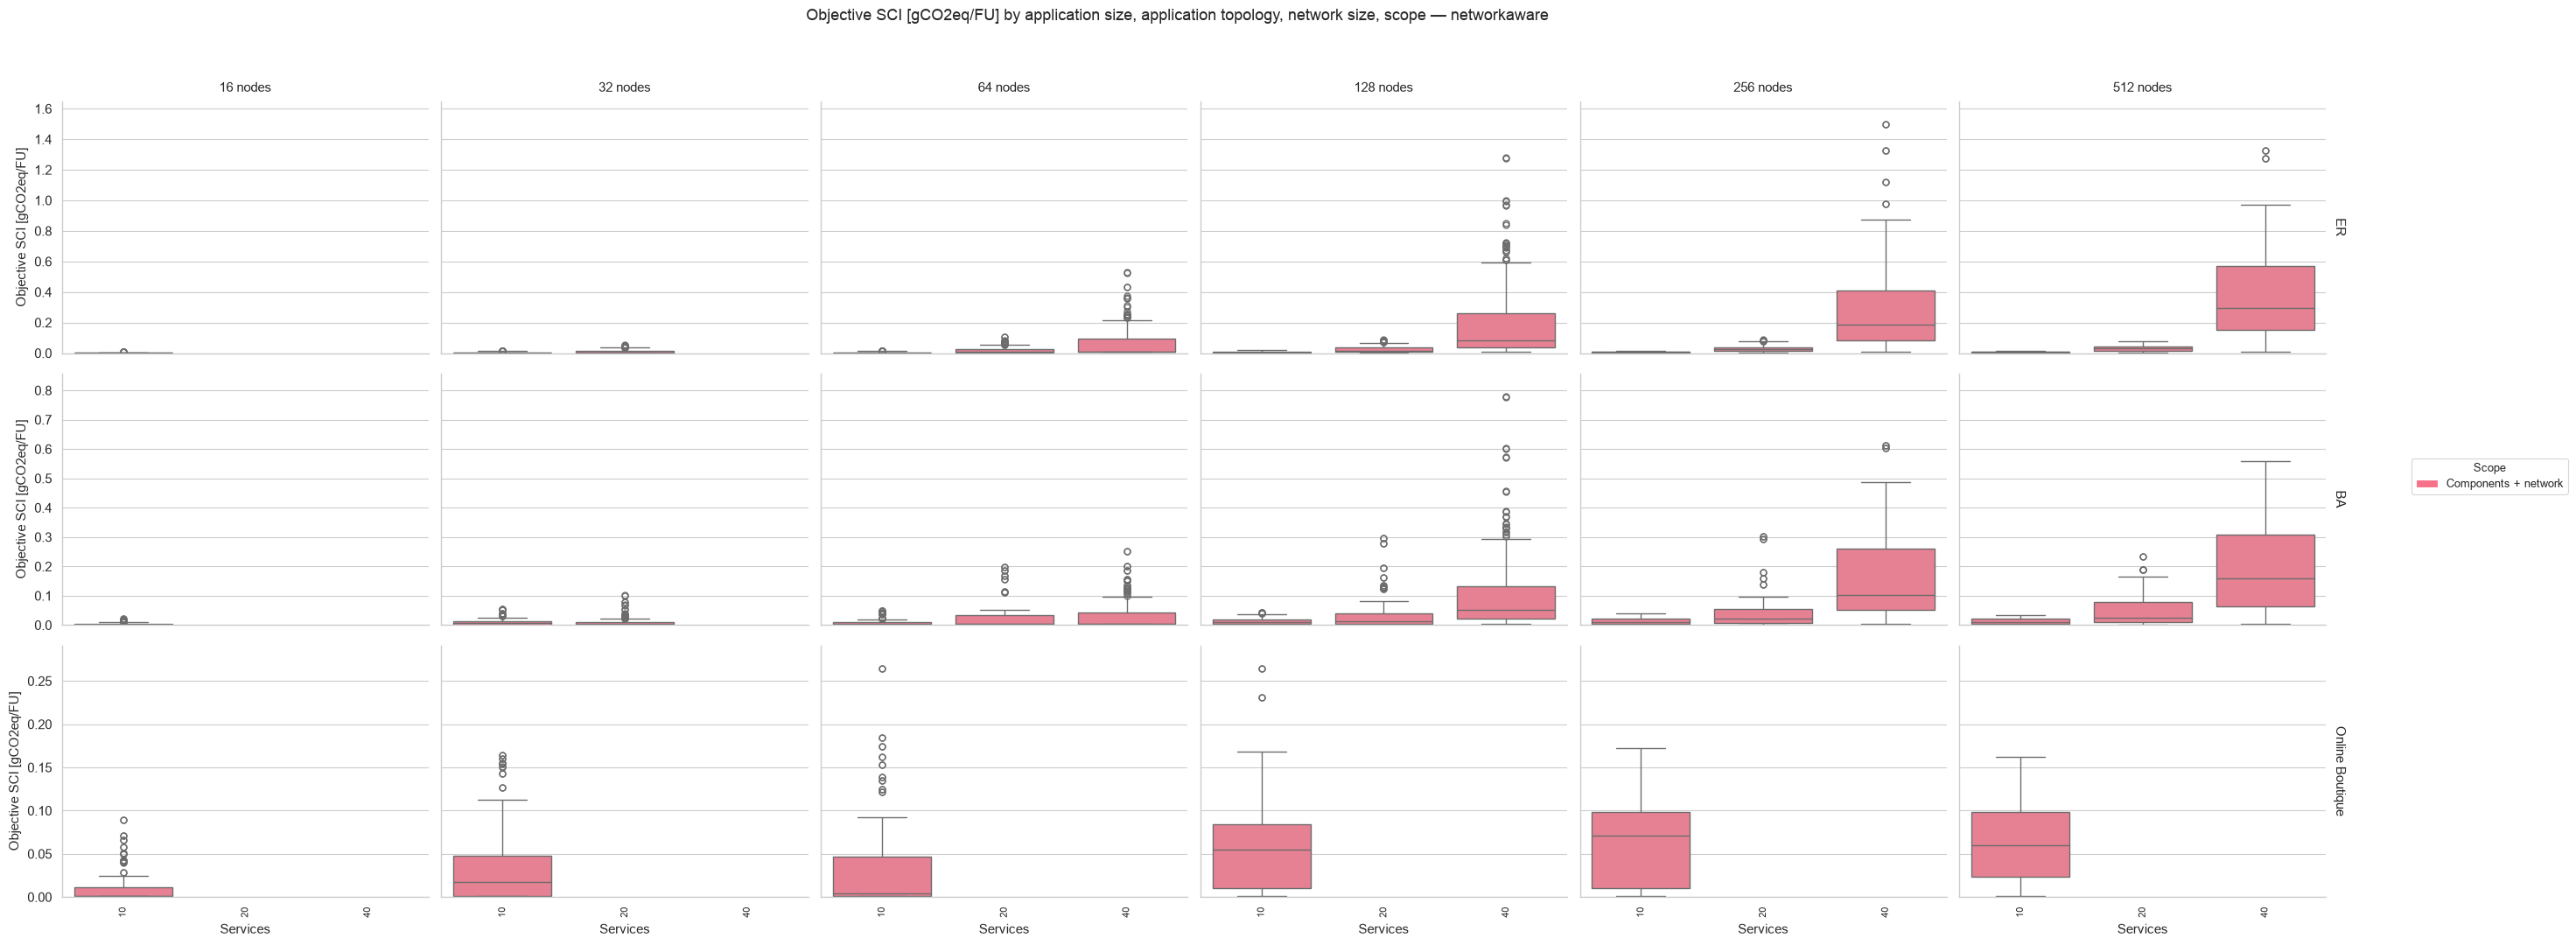

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-networkaware.pdf


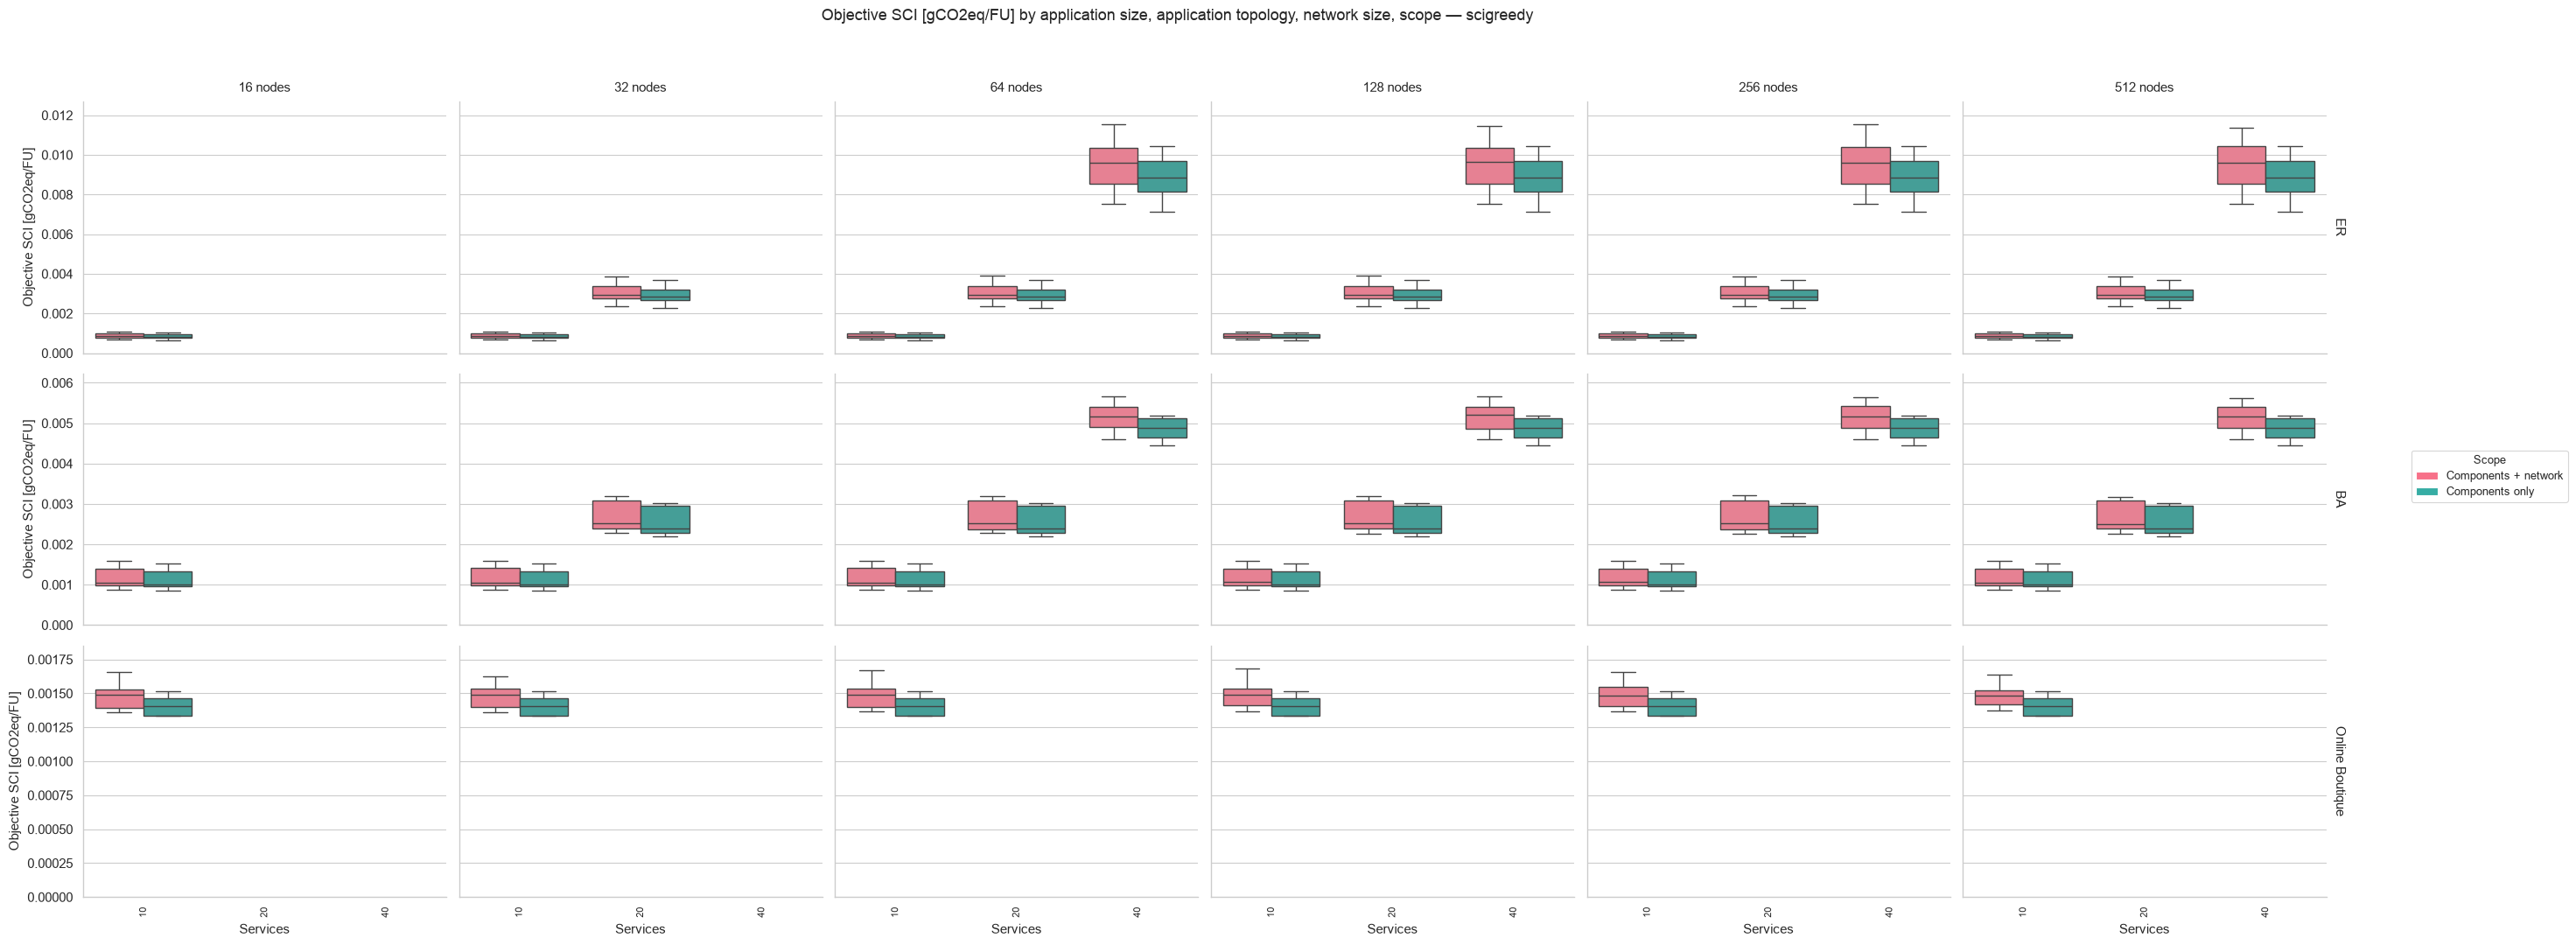

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-scigreedy.pdf


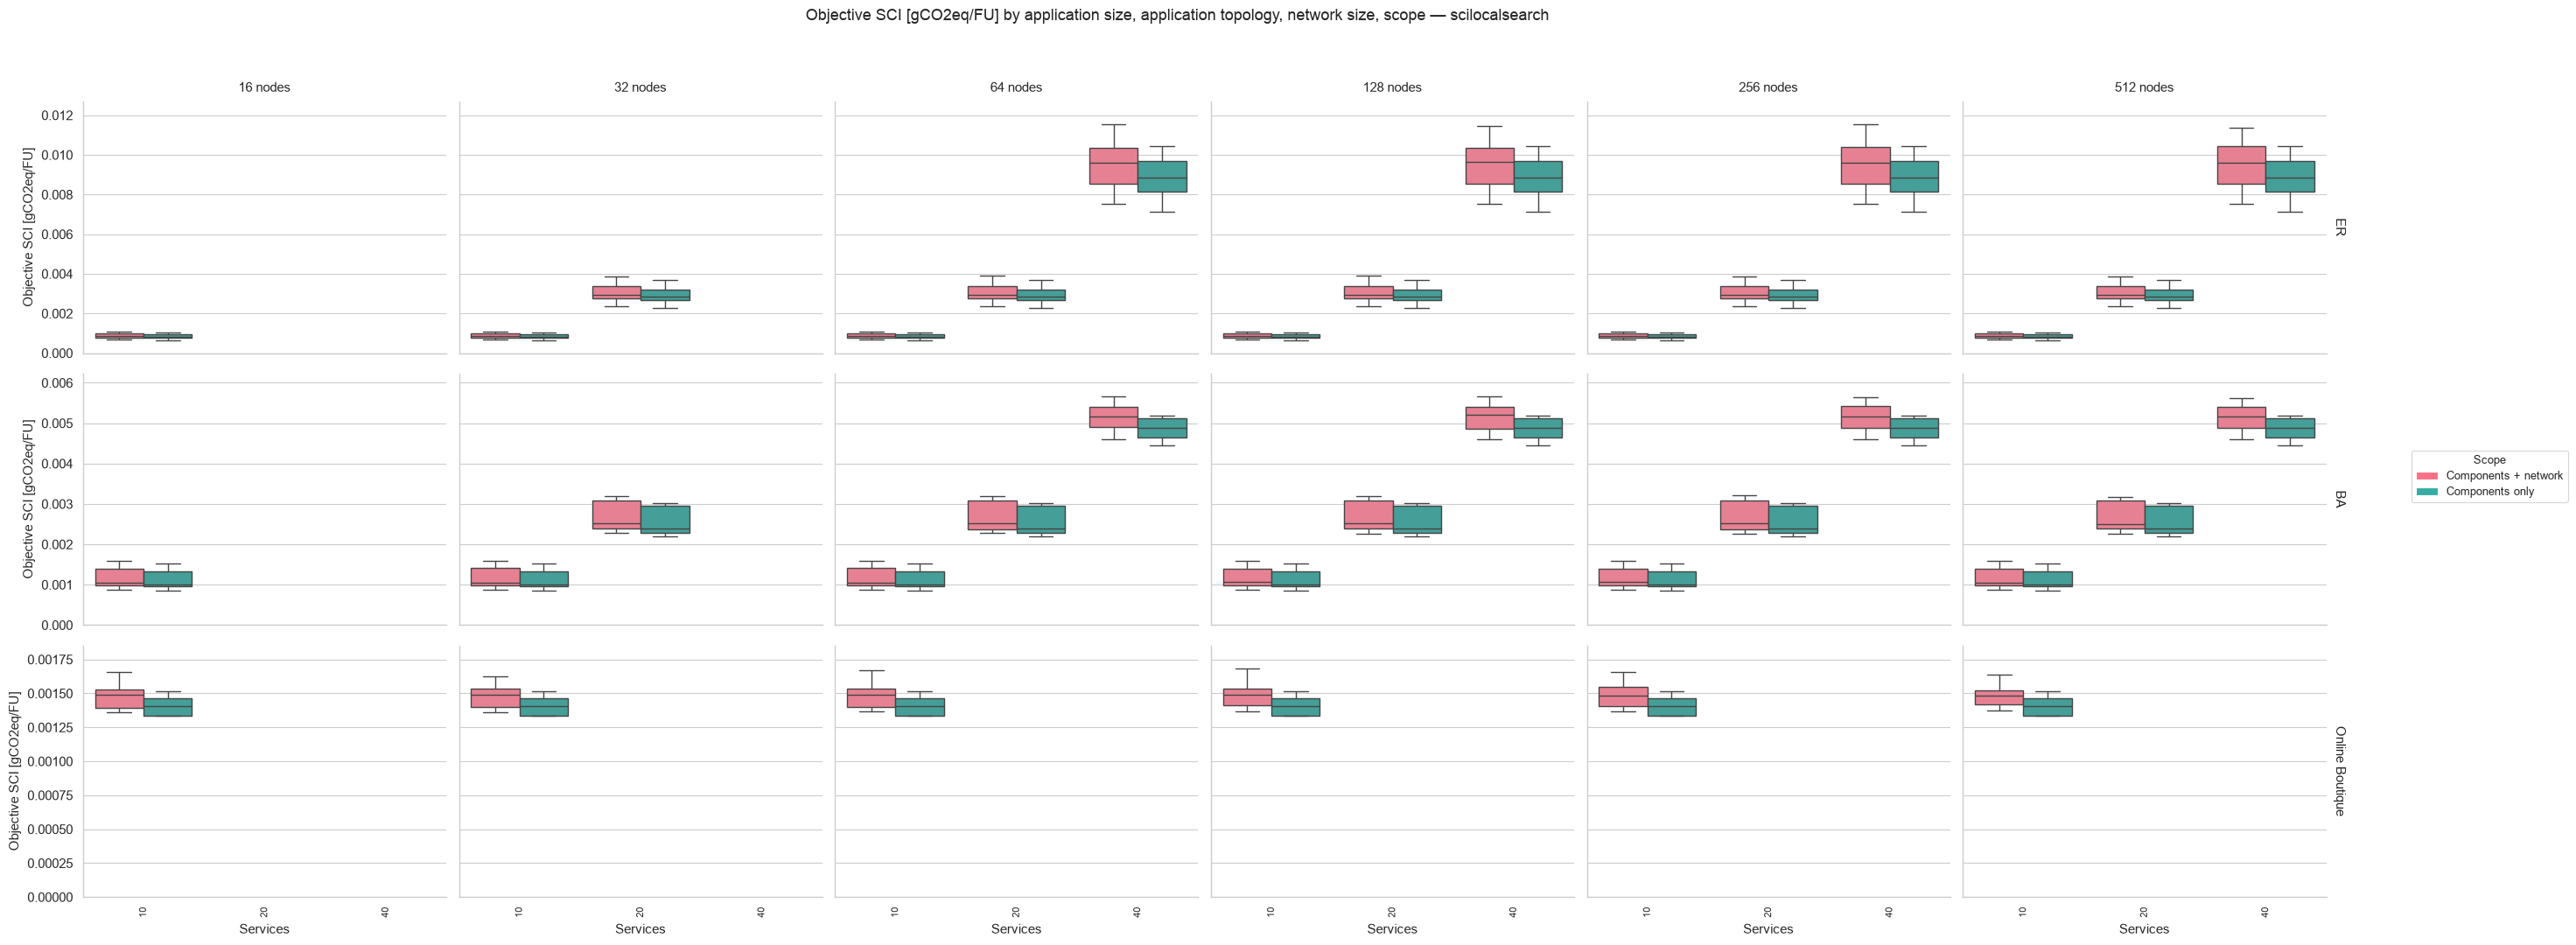

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/scope-comparison-scilocalsearch.pdf


In [90]:
for heuristic, subset in data.groupby("heuristic_plot", sort=True):
    slug = heuristic.replace("(", "-").replace(")", "").replace(", ", "-")
    facet_plot(subset, "objective_sci_g", "Objective SCI [gCO2eq/FU]",
               f"scope-comparison-{slug}", x="application_size", hue="scope_label",
               row="app_topology", col="infrastructure_size")


## Top-k search

Each panel isolates capacity-only or green-only and one application size. K is numeric and ordered; colour distinguishes scopes. All network scenarios and seeds are pooled unless filtered above.


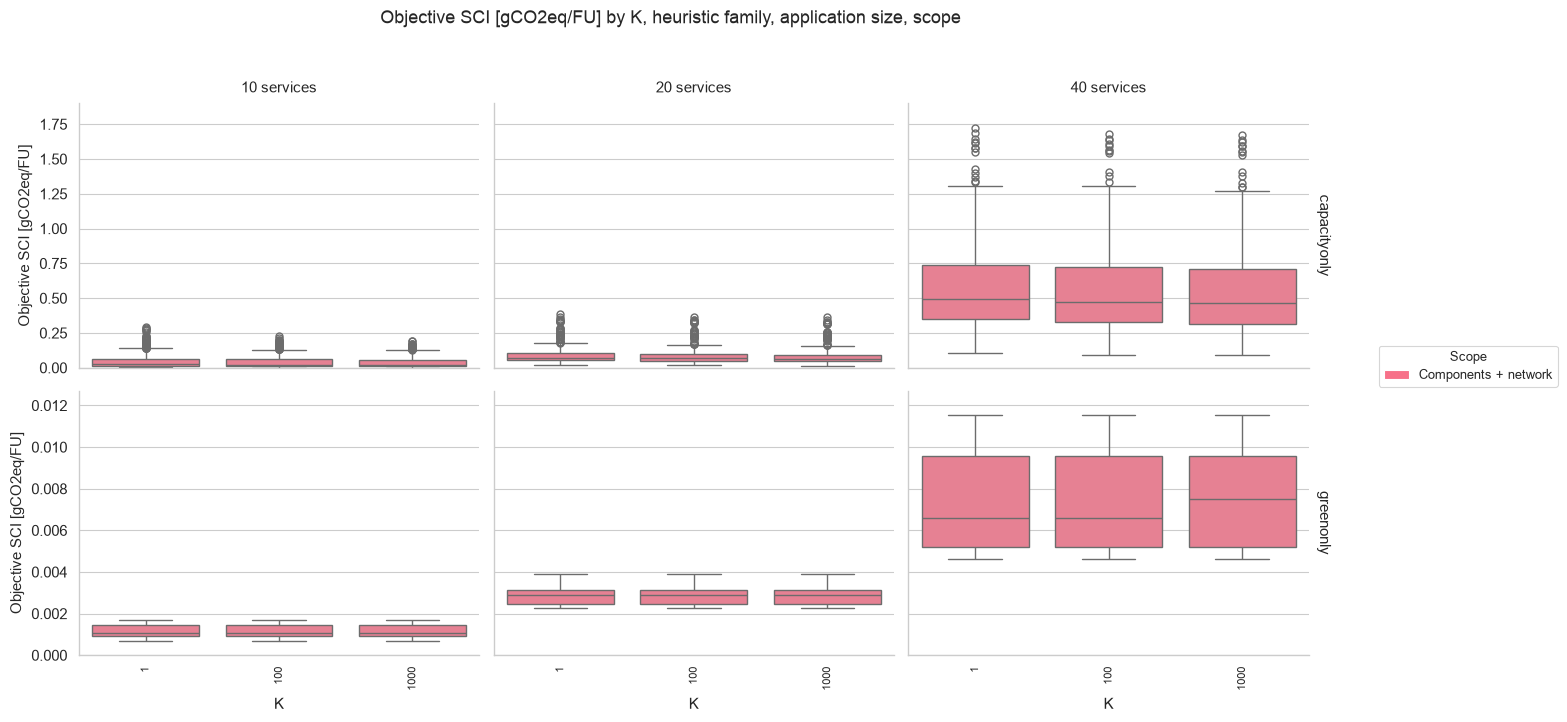

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/topk-sci.pdf


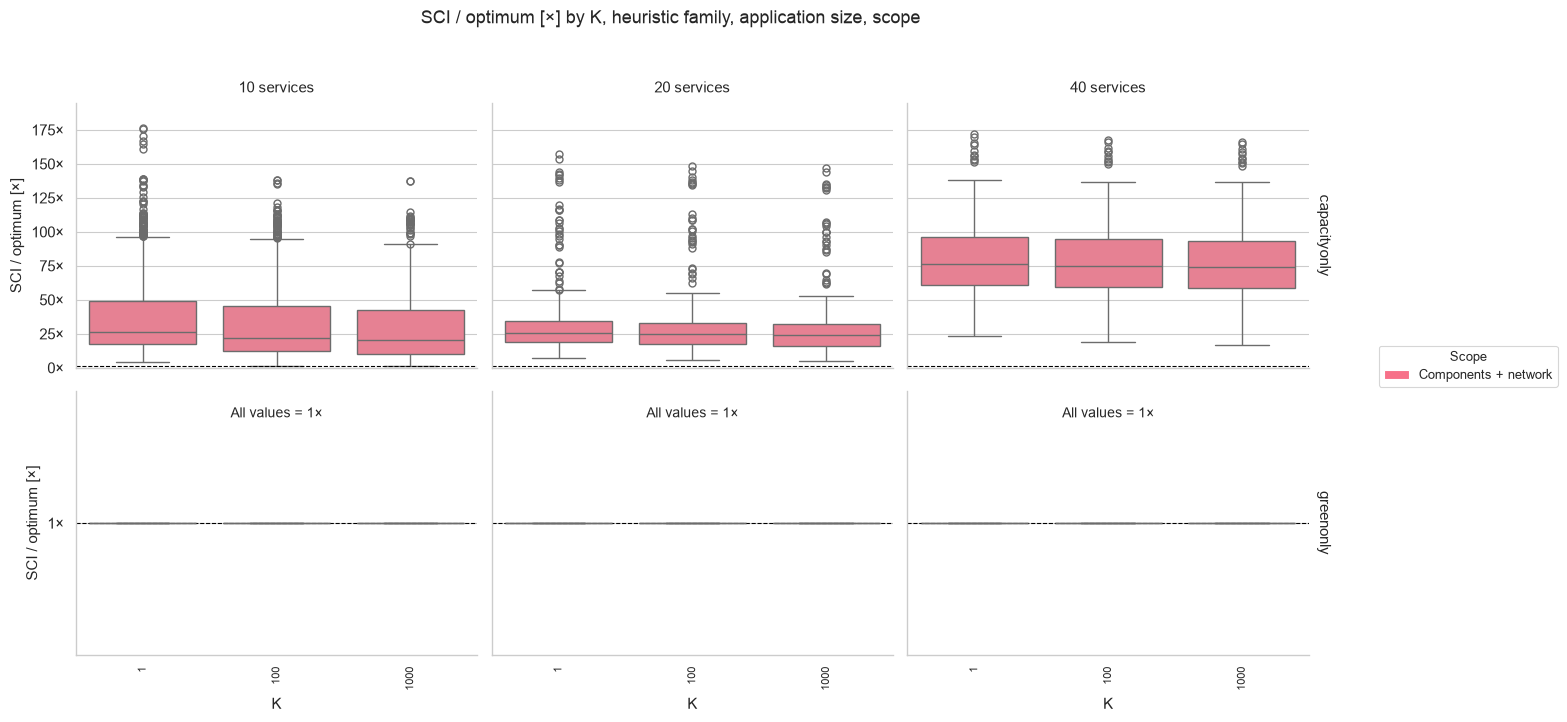

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/topk-gap-ratio.pdf


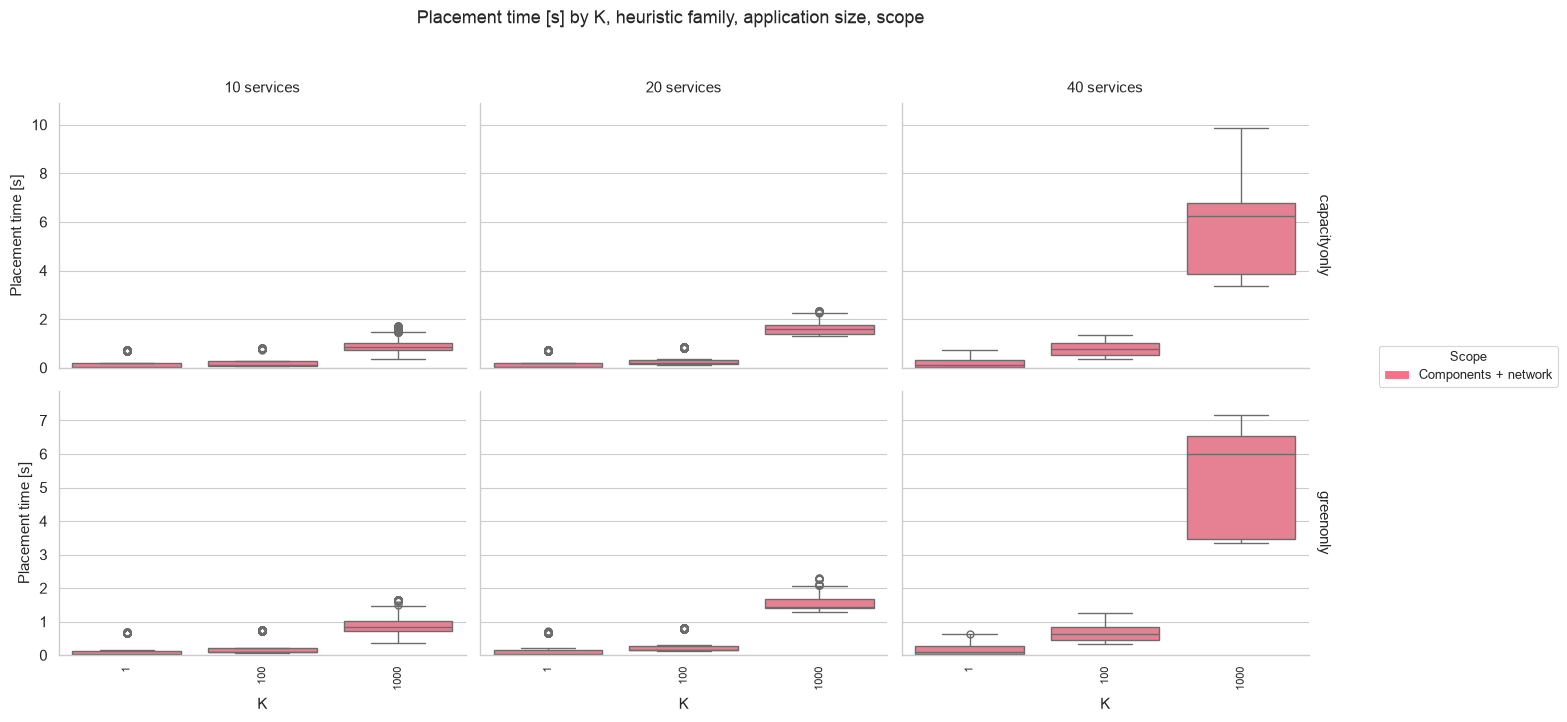

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/topk-runtime.pdf


In [91]:
topk = data.loc[data["top_k"].notna()].copy()
topk["top_k"] = topk["top_k"].astype(int)
for metric, label, name in [
    ("objective_sci_g", "Objective SCI [gCO2eq/FU]", "topk-sci"),
    ("optimality_comparison", OPTIMALITY_LABEL, f"topk-gap-{OPTIMALITY_DISPLAY}"),
    ("time", "Placement time [s]", "topk-runtime"),
]:
    subset = topk.loc[topk[metric].notna()]
    facet_plot(subset, metric, label, name, x="top_k", hue="scope_label",
               row="heuristic_name", col="application_size")


## Network-aware weights

Weight combinations are displayed separately, using the full heuristic name. Panels split network topology and size.


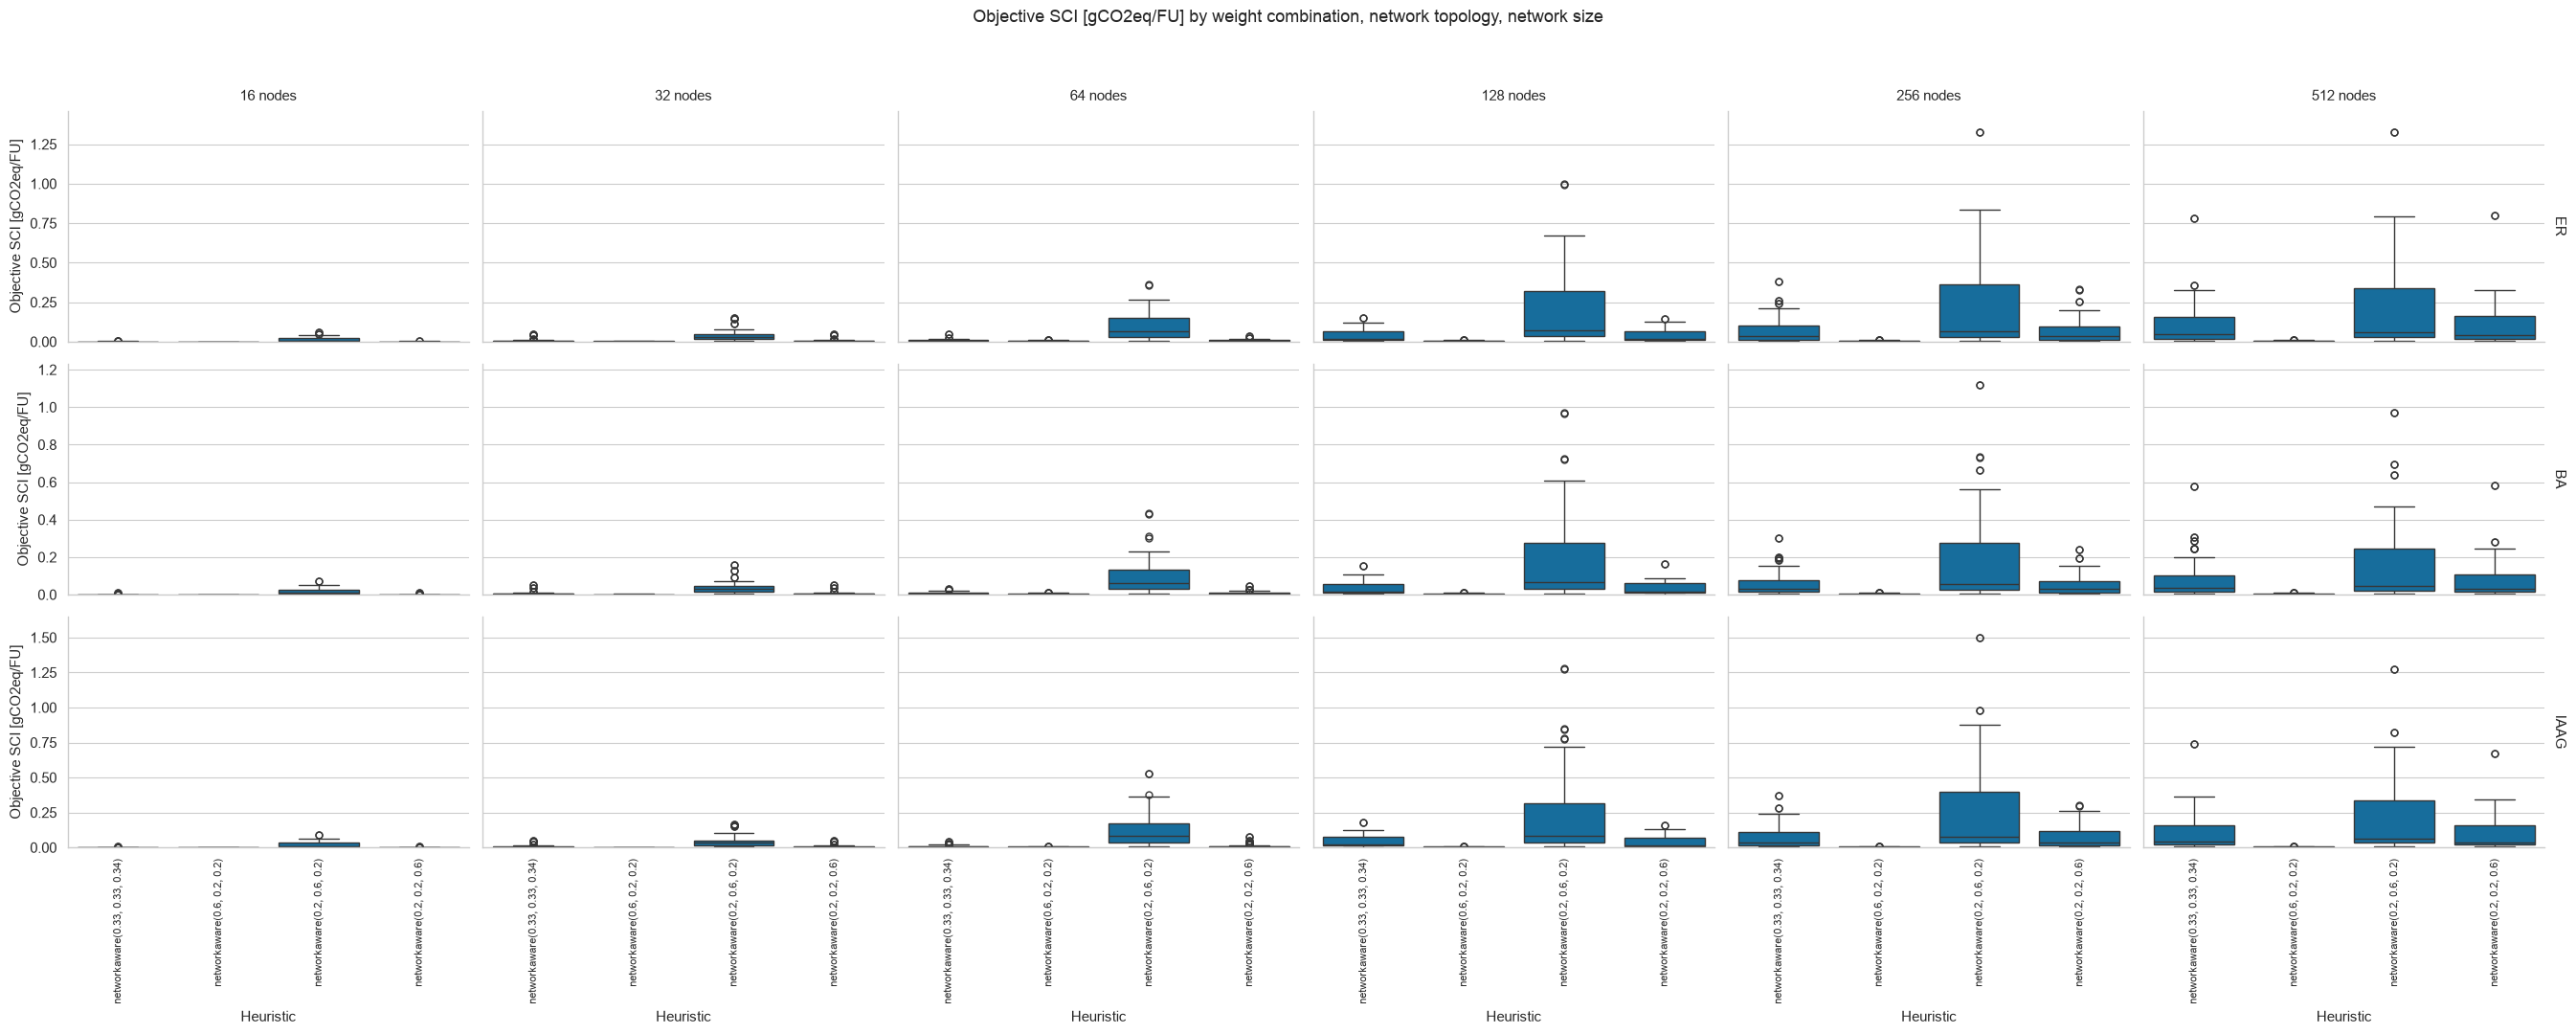

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/network-weights-sci.pdf


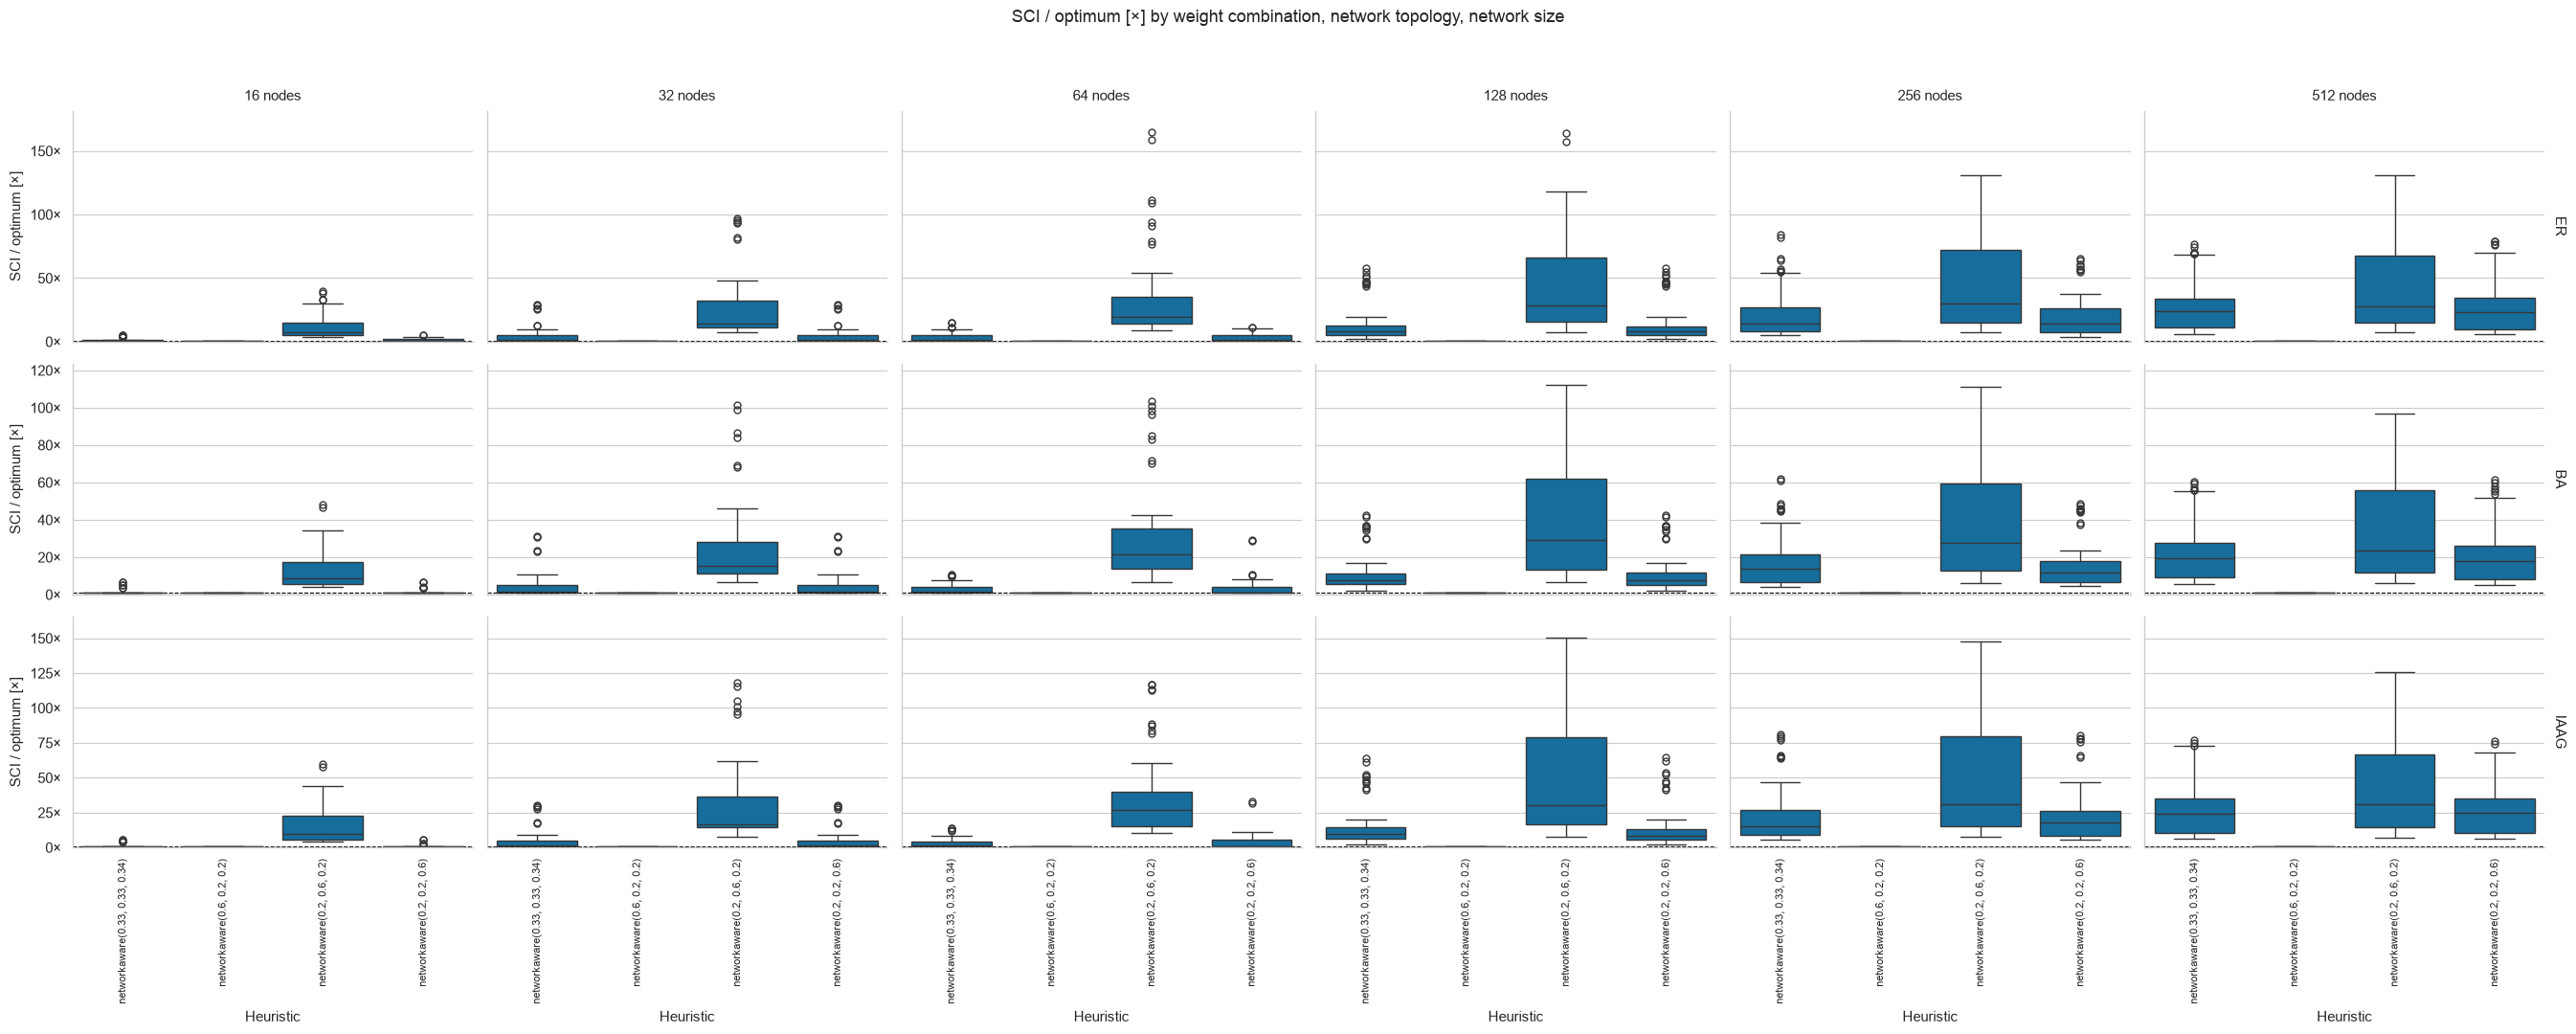

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/network-weights-gap-ratio.pdf


In [92]:
weighted = data.loc[data["heuristic_name"] == "networkaware"]
for metric, label, name in [
    ("objective_sci_g", "Objective SCI [gCO2eq/FU]", "network-weights-sci"),
    ("optimality_comparison", OPTIMALITY_LABEL, f"network-weights-gap-{OPTIMALITY_DISPLAY}"),
]:
    facet_plot(weighted.loc[weighted[metric].notna()], metric, label, name,
               x="heuristic_label", row="network_topology", col="infrastructure_size")


## Measured SCI and known optimum

Compare actual SCI values with the corresponding optimum, rather than percentages. Each trial contributes one measured and one reference value. This section is skipped for random scenarios.


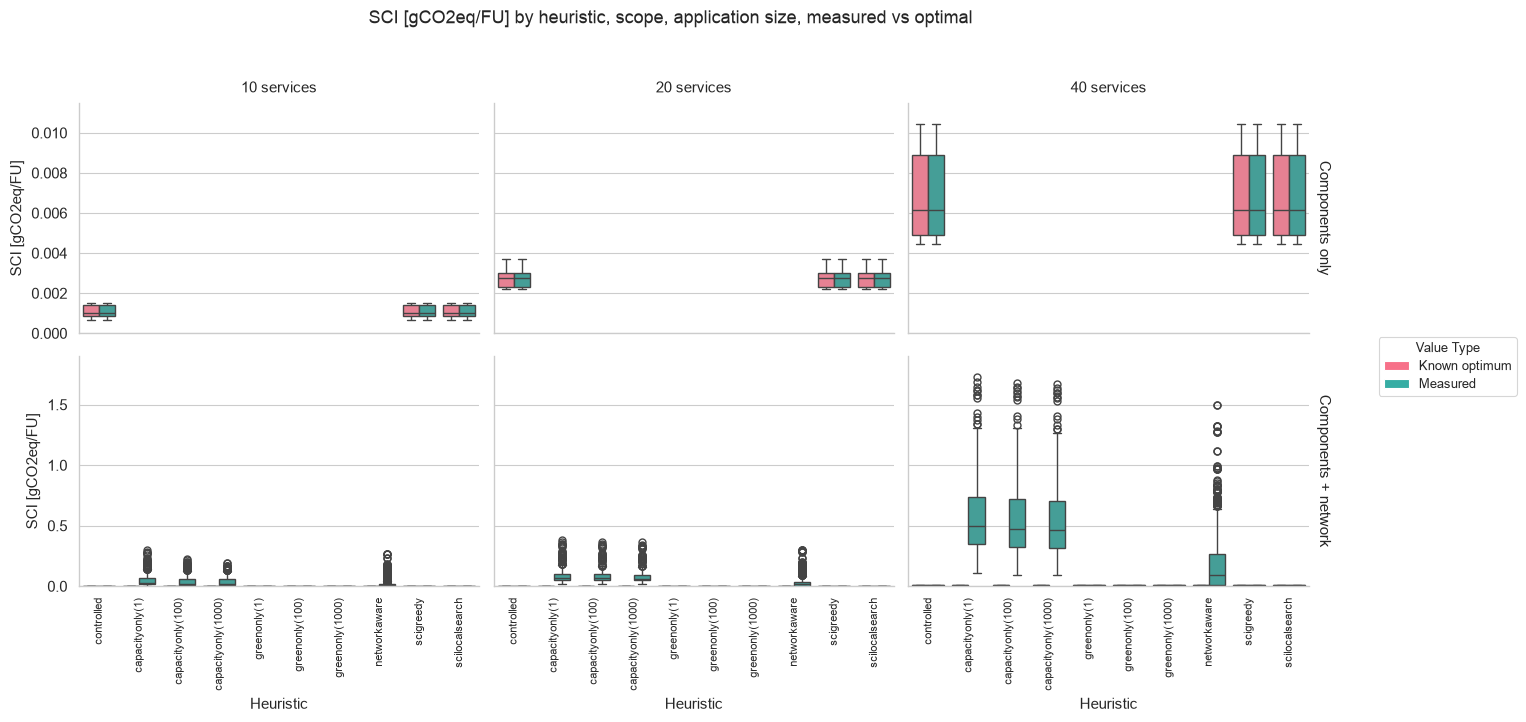

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/measured-vs-optimal-values.pdf


In [93]:
references = data.loc[data["optimal_sci"].notna()].copy()
if not references.empty:
    comparisons = references.melt(
        id_vars=["heuristic_plot", "scope_label", "app_topology", "application_size",
                 "network_topology", "infrastructure_size"],
        value_vars=["objective_sci_g", "optimal_sci_g"],
        var_name="value_type", value_name="sci_g",
    )
    comparisons["value_type"] = comparisons["value_type"].map({
        "objective_sci_g": "Measured", "optimal_sci_g": "Known optimum",
    })
    facet_plot(comparisons, "sci_g", "SCI [gCO2eq/FU]", "measured-vs-optimal-values",
               x="heuristic_plot", hue="value_type", row="scope_label",
               col="application_size")


## Component and network contributions

Separate contributions in absolute units, retaining application topology and size.


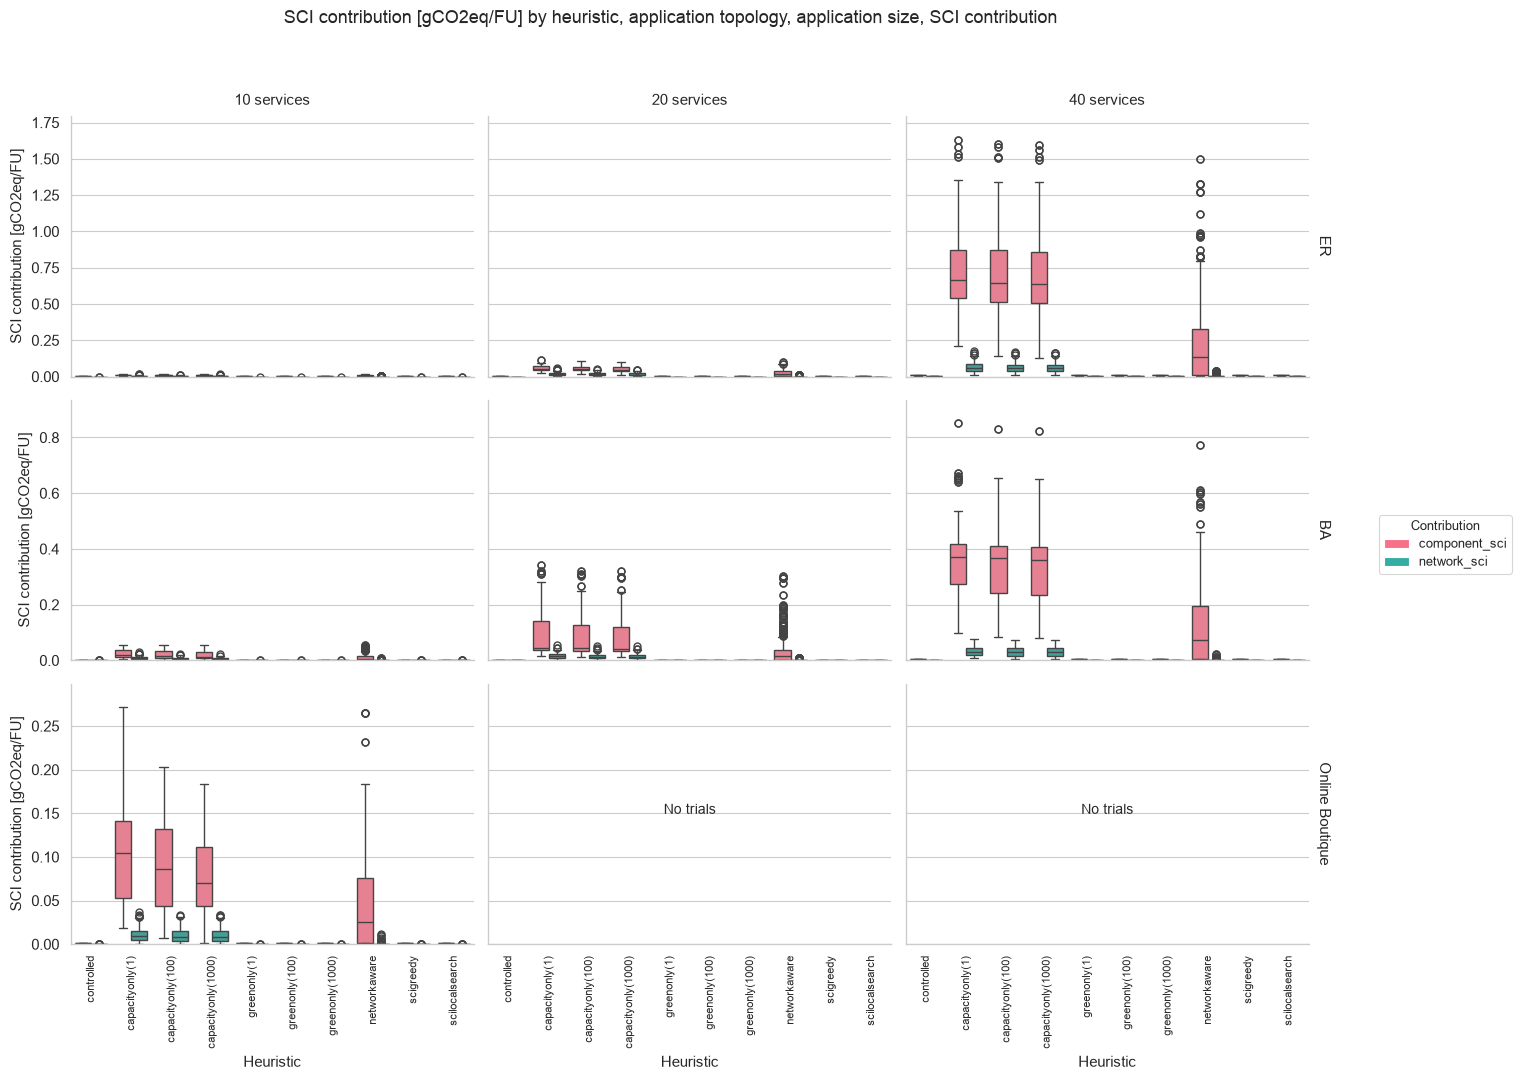

Saved: /Users/jacopomassa/GitHub/sci-aware-msa-placement/results/plots/network-sci-controlled-v2/sci-contributions-by-application.pdf


In [94]:
contributions = data.melt(
    id_vars=["heuristic_plot", "app_topology", "application_size", "scope_label"],
    value_vars=["component_sci", "network_sci"],
    var_name="contribution", value_name="sci_g",
)
contributions["sci_g"] *= 1000
facet_plot(contributions, "sci_g", "SCI contribution [gCO2eq/FU]",
           "sci-contributions-by-application", x="heuristic_plot", hue="contribution",
           row="app_topology", col="application_size")


## Failed trials

Counts split by heuristic variant, network topology and size.


In [95]:
if failed.empty:
    print("No failed trials in the selected dataset.")
else:
    failure_counts = failed.groupby(
        ["heuristic_plot", "infrastructure_topology", "infrastructure_size"],
        dropna=False,
    ).size().rename("failed_trials").reset_index()
    failure_counts["infrastructure_topology"] = failure_counts["infrastructure_topology"].map({
        "erdos_renyi": "ER", "barabasi_albert": "BA", "internet_as_graph": "IAAG",
    })
    facet_plot(failure_counts, "failed_trials", "Failed trials", "failures-by-infrastructure",
               x="heuristic_plot", row="infrastructure_topology", col="infrastructure_size")


No failed trials in the selected dataset.
